<h1 align="center"><b>Hands-on workshop: molecular dynamic analysis.</b></h1>

<p align="center">
⚕ ⏭ ⛏ ⏭ 🎯 ⏭ ⚛ ⏭ 🤖 ⏭ ⚕

---


<p align="center">
  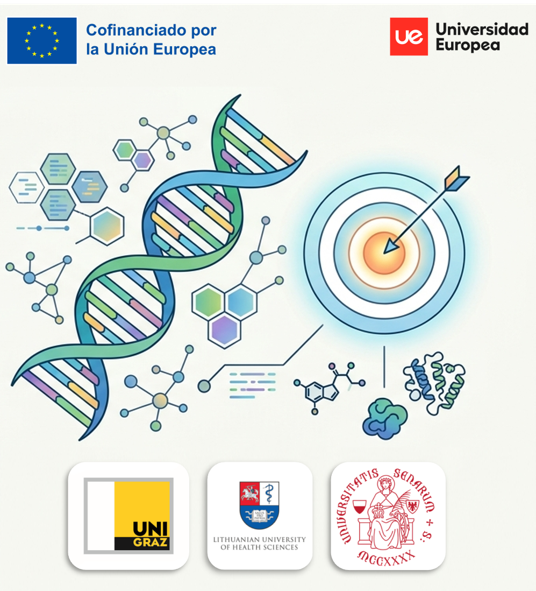
</p>

# INSTALATION

In [ ]:
#@markdown 🐍 This snippet prepares our environment so we can use Conda—a powerful package and environment management system—inside Google Colab.

#@markdown <center> <b> Wait for the process to finish before continue bitte, prašau, per favore!!! </b></center>
#@markdown <center>It will restart the kernel (session), don't worry. </center>
!pip install -q condacolab
import condacolab
condacolab.install()


In [ ]:
#@markdown 🧬🔶 Now that our environment has Conda support ready, we are going to <b> install AmberTools</b> —a popular collection of programs used for biomolecular simulation, analysis, and modeling— using Mamba.

#@markdown <center><b>This software enables the structural analysis of molecular dynamics simulations.</b></center>

!mamba install conda-forge::ambertools==26.0

In [ ]:
#@markdown ⚡🌡️ Now that our environment has Conda support ready, we are going to download and <b>install MMISMSA</b> —a specialized tool designed for binding free energy calculations— directly into our system.
#@markdown <center><b>This software enables the energetic analysis of molecular dynamics simulations.</b></center>

%%bash

# Step 1: Download MMISMSA software archive from Google Drive
gdown --id 1ZAmTxqPzTgZh-NHEnXaUybbKGHtT8u-8
tar -jxvf /content/MMISMSA.tar.bz2

# Step 2: Grant execution permissions to the binary file
chmod +x /content/MMISMSA/MMISMSA

# Step 3: Create a system-wide shortcut (symbolic link) in $PATH
ln -sf /content/MMISMSA/MMISMSA /usr/local/bin/MMISMSA

In [ ]:
#@markdown 📥📦🧬 Now that our software tools are installed, we are going to download the simulation dataset —including <b>topology</b> files (`.prmtop`), <b>initial coordinates</b> (`.crd`) and <b>trajectory</b> files (`.nc`)— required for our analysis.

#@markdown <center><b>This dataset provides the atomic coordinate and topology data necessary to run our structural and energetic calculations. </b>📊</center>

%%bash

gdown --id 1bCZHuBTN4aeuSxp62VgTHPA5jP6zBdWu
unzip -o MD.zip

# Functions

In [ ]:
#@markdown ⚙️ Now that our software and datasets are ready, we are going to define the core <b>custom functions</b> needed throughout this notebook.

#@markdown <center>This step sets up automated helper scripts <u>to streamline our structural and energetic analysis workflow.</u></center> 🛠️📊

import os
import sys
import subprocess
from pathlib import Path
import logging

logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s [%(levelname)s] %(message)s',
    handlers=[
        logging.StreamHandler(sys.stdout),
        logging.FileHandler("analisis_md.log", mode="a", encoding="utf-8")
    ]
)

# Configuración específica de átomos y residuos según cada ligando
LIGAND_CONFIG = {
    'C5E': {
        'hbond_acc': '@O',
        'hbond_don': '@N1',
        'cation_pi_atom': '@N1',
        'aromatic_res': ':359',
        'vector_mask': ':359@CG,CD1,NE1,CE2,CZ2,CH2,CZ3,CE3,CD2 :1042@N1'
    },
    'XRS': {
        'hbond_acc': '@O14,N13',
        'hbond_don': '@N11',
        'cation_pi_atom': '@N11',
        'aromatic_res': ':359',
        'vector_mask': ':359@CG,CD1,NE1,CE2,CZ2,CH2,CZ3,CE3,CD2 :1042@N11'
    },
    'QMR': {
        'hbond_acc': '@N10,N13',
        'hbond_don': '@N02',
        'cation_pi_atom': '@N02',
        'aromatic_res': ':359',
        'vector_mask': ':359@CG,CD1,NE1,CE2,CZ2,CH2,CZ3,CE3,CD2 :1042@N02'
    },
    'NCT': {
        'hbond_acc': '@N1',
        'hbond_don': '@N2',
        'cation_pi_atom': '@N2',
        'aromatic_res': ':359',
        'vector_mask': ':359@CG,CD1,NE1,CE2,CZ2,CH2,CZ3,CE3,CD2 :1042@N2'
    },
    'L0B': {
        'hbond_acc': '@O1,O2',
        'hbond_don': '@N1,O2',
        'cation_pi_atom': '@N1',
        'aromatic_res': ':359',
        'vector_mask': ':359@CG,CD1,NE1,CE2,CZ2,CH2,CZ3,CE3,CD2 :1042@N1'
    },
    'CCE': {
        'hbond_acc': '@O4,O7',
        'hbond_don': '@N6',
        'cation_pi_atom': '@N1',
        'aromatic_res': ':776',
        'vector_mask': ':1042@N1 :776@CG,CD1,NE1,CE2,CZ2,CH2,CZ3,CE3,CD2'
    }
}

SYSTEMS = ['XRS', 'QMR', 'NCT', 'L0B', 'CCE', 'C5E']

def get_ligand_masks(ligand: str):
    """Returns the atom masks and residue settings for a given ligand."""
    default_config = {
        'hbond_acc': '@O',
        'hbond_don': '@N1',
        'cation_pi_atom': '@N1',
        'aromatic_res': ':359',
        'vector_mask': ':359@CG,CD1,NE1,CE2,CZ2,CH2,CZ3,CE3,CD2 :1042@N1'
    }
    return LIGAND_CONFIG.get(ligand, default_config)

def get_input_dir(base_dir: Path, nAChR: str) -> Path:
    """Resolve relative directory inside MD/ (e.g., 6CNK-XRS or XRS)."""
    indir = base_dir / nAChR
    if not indir.exists():
        ligand_only = nAChR.split('-')[-1]
        if (base_dir / ligand_only).exists():
            indir = base_dir / ligand_only
    return indir

def check_input_files(ligand: str) -> bool:
    """Verify that all required input files exist using relative paths."""
    nAChR = f'6CNK-{ligand}'
    base_dir = Path.cwd()  # Assumes execution inside /content/MD
    indir = get_input_dir(base_dir, nAChR)

    missing_files = []

    top_file = indir / f"{nAChR}.top"
    crd_file = indir / f"{nAChR}.crd"

    if not top_file.exists():
        missing_files.append(str(top_file.relative_to(base_dir)))
    if not crd_file.exists():
        missing_files.append(str(crd_file.relative_to(base_dir)))

    for i in range(1, 11):
        nc_file = indir / f"{nAChR}.md{i}.cooled.nc"
        if not nc_file.exists():
            missing_files.append(str(nc_file.relative_to(base_dir)))

    if missing_files:
        logging.error(f"❌ [{nAChR}] MISSING FILES IN DIRECTORY '{indir.relative_to(base_dir)}':")
        for file in missing_files:
            logging.error(f"    - Not found: {file}")
        return False

    logging.info(f"VERIFICATION SUCCESSFUL: Files present for {nAChR}.")
    return True

def run_command(cmd, input_text=None, cwd=None):
    return subprocess.run(cmd, input=input_text, text=True, cwd=cwd, check=True)

def process_cation_pi(source_path: Path, destination_path: Path):
    frames = 0
    stacked = 0
    pairs = []

    if not source_path.exists():
        raise FileNotFoundError(f"Raw file not found: {source_path}")

    with source_path.open(encoding='utf-8') as data:
        for line_number, line in enumerate(data, start=1):
            columns = line.split()
            if not columns or columns[0].startswith('#'):
                continue
            if len(columns) != 3:
                raise ValueError(
                    f'{source_path}:{line_number}: expected frame, distance, angle; got {line.strip()!r}'
                )
            frame, distance, angle = columns
            dis = float(distance)
            ang = float(angle)
            frames += 1
            if 0 <= ang <= 45 and dis <= 5:
                stacked += 1
                pairs.append((dis, ang))

    if frames == 0:
        raise ValueError(f'No trajectory frames found in {source_path}')

    with destination_path.open('w', encoding='utf-8') as output:
        for dis, ang in pairs:
            print(dis, ang, file=output)
        print('Total frames:', frames, file=output)
        print('Total stacked frames:', stacked, file=output)
        print('Total stacked %:', stacked * 100 / frames, file=output)

    logging.info(f"  └─ Cation-pi interactions saved to {destination_path.name} ({stacked}/{frames} frames)")

def run_structural_analysis(ligand: str):
    nAChR = f'6CNK-{ligand}'
    base_dir = Path.cwd()  # Assumes execution inside /content/MD
    workdir1 = base_dir / f'cpptraj.{nAChR}'
    indir_path = get_input_dir(base_dir, nAChR)

    # Relative path pointing up one directory from cpptraj.6CNK-*/
    relative_indir = Path("..") / indir_path.relative_to(base_dir) / nAChR
    indir_str = str(relative_indir)

    cfg = get_ligand_masks(ligand)
    res = cfg['aromatic_res']

    workdir1.mkdir(parents=True, exist_ok=True)
    os.chdir(workdir1)

    try:
        logging.info(f"🔬 [STRUCTURAL] Initiating CPPTRAJ for: {nAChR}")

        cation_raw = Path('cation-pi-raw.dat')
        if cation_raw.exists():
            cation_raw.unlink()

        cpptraj_input = f"""trajin {indir_str}.md1.cooled.nc
trajin {indir_str}.md2.cooled.nc
trajin {indir_str}.md3.cooled.nc
trajin {indir_str}.md4.cooled.nc
trajin {indir_str}.md5.cooled.nc
trajin {indir_str}.md6.cooled.nc
trajin {indir_str}.md7.cooled.nc
trajin {indir_str}.md8.cooled.nc
trajin {indir_str}.md9.cooled.nc
trajin {indir_str}.md10.cooled.nc
autoimage
reference {indir_str}.crd [ini]
rms ref [ini] :1-1041@CA :1-1041@CA

# (1) RMSD analysis
rmsd first :1-1041@CA out {nAChR}.rmsd.dat
rmsd first :1042 out {ligand}.rmsd.dat

# (2) RMSF whole protein
rms ref [ini] :1-1041@CA :1-1041@CA
atomicfluct out {nAChR}_atomic-fluctuations.dat :1-1041@CA byres

# (3) H-bond tracking
hbond donormask :1-1041 acceptormask :{ligand}{cfg['hbond_acc']} out {nAChR}_nHBacc.dat avgout {nAChR}_avgHBacc.dat
hbond donormask :{ligand}{cfg['hbond_don']} acceptormask :1-1041@O,OD1,OD2,OE1,OE2,OG,OG1,OH,NE2,ND1 out {nAChR}_nHBdon.dat avgout {nAChR}_avgHBdon.dat

# (4) Cation-pi tracking
distance DISTANCE {res}@CG,CD1,NE1,CE2,CZ2,CH2,CZ3,CE3,CD2 :1042{cfg['cation_pi_atom']}
vector W{res.strip(':')} corrplane {res}@CG,CD1,NE1,CE2,CZ2,CH2,CZ3,CE3,CD2
vector W{res.strip(':')}-{ligand} mask {cfg['vector_mask']}
vectormath name ANGLE vec1 W{res.strip(':')} vec2 W{res.strip(':')}-{ligand} dotangle
run
writedata cation-pi-raw.dat DISTANCE ANGLE
quit
"""
        run_command(['cpptraj', '-p', f'{indir_str}.top'], input_text=cpptraj_input)
        process_cation_pi(Path('cation-pi-raw.dat'), Path('cation-pi.dat'))
        logging.info(f"  └─ ✅ Structural analysis completed successfully for {nAChR}")

    finally:
        os.chdir(base_dir)

logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s [%(levelname)s] %(message)s',
    handlers=[
        logging.StreamHandler(sys.stdout),
        logging.FileHandler("analisis_md.log", mode="a", encoding="utf-8")
    ]
)

SYSTEMS = ['XRS', 'QMR', 'NCT', 'L0B', 'CCE', 'C5E']

def get_input_dir(base_dir: Path, nAChR: str) -> Path:
    """Resolve relative directory inside MD/ (e.g., 6CNK-XRS or XRS)."""
    indir = base_dir / nAChR
    if not indir.exists():
        ligand_only = nAChR.split('-')[-1]
        if (base_dir / ligand_only).exists():
            indir = base_dir / ligand_only
    return indir

def check_input_files(ligand: str) -> bool:
    """Verify that all required input files exist using relative paths."""
    nAChR = f'6CNK-{ligand}'
    base_dir = Path.cwd()  # Assumes execution inside /content/MD
    indir = get_input_dir(base_dir, nAChR)

    missing_files = []

    top_file = indir / f"{nAChR}.top"
    crd_file = indir / f"{nAChR}.crd"

    if not top_file.exists():
        missing_files.append(str(top_file.relative_to(base_dir)))
    if not crd_file.exists():
        missing_files.append(str(crd_file.relative_to(base_dir)))

    for i in range(1, 11):
        nc_file = indir / f"{nAChR}.md{i}.cooled.nc"
        if not nc_file.exists():
            missing_files.append(str(nc_file.relative_to(base_dir)))

    if missing_files:
        logging.error(f"❌ [{nAChR}] MISSING FILES IN DIRECTORY '{indir.relative_to(base_dir)}':")
        for file in missing_files:
            logging.error(f"    - Not found: {file}")
        return False

    logging.info(f"VERIFICATION SUCCESSFUL: Files present for {nAChR}.")
    return True

def run_command(cmd, input_text=None, cwd=None):
    return subprocess.run(cmd, input=input_text, text=True, cwd=cwd, check=True)

def run_energetic_analysis(ligand: str):
    nAChR = f'6CNK-{ligand}'
    base_dir = Path.cwd()  # Assumes execution inside /content/MD
    workdir2 = base_dir / f'mmismsa.{nAChR}'
    indir_path = get_input_dir(base_dir, nAChR)

    # Relative path pointing up one directory from mmismsa.6CNK-*/
    relative_indir = Path("..") / indir_path.relative_to(base_dir) / nAChR
    indir_str = str(relative_indir)

    workdir2.mkdir(parents=True, exist_ok=True)
    os.chdir(workdir2)

    try:
        logging.info(f"⚡ [ENERGY] Generating desolvated trajectory for: {nAChR}")

        cpptraj_input = f"""trajin {indir_str}.md1.cooled.nc
trajin {indir_str}.md2.cooled.nc
trajin {indir_str}.md3.cooled.nc
trajin {indir_str}.md4.cooled.nc
trajin {indir_str}.md5.cooled.nc
trajin {indir_str}.md6.cooled.nc
trajin {indir_str}.md7.cooled.nc
trajin {indir_str}.md8.cooled.nc
trajin {indir_str}.md9.cooled.nc
trajin {indir_str}.md10.cooled.nc
autoimage
reference {indir_str}.crd [ini]
rms ref [ini] :1-1041@CA :1-1041@CA
strip :Na+|:Cl-|:WAT outprefix mmismsa
trajout {nAChR}.md1-10.trj mdcrd
go
quit
"""
        run_command(['cpptraj', '-p', f'{indir_str}.top'], input_text=cpptraj_input)

        logging.info(f"⚡ [ENERGY] Running MM-ISMSA for: {nAChR}")
        mmismsa_cmd = [
            'MMISMSA',
            '--topology', f'mmismsa.{nAChR}.top',
            '--mdcrd', f'{nAChR}.md1-10.trj',
            '--mask', '1042',
            '--output', f'mmismsa.{ligand}'
        ]
        run_command(mmismsa_cmd)
        logging.info(f"  └─ ✅ Energy analysis completed successfully for {nAChR}")

    finally:
        os.chdir(base_dir)

# Structural analysis

In [ ]:
#@title Run structural analysis
failed_structural = []

print("==================================================")
logging.info("INITIATING STRUCTURAL ANALYSIS FOR ALL SYSTEMS")
print("==================================================")

%cd MD/

for ligand in SYSTEMS:
    system_id = f"6CNK-{ligand}"

    # 1. Comprobar que existen todos los archivos antes de intentar ejecutar nada
    if not check_input_files(ligand):
        failed_structural.append((system_id, "Incomplete input files"))
        continue

    # 2. Intentar ejecutar el análisis estructural
    try:
        run_structural_analysis(ligand)
    except Exception as e:
        logging.error(f"❌ Structural analysis failed on {system_id}. Error details: {e}")
        failed_structural.append((system_id, f"Runtime error: {type(e).__name__}"))

# Resumen de resultados al finalizar el bucle
print("\n" + "="*50)
if not failed_structural:
    logging.info("🎉 Structural analysis COMPLETED WITHOUT ERRORS for all systems!")
else:
    logging.warning("⚠️ SUMMARY OF SYSTEMS THAT FAILED STRUCTURAL ANALYSIS:")
    for sys_id, reason in failed_structural:
        print(f"   ❌ System: {sys_id} -> Failure reason: {reason}")
print("="*50)

%cd ..

# Root-Mean-Square Deviation (RMSD)

## 1. What is RMSD?

**Root-Mean-Square Deviation (RMSD)** is the standard numerical metric used in structural biology and computational chemistry to quantify the structural similarity between two superimposed protein conformations. It measures the average spatial distance between corresponding atoms of two aligned structures, usually expressed in Ångströms ($\mathring{\text{A}}$, where $1\,\mathring{\text{A}} = 10^{-10}\,\text{m}$). Lower values indicate higher structural similarity, where an RMSD of $0\,\mathring{\text{A}}$ means the two structures are identical.

---

## 2. The Mathematical Formula

The mathematical equation for calculating the RMSD between two structures with $N$ equivalent atoms is:

$$\text{RMSD} = \sqrt{\frac{1}{N} \sum_{i=1}^{N} d_i^2} = \sqrt{\frac{1}{N} \sum_{i=1}^{N} \left\| \mathbf{r}_i^{(A)} - \mathbf{r}_i^{(B)} \right\|^2}$$

### Parameters:
* **$N$**: Total number of paired atoms being evaluated.
* **$\mathbf{r}_i^{(A)}$** and **$\mathbf{r}_i^{(B)}$**: The 3D Cartesian coordinate vectors $(x, y, z)$ of atom $i$ in Structure A and Structure B, respectively.
* **$d_i$**: The Euclidean distance between corresponding atom pairs after optimal 3D superposition (rigid-body transformation to minimize global distance).

---

## 3. Why Calculate RMSD Using Only $C_\alpha$ Atoms?

While RMSD can technically be calculated across **all heavy atoms** (all non-hydrogen atoms) or **all backbone atoms** ($\text{N, C}_\alpha, \text{C, O}$), calculating RMSD restricted strictly to **$\text{C}_\alpha$ (Alpha-Carbon)** atoms is standard practice for several reasons:

1. **Focus on Global Fold over Local Noise:**
   Side chains on the surface of proteins are highly flexible and fluctuate frequently due to thermal motion and solvent interaction. Including side-chain atoms introduces significant local noise, masking whether the overall tertiary fold of the protein is conserved.

2. **Computational Efficiency:**
   Restricting the calculation to one $\text{C}_\alpha$ atom per amino acid residue reduces the dataset size by approximately 70–80% compared to all heavy atoms. This dramatically speeds up structural alignments and trajectory processing during molecular dynamics (MD) simulations.

3. **Robustness Against Sequence Variation:**
   When comparing homologous proteins (proteins with similar structures but different amino acid sequences), side-chain atoms vary or mismatch. Using the $\text{C}_\alpha$ backbone trace allows direct structural comparison regardless of sequence identity.

4. **1-to-1 Mapping per Residue:**
   Every amino acid has exactly one $\text{C}_\alpha$ atom serving as the structural anchor of the residue backbone. This provides an unambiguous one-to-one mapping across aligned residue sequences.

---

## 4. Why Calculate RMSD for Ligands Differently than Proteins?

1. **No Uniform Backbone Anchor:** Unlike proteins (which have a continuous $C_\alpha$ backbone), ligands vary wildly in size, shape, functional groups, and atom counts.
2. **Conformational Flexibility:** Small molecules possess rotatable bonds that significantly alter 3D shape without changing the protein structural fold.
3. **Binding Pocket Context:** A ligand's position relative to active site residues (hydrogen bonds, $\pi$-stacking) matters more than its isolated 3D shape.

In [ ]:
#@title Calculation of the receptor RMSD


import os
import glob
import json
from IPython.display import HTML, display

# ==============================================================================
# CONFIGURATION: DIRECTORIES & FILE PATHS
# Edit or add system file patterns, names, and plot colors here.
# ==============================================================================
SYSTEMS_CONFIG = {
    'C5E': {
        'file_pattern': 'MD/cpptraj.6CNK-C5E/6CNK-C5E.rmsd.dat',
        'exact_fallback': 'MD/cpptraj.6CNK-C5E/6CNK-C5E.rmsd.dat',
        'name': '6CNK-C5E',
        'color': '#2563eb'
    },
    'XRS': {
        'file_pattern': 'MD/cpptraj.6CNK-XRS/6CNK-XRS.rmsd.dat',
        'exact_fallback': 'MD/cpptraj.6CNK-XRS/6CNK-XRS.rmsd.dat',
        'name': '6CNK-XRS',
        'color': '#dc2626'
    },
    'QMR': {
        'file_pattern': 'MD/cpptraj.6CNK-QMR/6CNK-QMR.rmsd.dat',
        'exact_fallback': 'MD/cpptraj.6CNK-QMR/6CNK-QMR.rmsd.dat',
        'name': '6CNK-QMR',
        'color': '#059669'
    },
    'NCT': {
        'file_pattern': 'MD/cpptraj.6CNK-NCT/6CNK-NCT.rmsd.dat',
        'exact_fallback': 'MD/cpptraj.6CNK-NCT/6CNK-NCT.rmsd.dat',
        'name': '6CNK-NCT',
        'color': '#d97706'
    },
    'L0B': {
        'file_pattern': 'MD/cpptraj.6CNK-L0B/6CNK-L0B.rmsd.dat',
        'exact_fallback': 'MD/cpptraj.6CNK-L0B/6CNK-L0B.rmsd.dat',
        'name': '6CNK-L0B',
        'color': '#7c3aed'
    },
    'CCE': {
        'file_pattern': 'MD/cpptraj.6CNK-CCE/6CNK-CCE.rmsd.dat',
        'exact_fallback': 'MD/cpptraj.6CNK-CCE/6CNK-CCE.rmsd.dat',
        'name': '6CNK-CCE',
        'color': '#0891b2'
    },
}
# ==============================================================================


def read_cpptraj_rmsd(filepath):
    """Parse cpptraj .rmsd.dat files into a list of floats, skipping headers."""
    rmsd_vals = []
    if not os.path.exists(filepath):
        return None
    with open(filepath, 'r') as f:
        for line in f:
            line = line.strip()
            if line.startswith('#') or line.startswith('@') or not line:
                continue
            parts = line.split()
            if len(parts) >= 2:
                try:
                    val = float(parts[1])
                    rmsd_vals.append(val)
                except ValueError:
                    continue
    return rmsd_vals


# Load system trajectories
systems_data = {}

for sys_key, info in SYSTEMS_CONFIG.items():
    matching_files = glob.glob(info['file_pattern'])
    rmsd_data = None

    if matching_files:
        rmsd_data = read_cpptraj_rmsd(matching_files[0])
    elif os.path.exists(info['exact_fallback']):
        rmsd_data = read_cpptraj_rmsd(info['exact_fallback'])

    if rmsd_data is not None and len(rmsd_data) > 0:
        systems_data[sys_key] = {
            'name': info['name'],
            'color': info['color'],
            'visible': True,
            'rmsd': rmsd_data,
            'isUser': (sys_key == 'C5E')
        }
        print(f"✓ Loaded {info['name']} ({len(rmsd_data)} frames)")
    else:
        print(f"⚠ File not found for {sys_key} ({info['exact_fallback']}). Skipping.")

json_systems = json.dumps(systems_data)

html_code = f"""
<!DOCTYPE html>
<html lang="en" class="h-full">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>MD RMSD Trajectory Studio</title>
    <script src="https://cdn.tailwindcss.com"></script>
    <script src="https://cdn.plot.ly/plotly-2.27.0.min.js"></script>
    <link rel="stylesheet" href="https://cdnjs.cloudflare.com/ajax/libs/font-awesome/6.4.0/css/all.min.css">
    <link href="https://fonts.googleapis.com/css2?family=Inter:wght@300;400;500;600;700&display=swap" rel="stylesheet">
    <style>
        body {{ font-family: 'Inter', sans-serif; }}
        .glass-panel {{
            background: rgba(255, 255, 255, 0.9);
            backdrop-filter: blur(12px);
            border: 1px solid rgba(229, 231, 235, 0.8);
        }}
        .dark .glass-panel {{
            background: rgba(17, 24, 39, 0.9);
            backdrop-filter: blur(12px);
            border: 1px solid rgba(55, 65, 81, 0.5);
        }}
        .custom-scrollbar::-webkit-scrollbar {{ width: 6px; height: 6px; }}
        .custom-scrollbar::-webkit-scrollbar-track {{ background: transparent; }}
        .custom-scrollbar::-webkit-scrollbar-thumb {{ background: #cbd5e1; border-radius: 9999px; }}
        .dark .custom-scrollbar::-webkit-scrollbar-thumb {{ background: #475569; }}
    </style>
</head>
<body class="bg-slate-50 dark:bg-slate-950 text-slate-800 dark:text-slate-100 p-2 sm:p-4 custom-scrollbar">

    <!-- Header -->
    <header class="glass-panel rounded-2xl p-4 mb-4 flex flex-wrap items-center justify-between gap-3">
        <div class="flex items-center space-x-3">
            <div class="bg-gradient-to-tr from-blue-600 to-indigo-600 p-2.5 rounded-xl text-white shadow-md">
                <i class="fa-solid fa-chart-line text-lg"></i>
            </div>
            <div>
                <h1 class="font-bold text-lg leading-tight text-slate-900 dark:text-white">MD RMSD Trajectory Studio</h1>
                <p class="text-xs text-slate-500 dark:text-slate-400">Interactive Comparative Analysis for Molecular Dynamics</p>
            </div>
        </div>
        <div class="flex items-center space-x-2">
            <button onclick="toggleDarkMode()" class="p-2 rounded-lg text-slate-500 dark:text-slate-400 hover:bg-slate-100 dark:hover:bg-slate-800 transition" title="Toggle theme">
                <i class="fa-solid fa-moon text-lg dark:hidden"></i>
                <i class="fa-solid fa-sun text-lg hidden dark:block text-amber-400"></i>
            </button>
        </div>
    </header>

    <!-- Controls -->
    <div class="grid grid-cols-1 md:grid-cols-12 gap-4 mb-4">
        <div class="md:col-span-5 glass-panel rounded-2xl p-4 flex flex-col justify-between">
            <div class="flex justify-between items-center mb-2">
                <label class="text-xs font-semibold uppercase tracking-wider text-slate-500 dark:text-slate-400 flex items-center gap-1.5">
                    <i class="fa-regular fa-clock text-blue-500"></i> Simulation Parameters
                </label>
                <span class="text-xs bg-blue-100 dark:bg-blue-900/40 text-blue-700 dark:text-blue-300 px-2 py-0.5 rounded-full font-mono" id="timePerFrameBadge">0.200 ns/frame</span>
            </div>
            <div class="grid grid-cols-2 gap-3">
                <div>
                    <label class="block text-xs text-slate-500 dark:text-slate-400 mb-1">Total Time (ns)</label>
                    <input type="number" id="totalTimeNsInput" value="50" min="1" step="5" class="w-full bg-slate-100 dark:bg-slate-800 border border-slate-300 dark:border-slate-700 rounded-lg px-3 py-1.5 text-sm font-medium focus:outline-none focus:ring-2 focus:ring-blue-500" onchange="updateTimeScaling()">
                </div>
                <div>
                    <label class="block text-xs text-slate-500 dark:text-slate-400 mb-1">X-Axis Unit</label>
                    <select id="xAxisUnitSelect" class="w-full bg-slate-100 dark:bg-slate-800 border border-slate-300 dark:border-slate-700 rounded-lg px-3 py-1.5 text-sm font-medium focus:outline-none focus:ring-2 focus:ring-blue-500" onchange="renderPlot()">
                        <option value="time">Time (ns)</option>
                        <option value="frame">Frame (#)</option>
                    </select>
                </div>
            </div>
        </div>

        <div class="md:col-span-7 glass-panel rounded-2xl p-4 flex flex-col justify-between">
            <div class="flex justify-between items-center mb-2">
                <span class="text-xs font-semibold uppercase tracking-wider text-slate-500 dark:text-slate-400 flex items-center gap-1.5">
                    <i class="fa-solid fa-filter text-indigo-500"></i> Quick Selection Filters
                </span>
                <span class="text-xs text-slate-500" id="activeCountBadge">0 active systems</span>
            </div>
            <div class="flex flex-wrap gap-2">
                <button onclick="selectAllSystems(true)" class="px-3 py-1.5 text-xs font-medium bg-slate-200 dark:bg-slate-800 hover:bg-slate-300 dark:hover:bg-slate-700 rounded-lg transition">
                    <i class="fa-solid fa-check-double mr-1 text-slate-500"></i> Select All
                </button>
                <button onclick="selectAllSystems(false)" class="px-3 py-1.5 text-xs font-medium bg-slate-200 dark:bg-slate-800 hover:bg-slate-300 dark:hover:bg-slate-700 rounded-lg transition">
                    <i class="fa-solid fa-square-xmark mr-1 text-slate-500"></i> Deselect All
                </button>
                <button onclick="selectOnlyReference()" class="px-3 py-1.5 text-xs font-medium bg-indigo-100 dark:bg-indigo-950/60 text-indigo-700 dark:text-indigo-300 border border-indigo-200 dark:border-indigo-800/50 hover:bg-indigo-200 rounded-lg transition">
                    <i class="fa-solid fa-star mr-1"></i> Reference Only (C5E)
                </button>
            </div>
        </div>
    </div>

    <!-- Main Grid -->
    <div class="grid grid-cols-1 lg:grid-cols-4 gap-6 mb-4">
        <div class="lg:col-span-1 glass-panel rounded-2xl p-4 flex flex-col">
            <h2 class="text-sm font-bold tracking-tight text-slate-900 dark:text-white mb-3 flex items-center justify-between">
                <span>Loaded Systems</span>
                <span class="text-xs font-normal text-slate-400">Show/Hide</span>
            </h2>
            <div id="systemsCheckboxesList" class="flex flex-col gap-2.5 overflow-y-auto max-h-[450px] pr-1 custom-scrollbar"></div>
        </div>

        <div class="lg:col-span-3 glass-panel rounded-2xl p-4 flex flex-col justify-between min-h-[460px]">
            <div id="plotlyDiv" class="w-full h-[450px]"></div>
        </div>
    </div>

    <!-- Statistics Summary Table -->
    <div class="glass-panel rounded-2xl p-5">
        <h3 class="font-bold text-slate-900 dark:text-white text-base mb-3 flex items-center gap-2">
            <i class="fa-solid fa-calculator text-emerald-500"></i> Structural RMSD Statistics
        </h3>
        <div class="overflow-x-auto custom-scrollbar">
            <table class="w-full text-left border-collapse text-sm">
                <thead>
                    <tr class="border-b border-slate-200 dark:border-slate-800 text-xs font-semibold uppercase tracking-wider text-slate-500 dark:text-slate-400 bg-slate-100/50 dark:bg-slate-800/40">
                        <th class="py-3 px-4 rounded-l-lg">System / Ligand</th>
                        <th class="py-3 px-4">Mean RMSD (Å)</th>
                        <th class="py-3 px-4">Std Dev (SD)</th>
                        <th class="py-3 px-4">Min (Å)</th>
                        <th class="py-3 px-4">Max (Å)</th>
                        <th class="py-3 px-4 rounded-r-lg">Equilibrium Status</th>
                    </tr>
                </thead>
                <tbody id="statsTableBody" class="divide-y divide-slate-200/60 dark:divide-slate-800/60 font-mono text-xs sm:text-sm"></tbody>
            </table>
        </div>
    </div>

    <script>
        let systemsData = {json_systems};

        window.addEventListener('DOMContentLoaded', () => {{
            renderCheckboxList();
            updateTimeScaling();
            renderPlot();
        }});

        function toggleDarkMode() {{
            document.documentElement.classList.toggle('dark');
            renderPlot();
        }}

        function updateTimeScaling() {{
            const totalNs = parseFloat(document.getElementById('totalTimeNsInput').value) || 50;
            const maxFrames = Math.max(...Object.values(systemsData).map(s => s.rmsd.length), 1);
            const nsPerFrame = totalNs / maxFrames;
            document.getElementById('timePerFrameBadge').innerText = `${{nsPerFrame.toFixed(3)}} ns/frame`;
            renderPlot();
        }}

        function renderCheckboxList() {{
            const container = document.getElementById('systemsCheckboxesList');
            container.innerHTML = '';
            let activeCount = 0;

            Object.keys(systemsData).forEach(key => {{
                const sys = systemsData[key];
                if (sys.visible) activeCount++;

                const item = document.createElement('label');
                item.className = `flex items-center justify-between p-2.5 rounded-xl border transition cursor-pointer ${{
                    sys.visible ? 'bg-slate-100 dark:bg-slate-800/80 border-slate-300 dark:border-slate-700 shadow-sm' : 'bg-transparent border-slate-200 dark:border-slate-800 opacity-60'
                }}`;
                item.innerHTML = `
                    <div class="flex items-center space-x-2.5">
                        <input type="checkbox" ${{sys.visible ? 'checked' : ''}} onchange="toggleSystemVisibility('${{key}}')" class="rounded border-slate-300 text-blue-600 focus:ring-blue-500 h-4 w-4">
                        <span class="w-3 h-3 rounded-full flex-shrink-0" style="background-color: ${{sys.color}}"></span>
                        <span class="text-xs font-semibold text-slate-800 dark:text-slate-200">${{sys.name}}</span>
                    </div>
                    ${{sys.isUser ? '<span class="text-[10px] bg-blue-100 dark:bg-blue-900/50 text-blue-600 dark:text-blue-300 px-1.5 py-0.5 rounded font-medium">Ref</span>' : ''}}
                `;
                container.appendChild(item);
            }});
            document.getElementById('activeCountBadge').innerText = `${{activeCount}} active`;
        }}

        function toggleSystemVisibility(key) {{
            systemsData[key].visible = !systemsData[key].visible;
            renderCheckboxList();
            renderPlot();
        }}

        function selectAllSystems(status) {{
            Object.keys(systemsData).forEach(key => systemsData[key].visible = status);
            renderCheckboxList();
            renderPlot();
        }}

        function selectOnlyReference() {{
            Object.keys(systemsData).forEach(key => systemsData[key].visible = (key === 'C5E'));
            renderCheckboxList();
            renderPlot();
        }}

        function renderPlot() {{
            const isDark = document.documentElement.classList.contains('dark');
            const totalNs = parseFloat(document.getElementById('totalTimeNsInput').value) || 50;
            const xAxisUnit = document.getElementById('xAxisUnitSelect').value;

            const traces = [];
            const stats = [];

            Object.keys(systemsData).forEach(key => {{
                const sys = systemsData[key];
                if (!sys.visible) return;

                const numFrames = sys.rmsd.length;
                const nsPerFrame = totalNs / numFrames;

                const xValues = sys.rmsd.map((_, i) => xAxisUnit === 'time' ? (i + 1) * nsPerFrame : (i + 1));
                const customData = sys.rmsd.map((_, i) => xAxisUnit === 'time' ? (i + 1) : (i + 1) * nsPerFrame);

                traces.push({{
                    x: xValues,
                    y: sys.rmsd,
                    customdata: customData,
                    mode: 'lines',
                    name: sys.name,
                    line: {{ color: sys.color, width: 2 }},
                    hovertemplate: xAxisUnit === 'time'
                        ? `<b>${{sys.name}}</b><br>Time: %{{x:.2f}} ns<br>Frame: %{{customdata}}<br>RMSD: %{{y:.4f}} Å<extra></extra>`
                        : `<b>${{sys.name}}</b><br>Frame: %{{x}}<br>Time: %{{customdata:.2f}} ns<br>RMSD: %{{y:.4f}} Å<extra></extra>`
                }});

                const mean = sys.rmsd.reduce((a, b) => a + b, 0) / numFrames;
                const min = Math.min(...sys.rmsd);
                const max = Math.max(...sys.rmsd);
                const variance = sys.rmsd.reduce((a, b) => a + Math.pow(b - mean, 2), 0) / numFrames;
                const sd = Math.sqrt(variance);

                stats.push({{
                    name: sys.name,
                    color: sys.color,
                    mean: mean.toFixed(3),
                    sd: sd.toFixed(3),
                    min: min.toFixed(3),
                    max: max.toFixed(3),
                    equilibrium: mean < 2.0 ? 'Stable (< 2 Å)' : 'Fluctuating (> 2 Å)'
                }});
            }});

            const layout = {{
                margin: {{ t: 30, r: 20, l: 60, b: 50 }},
                paper_bgcolor: 'rgba(0,0,0,0)',
                plot_bgcolor: 'rgba(0,0,0,0)',
                font: {{ family: 'Inter, sans-serif', color: isDark ? '#94a3b8' : '#475569' }},
                xaxis: {{
                    title: {{ text: xAxisUnit === 'time' ? 'Simulation Time (ns)' : 'Frame Number (#)', font: {{ size: 13, weight: 600 }} }},
                    gridcolor: isDark ? '#334155' : '#e2e8f0',
                    zerolinecolor: isDark ? '#475569' : '#cbd5e1'
                }},
                yaxis: {{
                    title: {{ text: 'RMSD (Ångströms - Å)', font: {{ size: 13, weight: 600 }} }},
                    gridcolor: isDark ? '#334155' : '#e2e8f0',
                    zerolinecolor: isDark ? '#475569' : '#cbd5e1'
                }},
                legend: {{ orientation: 'h', y: 1.12, x: 0, font: {{ size: 11 }} }},
                hovermode: 'x unified'
            }};

            Plotly.newPlot('plotlyDiv', traces, layout, {{ responsive: true, displayModeBar: true, displaylogo: false }});
            renderStatsTable(stats);
        }}

        function renderStatsTable(stats) {{
            const tbody = document.getElementById('statsTableBody');
            tbody.innerHTML = '';
            stats.forEach(s => {{
                const row = document.createElement('tr');
                row.className = 'hover:bg-slate-100/50 dark:hover:bg-slate-800/50 transition';
                row.innerHTML = `
                    <td class="py-3 px-4 font-semibold flex items-center space-x-2">
                        <span class="w-2.5 h-2.5 rounded-full" style="background-color: ${{s.color}}"></span>
                        <span class="text-slate-900 dark:text-white">${{s.name}}</span>
                    </td>
                    <td class="py-3 px-4 font-bold text-slate-800 dark:text-slate-200">${{s.mean}}</td>
                    <td class="py-3 px-4 text-slate-600 dark:text-slate-400">± ${{s.sd}}</td>
                    <td class="py-3 px-4 text-slate-600 dark:text-slate-400">${{s.min}}</td>
                    <td class="py-3 px-4 text-slate-600 dark:text-slate-400">${{s.max}}</td>
                    <td class="py-3 px-4">
                        <span class="text-xs px-2.5 py-1 rounded-full font-medium ${{
                            s.equilibrium.includes('Stable') ? 'bg-emerald-100 dark:bg-emerald-950/60 text-emerald-700 dark:text-emerald-300' : 'bg-amber-100 dark:bg-amber-950/60 text-amber-700 dark:text-amber-300'
                        }}">${{s.equilibrium}}</span>
                    </td>
                `;
                tbody.appendChild(row);
            }});
        }}
    </script>
</body>
</html>
"""

# Render interactive view within Google Colab
display(HTML(f'''
<iframe srcdoc="{html_code.replace('"', '&quot;')}" width="100%" height="950px" style="border:none;"></iframe>
'''))

In [ ]:
#@title Calculation of the ligand RMSD
import os
import glob
import json
from IPython.display import HTML, display

# ==============================================================================
# CONFIGURATION: DIRECTORIES & FILE PATHS
# Edit or add system file patterns, names, and plot colors here.
# ==============================================================================
SYSTEMS_CONFIG = {
    'C5E': {
        'file_pattern': 'MD/cpptraj.6CNK-C5E/C5E.rmsd.dat',
        'exact_fallback': 'MD/cpptraj.6CNK-C5E/C5E.rmsd.dat',
        'name': 'C5E',
        'color': '#2563eb'
    },
    'XRS': {
        'file_pattern': 'MD/cpptraj.6CNK-XRS/XRS.rmsd.dat',
        'exact_fallback': 'MD/cpptraj.6CNK-XRS/XRS.rmsd.dat',
        'name': 'XRS',
        'color': '#dc2626'
    },
    'QMR': {
        'file_pattern': 'MD/cpptraj.6CNK-QMR/QMR.rmsd.dat',
        'exact_fallback': 'MD/cpptraj.6CNK-QMR/QMR.rmsd.dat',
        'name': 'QMR',
        'color': '#059669'
    },
    'NCT': {
        'file_pattern': 'MD/cpptraj.6CNK-NCT/NCT.rmsd.dat',
        'exact_fallback': 'MD/cpptraj.6CNK-NCT/NCT.rmsd.dat',
        'name': 'NCT',
        'color': '#d97706'
    },
    'L0B': {
        'file_pattern': 'MD/cpptraj.6CNK-L0B/L0B.rmsd.dat',
        'exact_fallback': 'MD/cpptraj.6CNK-L0B/L0B.rmsd.dat',
        'name': 'L0B',
        'color': '#7c3aed'
    },
    'CCE': {
        'file_pattern': 'MD/cpptraj.6CNK-CCE/CCE.rmsd.dat',
        'exact_fallback': 'MD/cpptraj.6CNK-CCE/CCE.rmsd.dat',
        'name': 'CCE',
        'color': '#0891b2'
    },
}
# ==============================================================================


def read_cpptraj_rmsd(filepath):
    """Parse cpptraj .rmsd.dat files into a list of floats, skipping headers."""
    rmsd_vals = []
    if not os.path.exists(filepath):
        return None
    with open(filepath, 'r') as f:
        for line in f:
            line = line.strip()
            if line.startswith('#') or line.startswith('@') or not line:
                continue
            parts = line.split()
            if len(parts) >= 2:
                try:
                    val = float(parts[1])
                    rmsd_vals.append(val)
                except ValueError:
                    continue
    return rmsd_vals


# Load system trajectories
systems_data = {}

for sys_key, info in SYSTEMS_CONFIG.items():
    matching_files = glob.glob(info['file_pattern'])
    rmsd_data = None

    if matching_files:
        rmsd_data = read_cpptraj_rmsd(matching_files[0])
    elif os.path.exists(info['exact_fallback']):
        rmsd_data = read_cpptraj_rmsd(info['exact_fallback'])

    if rmsd_data is not None and len(rmsd_data) > 0:
        systems_data[sys_key] = {
            'name': info['name'],
            'color': info['color'],
            'visible': True,
            'rmsd': rmsd_data,
            'isUser': (sys_key == 'C5E')
        }
        print(f"✓ Loaded {info['name']} ({len(rmsd_data)} frames)")
    else:
        print(f"⚠ File not found for {sys_key} ({info['exact_fallback']}). Skipping.")

json_systems = json.dumps(systems_data)

html_code = f"""
<!DOCTYPE html>
<html lang="en" class="h-full">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>MD RMSD Trajectory Studio</title>
    <script src="https://cdn.tailwindcss.com"></script>
    <script src="https://cdn.plot.ly/plotly-2.27.0.min.js"></script>
    <link rel="stylesheet" href="https://cdnjs.cloudflare.com/ajax/libs/font-awesome/6.4.0/css/all.min.css">
    <link href="https://fonts.googleapis.com/css2?family=Inter:wght@300;400;500;600;700&display=swap" rel="stylesheet">
    <style>
        body {{ font-family: 'Inter', sans-serif; }}
        .glass-panel {{
            background: rgba(255, 255, 255, 0.9);
            backdrop-filter: blur(12px);
            border: 1px solid rgba(229, 231, 235, 0.8);
        }}
        .dark .glass-panel {{
            background: rgba(17, 24, 39, 0.9);
            backdrop-filter: blur(12px);
            border: 1px solid rgba(55, 65, 81, 0.5);
        }}
        .custom-scrollbar::-webkit-scrollbar {{ width: 6px; height: 6px; }}
        .custom-scrollbar::-webkit-scrollbar-track {{ background: transparent; }}
        .custom-scrollbar::-webkit-scrollbar-thumb {{ background: #cbd5e1; border-radius: 9999px; }}
        .dark .custom-scrollbar::-webkit-scrollbar-thumb {{ background: #475569; }}
    </style>
</head>
<body class="bg-slate-50 dark:bg-slate-950 text-slate-800 dark:text-slate-100 p-2 sm:p-4 custom-scrollbar">

    <!-- Header -->
    <header class="glass-panel rounded-2xl p-4 mb-4 flex flex-wrap items-center justify-between gap-3">
        <div class="flex items-center space-x-3">
            <div class="bg-gradient-to-tr from-blue-600 to-indigo-600 p-2.5 rounded-xl text-white shadow-md">
                <i class="fa-solid fa-chart-line text-lg"></i>
            </div>
            <div>
                <h1 class="font-bold text-lg leading-tight text-slate-900 dark:text-white">MD RMSD Trajectory Studio</h1>
                <p class="text-xs text-slate-500 dark:text-slate-400">Interactive Comparative Analysis for Molecular Dynamics</p>
            </div>
        </div>
        <div class="flex items-center space-x-2">
            <button onclick="toggleDarkMode()" class="p-2 rounded-lg text-slate-500 dark:text-slate-400 hover:bg-slate-100 dark:hover:bg-slate-800 transition" title="Toggle theme">
                <i class="fa-solid fa-moon text-lg dark:hidden"></i>
                <i class="fa-solid fa-sun text-lg hidden dark:block text-amber-400"></i>
            </button>
        </div>
    </header>

    <!-- Controls -->
    <div class="grid grid-cols-1 md:grid-cols-12 gap-4 mb-4">
        <div class="md:col-span-5 glass-panel rounded-2xl p-4 flex flex-col justify-between">
            <div class="flex justify-between items-center mb-2">
                <label class="text-xs font-semibold uppercase tracking-wider text-slate-500 dark:text-slate-400 flex items-center gap-1.5">
                    <i class="fa-regular fa-clock text-blue-500"></i> Simulation Parameters
                </label>
                <span class="text-xs bg-blue-100 dark:bg-blue-900/40 text-blue-700 dark:text-blue-300 px-2 py-0.5 rounded-full font-mono" id="timePerFrameBadge">0.200 ns/frame</span>
            </div>
            <div class="grid grid-cols-2 gap-3">
                <div>
                    <label class="block text-xs text-slate-500 dark:text-slate-400 mb-1">Total Time (ns)</label>
                    <input type="number" id="totalTimeNsInput" value="50" min="1" step="5" class="w-full bg-slate-100 dark:bg-slate-800 border border-slate-300 dark:border-slate-700 rounded-lg px-3 py-1.5 text-sm font-medium focus:outline-none focus:ring-2 focus:ring-blue-500" onchange="updateTimeScaling()">
                </div>
                <div>
                    <label class="block text-xs text-slate-500 dark:text-slate-400 mb-1">X-Axis Unit</label>
                    <select id="xAxisUnitSelect" class="w-full bg-slate-100 dark:bg-slate-800 border border-slate-300 dark:border-slate-700 rounded-lg px-3 py-1.5 text-sm font-medium focus:outline-none focus:ring-2 focus:ring-blue-500" onchange="renderPlot()">
                        <option value="time">Time (ns)</option>
                        <option value="frame">Frame (#)</option>
                    </select>
                </div>
            </div>
        </div>

        <div class="md:col-span-7 glass-panel rounded-2xl p-4 flex flex-col justify-between">
            <div class="flex justify-between items-center mb-2">
                <span class="text-xs font-semibold uppercase tracking-wider text-slate-500 dark:text-slate-400 flex items-center gap-1.5">
                    <i class="fa-solid fa-filter text-indigo-500"></i> Quick Selection Filters
                </span>
                <span class="text-xs text-slate-500" id="activeCountBadge">0 active systems</span>
            </div>
            <div class="flex flex-wrap gap-2">
                <button onclick="selectAllSystems(true)" class="px-3 py-1.5 text-xs font-medium bg-slate-200 dark:bg-slate-800 hover:bg-slate-300 dark:hover:bg-slate-700 rounded-lg transition">
                    <i class="fa-solid fa-check-double mr-1 text-slate-500"></i> Select All
                </button>
                <button onclick="selectAllSystems(false)" class="px-3 py-1.5 text-xs font-medium bg-slate-200 dark:bg-slate-800 hover:bg-slate-300 dark:hover:bg-slate-700 rounded-lg transition">
                    <i class="fa-solid fa-square-xmark mr-1 text-slate-500"></i> Deselect All
                </button>
                <button onclick="selectOnlyReference()" class="px-3 py-1.5 text-xs font-medium bg-indigo-100 dark:bg-indigo-950/60 text-indigo-700 dark:text-indigo-300 border border-indigo-200 dark:border-indigo-800/50 hover:bg-indigo-200 rounded-lg transition">
                    <i class="fa-solid fa-star mr-1"></i> Reference Only (C5E)
                </button>
            </div>
        </div>
    </div>

    <!-- Main Grid -->
    <div class="grid grid-cols-1 lg:grid-cols-4 gap-6 mb-4">
        <div class="lg:col-span-1 glass-panel rounded-2xl p-4 flex flex-col">
            <h2 class="text-sm font-bold tracking-tight text-slate-900 dark:text-white mb-3 flex items-center justify-between">
                <span>Loaded Systems</span>
                <span class="text-xs font-normal text-slate-400">Show/Hide</span>
            </h2>
            <div id="systemsCheckboxesList" class="flex flex-col gap-2.5 overflow-y-auto max-h-[450px] pr-1 custom-scrollbar"></div>
        </div>

        <div class="lg:col-span-3 glass-panel rounded-2xl p-4 flex flex-col justify-between min-h-[460px]">
            <div id="plotlyDiv" class="w-full h-[450px]"></div>
        </div>
    </div>

    <!-- Statistics Summary Table -->
    <div class="glass-panel rounded-2xl p-5">
        <h3 class="font-bold text-slate-900 dark:text-white text-base mb-3 flex items-center gap-2">
            <i class="fa-solid fa-calculator text-emerald-500"></i> Structural RMSD Statistics
        </h3>
        <div class="overflow-x-auto custom-scrollbar">
            <table class="w-full text-left border-collapse text-sm">
                <thead>
                    <tr class="border-b border-slate-200 dark:border-slate-800 text-xs font-semibold uppercase tracking-wider text-slate-500 dark:text-slate-400 bg-slate-100/50 dark:bg-slate-800/40">
                        <th class="py-3 px-4 rounded-l-lg">System / Ligand</th>
                        <th class="py-3 px-4">Mean RMSD (Å)</th>
                        <th class="py-3 px-4">Std Dev (SD)</th>
                        <th class="py-3 px-4">Min (Å)</th>
                        <th class="py-3 px-4">Max (Å)</th>
                        <th class="py-3 px-4 rounded-r-lg">Equilibrium Status</th>
                    </tr>
                </thead>
                <tbody id="statsTableBody" class="divide-y divide-slate-200/60 dark:divide-slate-800/60 font-mono text-xs sm:text-sm"></tbody>
            </table>
        </div>
    </div>

    <script>
        let systemsData = {json_systems};

        window.addEventListener('DOMContentLoaded', () => {{
            renderCheckboxList();
            updateTimeScaling();
            renderPlot();
        }});

        function toggleDarkMode() {{
            document.documentElement.classList.toggle('dark');
            renderPlot();
        }}

        function updateTimeScaling() {{
            const totalNs = parseFloat(document.getElementById('totalTimeNsInput').value) || 50;
            const maxFrames = Math.max(...Object.values(systemsData).map(s => s.rmsd.length), 1);
            const nsPerFrame = totalNs / maxFrames;
            document.getElementById('timePerFrameBadge').innerText = `${{nsPerFrame.toFixed(3)}} ns/frame`;
            renderPlot();
        }}

        function renderCheckboxList() {{
            const container = document.getElementById('systemsCheckboxesList');
            container.innerHTML = '';
            let activeCount = 0;

            Object.keys(systemsData).forEach(key => {{
                const sys = systemsData[key];
                if (sys.visible) activeCount++;

                const item = document.createElement('label');
                item.className = `flex items-center justify-between p-2.5 rounded-xl border transition cursor-pointer ${{
                    sys.visible ? 'bg-slate-100 dark:bg-slate-800/80 border-slate-300 dark:border-slate-700 shadow-sm' : 'bg-transparent border-slate-200 dark:border-slate-800 opacity-60'
                }}`;
                item.innerHTML = `
                    <div class="flex items-center space-x-2.5">
                        <input type="checkbox" ${{sys.visible ? 'checked' : ''}} onchange="toggleSystemVisibility('${{key}}')" class="rounded border-slate-300 text-blue-600 focus:ring-blue-500 h-4 w-4">
                        <span class="w-3 h-3 rounded-full flex-shrink-0" style="background-color: ${{sys.color}}"></span>
                        <span class="text-xs font-semibold text-slate-800 dark:text-slate-200">${{sys.name}}</span>
                    </div>
                    ${{sys.isUser ? '<span class="text-[10px] bg-blue-100 dark:bg-blue-900/50 text-blue-600 dark:text-blue-300 px-1.5 py-0.5 rounded font-medium">Ref</span>' : ''}}
                `;
                container.appendChild(item);
            }});
            document.getElementById('activeCountBadge').innerText = `${{activeCount}} active`;
        }}

        function toggleSystemVisibility(key) {{
            systemsData[key].visible = !systemsData[key].visible;
            renderCheckboxList();
            renderPlot();
        }}

        function selectAllSystems(status) {{
            Object.keys(systemsData).forEach(key => systemsData[key].visible = status);
            renderCheckboxList();
            renderPlot();
        }}

        function selectOnlyReference() {{
            Object.keys(systemsData).forEach(key => systemsData[key].visible = (key === 'C5E'));
            renderCheckboxList();
            renderPlot();
        }}

        function renderPlot() {{
            const isDark = document.documentElement.classList.contains('dark');
            const totalNs = parseFloat(document.getElementById('totalTimeNsInput').value) || 50;
            const xAxisUnit = document.getElementById('xAxisUnitSelect').value;

            const traces = [];
            const stats = [];

            Object.keys(systemsData).forEach(key => {{
                const sys = systemsData[key];
                if (!sys.visible) return;

                const numFrames = sys.rmsd.length;
                const nsPerFrame = totalNs / numFrames;

                const xValues = sys.rmsd.map((_, i) => xAxisUnit === 'time' ? (i + 1) * nsPerFrame : (i + 1));
                const customData = sys.rmsd.map((_, i) => xAxisUnit === 'time' ? (i + 1) : (i + 1) * nsPerFrame);

                traces.push({{
                    x: xValues,
                    y: sys.rmsd,
                    customdata: customData,
                    mode: 'lines',
                    name: sys.name,
                    line: {{ color: sys.color, width: 2 }},
                    hovertemplate: xAxisUnit === 'time'
                        ? `<b>${{sys.name}}</b><br>Time: %{{x:.2f}} ns<br>Frame: %{{customdata}}<br>RMSD: %{{y:.4f}} Å<extra></extra>`
                        : `<b>${{sys.name}}</b><br>Frame: %{{x}}<br>Time: %{{customdata:.2f}} ns<br>RMSD: %{{y:.4f}} Å<extra></extra>`
                }});

                const mean = sys.rmsd.reduce((a, b) => a + b, 0) / numFrames;
                const min = Math.min(...sys.rmsd);
                const max = Math.max(...sys.rmsd);
                const variance = sys.rmsd.reduce((a, b) => a + Math.pow(b - mean, 2), 0) / numFrames;
                const sd = Math.sqrt(variance);

                stats.push({{
                    name: sys.name,
                    color: sys.color,
                    mean: mean.toFixed(3),
                    sd: sd.toFixed(3),
                    min: min.toFixed(3),
                    max: max.toFixed(3),
                    equilibrium: mean < 2.0 ? 'Stable (< 2 Å)' : 'Fluctuating (> 2 Å)'
                }});
            }});

            const layout = {{
                margin: {{ t: 30, r: 20, l: 60, b: 50 }},
                paper_bgcolor: 'rgba(0,0,0,0)',
                plot_bgcolor: 'rgba(0,0,0,0)',
                font: {{ family: 'Inter, sans-serif', color: isDark ? '#94a3b8' : '#475569' }},
                xaxis: {{
                    title: {{ text: xAxisUnit === 'time' ? 'Simulation Time (ns)' : 'Frame Number (#)', font: {{ size: 13, weight: 600 }} }},
                    gridcolor: isDark ? '#334155' : '#e2e8f0',
                    zerolinecolor: isDark ? '#475569' : '#cbd5e1'
                }},
                yaxis: {{
                    title: {{ text: 'RMSD (Ångströms - Å)', font: {{ size: 13, weight: 600 }} }},
                    gridcolor: isDark ? '#334155' : '#e2e8f0',
                    zerolinecolor: isDark ? '#475569' : '#cbd5e1'
                }},
                legend: {{ orientation: 'h', y: 1.12, x: 0, font: {{ size: 11 }} }},
                hovermode: 'x unified'
            }};

            Plotly.newPlot('plotlyDiv', traces, layout, {{ responsive: true, displayModeBar: true, displaylogo: false }});
            renderStatsTable(stats);
        }}

        function renderStatsTable(stats) {{
            const tbody = document.getElementById('statsTableBody');
            tbody.innerHTML = '';
            stats.forEach(s => {{
                const row = document.createElement('tr');
                row.className = 'hover:bg-slate-100/50 dark:hover:bg-slate-800/50 transition';
                row.innerHTML = `
                    <td class="py-3 px-4 font-semibold flex items-center space-x-2">
                        <span class="w-2.5 h-2.5 rounded-full" style="background-color: ${{s.color}}"></span>
                        <span class="text-slate-900 dark:text-white">${{s.name}}</span>
                    </td>
                    <td class="py-3 px-4 font-bold text-slate-800 dark:text-slate-200">${{s.mean}}</td>
                    <td class="py-3 px-4 text-slate-600 dark:text-slate-400">± ${{s.sd}}</td>
                    <td class="py-3 px-4 text-slate-600 dark:text-slate-400">${{s.min}}</td>
                    <td class="py-3 px-4 text-slate-600 dark:text-slate-400">${{s.max}}</td>
                    <td class="py-3 px-4">
                        <span class="text-xs px-2.5 py-1 rounded-full font-medium ${{
                            s.equilibrium.includes('Stable') ? 'bg-emerald-100 dark:bg-emerald-950/60 text-emerald-700 dark:text-emerald-300' : 'bg-amber-100 dark:bg-amber-950/60 text-amber-700 dark:text-amber-300'
                        }}">${{s.equilibrium}}</span>
                    </td>
                `;
                tbody.appendChild(row);
            }});
        }}
    </script>
</body>
</html>
"""

# Render interactive view within Google Colab
display(HTML(f'''
<iframe srcdoc="{html_code.replace('"', '&quot;')}" width="100%" height="950px" style="border:none;"></iframe>
'''))

# Root-Mean-Square Fluctuation (RMSF)

## 1. What is RMSF?

**Root-Mean-Square Fluctuation (RMSF)** is a numerical metric in structural biology and molecular dynamics (MD) simulations that measures the temporal flexibility and spatial variance of individual residues or atoms **over time**.

While **RMSD** measures structural distance between entire conformations across space, **RMSF** calculates how much a specific atom (typically $C_\alpha$) moves around its average position during an MD trajectory.

---

## 2. Mathematical Formula

For a given atom or residue $i$, the RMSF across $T$ frames in a trajectory is calculated as:

$$\text{RMSF}_i = \sqrt{\frac{1}{T} \sum_{t=1}^{T} \left\| \mathbf{r}_i(t) - \bar{\mathbf{r}}_i \right\|^2}$$

### Parameters:
* **$T$**: Total number of frames (time steps) in the trajectory.
* **$\mathbf{r}_i(t)$**: The 3D coordinate vector $(x, y, z)$ of atom $i$ at frame $t$ (after optimal structural alignment to a reference structure to remove rigid-body translation and rotation).
* **$\bar{\mathbf{r}}_i$**: The average 3D coordinate vector of atom $i$ averaged over all time steps:

$$\bar{\mathbf{r}}_i = \frac{1}{T} \sum_{t=1}^{T} \mathbf{r}_i(t)$$

---

## 3. Difference Between RMSD and RMSF

| Metric | Dimension Measured | Output Format | Main Purpose |
| :--- | :--- | :--- | :--- |
| **RMSD** | Global structure over time | Single scalar per frame (Time Series) | Evaluates global stability, convergence, and structural shifts. |
| **RMSF** | Per-residue flexibility over time | Vector of length $N_{residues}$ | Identifies rigid domains vs. flexible loops and active site mobility. |

---

## 4. Why Calculate RMSF Using Only $C_\alpha$ Atoms?

1. **Filtering Out Thermal Side-Chain Noise:**
   Side chains fluctuate rapidly on the protein surface. Measuring only $C_\alpha$ atoms isolates the intrinsic flexibility of the protein backbone.
2. **Direct Residue-by-Residue Mapping:**
   Since each residue contains exactly one $C_\alpha$ atom, $C_\alpha$-RMSF directly outputs a 1D profile where each point corresponds to a residue index in the sequence.
3. **Experimental Validation (B-factors):**
   $C_\alpha$-RMSF directly correlates with crystallographic **B-factors (Temperature Factors)** obtained from X-ray diffraction data using the relation:

$$B_i \approx \frac{8}{3} \pi^2 (\text{RMSF}_i)^2$$

---

## 5. Typical RMSF Profile Interpretation

* **Low RMSF values (< 1.0–1.5 Å):** Rigid structural regions such as core $\alpha$-helices, $\beta$-sheets, and folded domains.
* **High RMSF peaks (> 2.5–5.0 Å):** Highly flexible regions like surface loops, terminal ends ($N$- and $C$-termini), or disordered binding loops.

In [ ]:
#@markdown RMSF Calculation
import os
import glob
import json
from IPython.display import HTML, display

# ==============================================================================
# CONFIGURATION: DIRECTORIES & FILE PATHS FOR RMSF
# Edit or add system file patterns, exact paths, names, and plot colors here.
# ==============================================================================
SYSTEMS_CONFIG = {
    'C5E': {
        'file_pattern': 'MD/cpptraj.6CNK-C5E/*_atomic-fluctuations.dat',
        'exact_fallback': 'MD/cpptraj.6CNK-C5E/6CNK-C5E_atomic-fluctuations.dat',
        'name': '6CNK-C5E',
        'color': '#2563eb'
    },
    'XRS': {
        'file_pattern': 'MD/cpptraj.6CNK-XRS/*_atomic-fluctuations.dat',
        'exact_fallback': 'MD/cpptraj.6CNK-XRS/6CNK-XRS_atomic-fluctuations.dat',
        'name': '6CNK-XRS',
        'color': '#dc2626'
    },
    'QMR': {
        'file_pattern': 'MD/cpptraj.6CNK-QMR/*_atomic-fluctuations.dat',
        'exact_fallback': 'MD/cpptraj.6CNK-QMR/6CNK-QMR_atomic-fluctuations.dat',
        'name': '6CNK-QMR',
        'color': '#059669'
    },
    'NCT': {
        'file_pattern': 'MD/cpptraj.6CNK-NCT/*_atomic-fluctuations.dat',
        'exact_fallback': 'MD/cpptraj.6CNK-NCT/6CNK-NCT_atomic-fluctuations.dat',
        'name': '6CNK-NCT',
        'color': '#d97706'
    },
    'L0B': {
        'file_pattern': 'MD/cpptraj.6CNK-L0B/*_atomic-fluctuations.dat',
        'exact_fallback': 'MD/cpptraj.6CNK-L0B/6CNK-L0B_atomic-fluctuations.dat',
        'name': '6CNK-L0B',
        'color': '#7c3aed'
    },
    'CCE': {
        'file_pattern': 'MD/cpptraj.6CNK-CCE/*_atomic-fluctuations.dat',
        'exact_fallback': 'MD/cpptraj.6CNK-CCE/6CNK-CCE_atomic-fluctuations.dat',
        'name': '6CNK-CCE',
        'color': '#0891b2'
    },
}
# ==============================================================================


def read_cpptraj_rmsf(filepath):
    """Parse cpptraj atomic fluctuation (.dat) files into residues and RMSF values."""
    residues = []
    rmsf_vals = []
    if not os.path.exists(filepath):
        return None, None
    with open(filepath, 'r') as f:
        for line in f:
            line = line.strip()
            if line.startswith('#') or line.startswith('@') or not line:
                continue
            parts = line.split()
            if len(parts) >= 2:
                try:
                    res = float(parts[0])
                    val = float(parts[1])
                    residues.append(res)
                    rmsf_vals.append(val)
                except ValueError:
                    continue
    return residues, rmsf_vals


# Load system trajectory fluctuation data
systems_data = {}

for sys_key, info in SYSTEMS_CONFIG.items():
    matching_files = glob.glob(info['file_pattern'])
    residues, rmsf_data = None, None

    if matching_files:
        residues, rmsf_data = read_cpptraj_rmsf(matching_files[0])
    elif os.path.exists(info['exact_fallback']):
        residues, rmsf_data = read_cpptraj_rmsf(info['exact_fallback'])

    if rmsf_data is not None and len(rmsf_data) > 0:
        systems_data[sys_key] = {
            'name': info['name'],
            'color': info['color'],
            'visible': True,
            'residues': residues,
            'rmsf': rmsf_data,
            'isUser': (sys_key == 'C5E')
        }
        print(f"✓ Loaded {info['name']} ({len(rmsf_data)} residues)")
    else:
        print(f"⚠ File not found for {sys_key} ({info['exact_fallback']}). Skipping.")

json_systems = json.dumps(systems_data)

html_code = f"""
<!DOCTYPE html>
<html lang="en" class="h-full">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>MD RMSF Trajectory Studio</title>
    <script src="https://cdn.tailwindcss.com"></script>
    <script src="https://cdn.plot.ly/plotly-2.27.0.min.js"></script>
    <link rel="stylesheet" href="https://cdnjs.cloudflare.com/ajax/libs/font-awesome/6.4.0/css/all.min.css">
    <link href="https://fonts.googleapis.com/css2?family=Inter:wght@300;400;500;600;700&display=swap" rel="stylesheet">
    <style>
        body {{ font-family: 'Inter', sans-serif; }}
        .glass-panel {{
            background: rgba(255, 255, 255, 0.9);
            backdrop-filter: blur(12px);
            border: 1px solid rgba(229, 231, 235, 0.8);
        }}
        .dark .glass-panel {{
            background: rgba(17, 24, 39, 0.9);
            backdrop-filter: blur(12px);
            border: 1px solid rgba(55, 65, 81, 0.5);
        }}
        .custom-scrollbar::-webkit-scrollbar {{ width: 6px; height: 6px; }}
        .custom-scrollbar::-webkit-scrollbar-track {{ background: transparent; }}
        .custom-scrollbar::-webkit-scrollbar-thumb {{ background: #cbd5e1; border-radius: 9999px; }}
        .dark .custom-scrollbar::-webkit-scrollbar-thumb {{ background: #475569; }}
    </style>
</head>
<body class="bg-slate-50 dark:bg-slate-950 text-slate-800 dark:text-slate-100 p-2 sm:p-4 custom-scrollbar">

    <!-- Header -->
    <header class="glass-panel rounded-2xl p-4 mb-4 flex flex-wrap items-center justify-between gap-3">
        <div class="flex items-center space-x-3">
            <div class="bg-gradient-to-tr from-indigo-600 to-purple-600 p-2.5 rounded-xl text-white shadow-md">
                <i class="fa-solid fa-chart-area text-lg"></i>
            </div>
            <div>
                <h1 class="font-bold text-lg leading-tight text-slate-900 dark:text-white">MD RMSF Trajectory Studio</h1>
                <p class="text-xs text-slate-500 dark:text-slate-400">Atomic Fluctuations & Residue Flexibility Analysis</p>
            </div>
        </div>
        <div class="flex items-center space-x-2">
            <button onclick="toggleDarkMode()" class="p-2 rounded-lg text-slate-500 dark:text-slate-400 hover:bg-slate-100 dark:hover:bg-slate-800 transition" title="Toggle theme">
                <i class="fa-solid fa-moon text-lg dark:hidden"></i>
                <i class="fa-solid fa-sun text-lg hidden dark:block text-amber-400"></i>
            </button>
        </div>
    </header>

    <!-- Controls -->
    <div class="grid grid-cols-1 md:grid-cols-12 gap-4 mb-4">
        <div class="md:col-span-12 glass-panel rounded-2xl p-4 flex flex-col justify-between">
            <div class="flex justify-between items-center mb-2">
                <span class="text-xs font-semibold uppercase tracking-wider text-slate-500 dark:text-slate-400 flex items-center gap-1.5">
                    <i class="fa-solid fa-filter text-indigo-500"></i> Quick Selection Filters
                </span>
                <span class="text-xs text-slate-500" id="activeCountBadge">0 active systems</span>
            </div>
            <div class="flex flex-wrap gap-2">
                <button onclick="selectAllSystems(true)" class="px-3 py-1.5 text-xs font-medium bg-slate-200 dark:bg-slate-800 hover:bg-slate-300 dark:hover:bg-slate-700 rounded-lg transition">
                    <i class="fa-solid fa-check-double mr-1 text-slate-500"></i> Select All
                </button>
                <button onclick="selectAllSystems(false)" class="px-3 py-1.5 text-xs font-medium bg-slate-200 dark:bg-slate-800 hover:bg-slate-300 dark:hover:bg-slate-700 rounded-lg transition">
                    <i class="fa-solid fa-square-xmark mr-1 text-slate-500"></i> Deselect All
                </button>
                <button onclick="selectOnlyReference()" class="px-3 py-1.5 text-xs font-medium bg-indigo-100 dark:bg-indigo-950/60 text-indigo-700 dark:text-indigo-300 border border-indigo-200 dark:border-indigo-800/50 hover:bg-indigo-200 rounded-lg transition">
                    <i class="fa-solid fa-star mr-1"></i> Reference Only (C5E)
                </button>
            </div>
        </div>
    </div>

    <!-- Main Grid -->
    <div class="grid grid-cols-1 lg:grid-cols-4 gap-6 mb-4">
        <div class="lg:col-span-1 glass-panel rounded-2xl p-4 flex flex-col">
            <h2 class="text-sm font-bold tracking-tight text-slate-900 dark:text-white mb-3 flex items-center justify-between">
                <span>Loaded Systems</span>
                <span class="text-xs font-normal text-slate-400">Show/Hide</span>
            </h2>
            <div id="systemsCheckboxesList" class="flex flex-col gap-2.5 overflow-y-auto max-h-[450px] pr-1 custom-scrollbar"></div>
        </div>

        <div class="lg:col-span-3 glass-panel rounded-2xl p-4 flex flex-col justify-between min-h-[460px]">
            <div id="plotlyDiv" class="w-full h-[450px]"></div>
        </div>
    </div>

    <!-- Statistics Summary Table -->
    <div class="glass-panel rounded-2xl p-5">
        <h3 class="font-bold text-slate-900 dark:text-white text-base mb-3 flex items-center gap-2">
            <i class="fa-solid fa-calculator text-emerald-500"></i> Residue Fluctuation Statistics
        </h3>
        <div class="overflow-x-auto custom-scrollbar">
            <table class="w-full text-left border-collapse text-sm">
                <thead>
                    <tr class="border-b border-slate-200 dark:border-slate-800 text-xs font-semibold uppercase tracking-wider text-slate-500 dark:text-slate-400 bg-slate-100/50 dark:bg-slate-800/40">
                        <th class="py-3 px-4 rounded-l-lg">System / Ligand</th>
                        <th class="py-3 px-4">Mean RMSF (Å)</th>
                        <th class="py-3 px-4">Std Dev (SD)</th>
                        <th class="py-3 px-4">Min RMSF (Å)</th>
                        <th class="py-3 px-4">Max Peak RMSF (Å)</th>
                        <th class="py-3 px-4 rounded-r-lg">Flexibility Status</th>
                    </tr>
                </thead>
                <tbody id="statsTableBody" class="divide-y divide-slate-200/60 dark:divide-slate-800/60 font-mono text-xs sm:text-sm"></tbody>
            </table>
        </div>
    </div>

    <script>
        let systemsData = {json_systems};

        window.addEventListener('DOMContentLoaded', () => {{
            renderCheckboxList();
            renderPlot();
        }});

        function toggleDarkMode() {{
            document.documentElement.classList.toggle('dark');
            renderPlot();
        }}

        function renderCheckboxList() {{
            const container = document.getElementById('systemsCheckboxesList');
            container.innerHTML = '';
            let activeCount = 0;

            Object.keys(systemsData).forEach(key => {{
                const sys = systemsData[key];
                if (sys.visible) activeCount++;

                const item = document.createElement('label');
                item.className = `flex items-center justify-between p-2.5 rounded-xl border transition cursor-pointer ${{
                    sys.visible ? 'bg-slate-100 dark:bg-slate-800/80 border-slate-300 dark:border-slate-700 shadow-sm' : 'bg-transparent border-slate-200 dark:border-slate-800 opacity-60'
                }}`;
                item.innerHTML = `
                    <div class="flex items-center space-x-2.5">
                        <input type="checkbox" ${{sys.visible ? 'checked' : ''}} onchange="toggleSystemVisibility('${{key}}')" class="rounded border-slate-300 text-blue-600 focus:ring-blue-500 h-4 w-4">
                        <span class="w-3 h-3 rounded-full flex-shrink-0" style="background-color: ${{sys.color}}"></span>
                        <span class="text-xs font-semibold text-slate-800 dark:text-slate-200">${{sys.name}}</span>
                    </div>
                    ${{sys.isUser ? '<span class="text-[10px] bg-blue-100 dark:bg-blue-900/50 text-blue-600 dark:text-blue-300 px-1.5 py-0.5 rounded font-medium">Ref</span>' : ''}}
                `;
                container.appendChild(item);
            }});
            document.getElementById('activeCountBadge').innerText = `${{activeCount}} active`;
        }}

        function toggleSystemVisibility(key) {{
            systemsData[key].visible = !systemsData[key].visible;
            renderCheckboxList();
            renderPlot();
        }}

        function selectAllSystems(status) {{
            Object.keys(systemsData).forEach(key => systemsData[key].visible = status);
            renderCheckboxList();
            renderPlot();
        }}

        function selectOnlyReference() {{
            Object.keys(systemsData).forEach(key => systemsData[key].visible = (key === 'C5E'));
            renderCheckboxList();
            renderPlot();
        }}

        function renderPlot() {{
            const isDark = document.documentElement.classList.contains('dark');
            const traces = [];
            const stats = [];

            Object.keys(systemsData).forEach(key => {{
                const sys = systemsData[key];
                if (!sys.visible) return;

                const numResidues = sys.rmsf.length;

                traces.push({{
                    x: sys.residues,
                    y: sys.rmsf,
                    mode: 'lines',
                    name: sys.name,
                    line: {{ color: sys.color, width: 1.8 }},
                    hovertemplate: `<b>${{sys.name}}</b><br>Residue: %{{x}}<br>RMSF: %{{y:.4f}} Å<extra></extra>`
                }});

                const mean = sys.rmsf.reduce((a, b) => a + b, 0) / numResidues;
                const min = Math.min(...sys.rmsf);
                const max = Math.max(...sys.rmsf);
                const variance = sys.rmsf.reduce((a, b) => a + Math.pow(b - mean, 2), 0) / numResidues;
                const sd = Math.sqrt(variance);

                stats.push({{
                    name: sys.name,
                    color: sys.color,
                    mean: mean.toFixed(3),
                    sd: sd.toFixed(3),
                    min: min.toFixed(3),
                    max: max.toFixed(3),
                    flexibility: max > 4.0 ? 'High Peaks (> 4 Å)' : (max > 2.5 ? 'Moderate' : 'Rigid (< 2.5 Å)')
                }});
            }});

            const layout = {{
                margin: {{ t: 30, r: 20, l: 60, b: 50 }},
                paper_bgcolor: 'rgba(0,0,0,0)',
                plot_bgcolor: 'rgba(0,0,0,0)',
                font: {{ family: 'Inter, sans-serif', color: isDark ? '#94a3b8' : '#475569' }},
                xaxis: {{
                    title: {{ text: 'Residue Index (#)', font: {{ size: 13, weight: 600 }} }},
                    gridcolor: isDark ? '#334155' : '#e2e8f0',
                    zerolinecolor: isDark ? '#475569' : '#cbd5e1'
                }},
                yaxis: {{
                    title: {{ text: 'RMSF / Atomic Flx (Ångströms - Å)', font: {{ size: 13, weight: 600 }} }},
                    gridcolor: isDark ? '#334155' : '#e2e8f0',
                    zerolinecolor: isDark ? '#475569' : '#cbd5e1'
                }},
                legend: {{ orientation: 'h', y: 1.12, x: 0, font: {{ size: 11 }} }},
                hovermode: 'x unified'
            }};

            Plotly.newPlot('plotlyDiv', traces, layout, {{ responsive: true, displayModeBar: true, displaylogo: false }});
            renderStatsTable(stats);
        }}

        function renderStatsTable(stats) {{
            const tbody = document.getElementById('statsTableBody');
            tbody.innerHTML = '';
            stats.forEach(s => {{
                const row = document.createElement('tr');
                row.className = 'hover:bg-slate-100/50 dark:hover:bg-slate-800/50 transition';
                row.innerHTML = `
                    <td class="py-3 px-4 font-semibold flex items-center space-x-2">
                        <span class="w-2.5 h-2.5 rounded-full" style="background-color: ${{s.color}}"></span>
                        <span class="text-slate-900 dark:text-white">${{s.name}}</span>
                    </td>
                    <td class="py-3 px-4 font-bold text-slate-800 dark:text-slate-200">${{s.mean}}</td>
                    <td class="py-3 px-4 text-slate-600 dark:text-slate-400">± ${{s.sd}}</td>
                    <td class="py-3 px-4 text-slate-600 dark:text-slate-400">${{s.min}}</td>
                    <td class="py-3 px-4 text-slate-600 dark:text-slate-400">${{s.max}}</td>
                    <td class="py-3 px-4">
                        <span class="text-xs px-2.5 py-1 rounded-full font-medium ${{
                            s.flexibility.includes('Rigid') ? 'bg-emerald-100 dark:bg-emerald-950/60 text-emerald-700 dark:text-emerald-300' :
                            (s.flexibility.includes('High') ? 'bg-amber-100 dark:bg-amber-950/60 text-amber-700 dark:text-amber-300' : 'bg-blue-100 dark:bg-blue-950/60 text-blue-700 dark:text-blue-300')
                        }}">${{s.flexibility}}</span>
                    </td>
                `;
                tbody.appendChild(row);
            }});
        }}
    </script>
</body>
</html>
"""

# Render interactive view within Google Colab
display(HTML(f'''
<iframe srcdoc="{html_code.replace('"', '&quot;')}" width="100%" height="950px" style="border:none;"></iframe>
'''))

# Hydrogen Bond (H-Bond) Analysis in Proteins & Ligands

## 1. What is H-Bond Analysis?

**Hydrogen Bond (H-Bond) Analysis** evaluates the formation, frequency, and stability of non-covalent interactions between hydrogen donors and acceptors over time or across structural poses.

In structural biology, molecular dynamics (MD) simulations, and molecular docking, hydrogen bonds are critical for maintaining secondary/tertiary protein structure, stabilizing ligand-protein complexes, and driving molecular recognition.

---

## 2. Geometric Criteria for H-Bond Definition

Unlike distance-only metrics (like RMSD or RMSF), hydrogen bonds are evaluated using strict **geometric cutoff criteria** based on distance and angle:

$$\text{H-Bond Exists} \iff (d \le d_{\text{cutoff}}) \land (\theta \ge \theta_{\text{cutoff}})$$

### Standard Parameters:
* **Donor-Acceptor Distance ($d$):** Distance between the Donor atom ($D$) and Acceptor atom ($A$), or between the Hydrogen ($H$) and Acceptor ($A$).
  * Typical cutoff: $d(D \cdots A) \le 3.5\, \mathring{\text{A}}$, or $d(H \cdots A) \le 2.5\, \mathring{\text{A}}$
  
* **Donor-H-Acceptor Angle ($\theta$):** Angle formed by $D-\text{H}\cdots A$.
  * Typical cutoff: $\theta \ge 120^\circ$ or $135^\circ$ (where $180^\circ$ represents a perfectly linear, strong hydrogen bond).


---

## 3. Key Metrics in H-Bond Trajectory Analysis

When analyzing hydrogen bonds across an MD trajectory, three main outputs are evaluated:

| Metric | Description | Scientific Significance |
| :--- | :--- | :--- |
| **Total H-Bond Count ($N_{\text{hbond}}(t)$)** | Total number of active hydrogen bonds at frame $t$. | Evaluates overall stability of a complex or domain folding state over time. |
| **Occupancy / Persistence (%)** | Percentage of trajectory frames in which a specific pair ($D-\text{H}\cdots A$) forms a valid H-bond. | Identifies crucial anchoring interactions (e.g., >75% occupancy = highly stable interaction). |
| **H-Bond Lifetime ($\tau$)** | Average continuous duration an individual hydrogen bond remains intact before breaking. | Quantifies interaction kinetics and local pocket dynamics. |

---

## 4. Why Analyze H-Bonds Specifically for Ligand-Protein Complexes?

1. **Binding Affinity & Specificity:** Hydrogen bonds contribute significantly to binding enthalpy ($\Delta H$). Tracking persistence reveals which key active-site residues drive ligand binding.
2. **Distinguishing Specific vs. Transient Contacts:** Water-mediated or fluctuating hydrogen bonds (<20% occupancy) are transient, whereas persistent direct H-bonds (>50–80% occupancy) define essential pharmacophore points.
3. **Secondary Structure Monitoring:** Intra-protein H-bonds (e.g., between backbone $N-H$ and $C=O$ groups four residues apart) monitor $\alpha$-helix and $\beta$-sheet integrity during simulations.

In [ ]:
#@title Calculation of HBOND interaction.
import os
import glob
import json
from IPython.display import HTML, display

# ==============================================================================
# CONFIGURATION: DIRECTORIES & FILE PATHS FOR INDIVIDUAL H-BONDS
# ==============================================================================
SYSTEMS_CONFIG = {
    'QMR': {
        'acc_pattern': 'MD/cpptraj.6CNK-QMR/*avgHBacc.dat',
        'don_pattern': 'MD/cpptraj.6CNK-QMR/*avgHBdon.dat',
        'exact_acc': '/content/MD/cpptraj.6CNK-QMR/6CNK-QMR_avgHBacc.dat',
        'exact_don': '/content/MD/cpptraj.6CNK-QMR/6CNK-QMR_avgHBdon.dat',
        'name': '6CNK-QMR',
        'color': '#059669'
    },
    'C5E': {
        'acc_pattern': 'MD/cpptraj.6CNK-C5E/*avgHBacc.dat',
        'don_pattern': 'MD/cpptraj.6CNK-C5E/*avgHBacc.dat',
        'exact_acc': 'MD/cpptraj.6CNK-C5E/6CNK-C5E_avgHBacc.dat',
        'exact_don': 'MD/cpptraj.6CNK-C5E/6CNK-C5E_avgHBdon.dat',
        'name': '6CNK-C5E',
        'color': '#2563eb'
    },
    'XRS': {
        'acc_pattern': 'MD/cpptraj.6CNK-XRS/*avgHBacc.dat',
        'don_pattern': 'MD/cpptraj.6CNK-XRS/*avgHBdon.dat',
        'exact_acc': 'MD/cpptraj.6CNK-XRS/6CNK-XRS_avgHBacc.dat',
        'exact_don': 'MD/cpptraj.6CNK-XRS/6CNK-XRS_avgHBdon.dat',
        'name': '6CNK-XRS',
        'color': '#dc2626'
    },
    'NCT': {
        'acc_pattern': 'MD/cpptraj.6CNK-NCT/*avgHBacc.dat',
        'don_pattern': 'MD/cpptraj.6CNK-NCT/*avgHBdon.dat',
        'exact_acc': 'MD/cpptraj.6CNK-NCT/6CNK-NCT_avgHBacc.dat',
        'exact_don': 'MD/cpptraj.6CNK-NCT/6CNK-NCT_avgHBdon.dat',
        'name': '6CNK-NCT',
        'color': '#d97706'
    },
    'L0B': {
        'acc_pattern': 'MD/cpptraj.6CNK-L0B/*avgHBacc.dat',
        'don_pattern': 'MD/cpptraj.6CNK-L0B/*avgHBdon.dat',
        'exact_acc': 'MD/cpptraj.6CNK-L0B/6CNK-L0B_avgHBacc.dat',
        'exact_don': 'MD/cpptraj.6CNK-L0B/6CNK-L0B_avgHBdon.dat',
        'name': '6CNK-L0B',
        'color': '#7c3aed'
    },
    'CCE': {
        'acc_pattern': 'MD/cpptraj.6CNK-CCE/*avgHBacc.dat',
        'don_pattern': 'MD/cpptraj.6CNK-CCE/*avgHBdon.dat',
        'exact_acc': 'MD/cpptraj.6CNK-CCE/6CNK-CCE_avgHBacc.dat',
        'exact_don': 'MD/cpptraj.6CNK-CCE/6CNK-CCE_avgHBdon.dat',
        'name': '6CNK-CCE',
        'color': '#0891b2'
    },
}
# ==============================================================================


def read_cpptraj_hbond_detail(filepath, file_type):
    """Parse cpptraj avgHBacc.dat or avgHBdon.dat columns strictly."""
    if not os.path.exists(filepath):
        return []

    interactions = []
    with open(filepath, 'r', encoding='utf-8') as f:
        for line in f:
            line_str = line.strip()
            if line_str.startswith('#') or line_str.startswith('@') or not line_str:
                continue
            parts = line_str.split()
            # Standard cpptraj: Acceptor, DonorH, Donor, Frames, Frac, AvgDist, AvgAng
            if len(parts) >= 7:
                try:
                    acceptor = parts[0]
                    donor_h = parts[1]
                    donor = parts[2]
                    frames = int(parts[3])
                    frac = float(parts[4])
                    avg_dist = float(parts[5])
                    avg_ang = float(parts[6])

                    # Convert fraction to exact 0-100% percentage
                    occupancy_pct = round(frac * 100.0, 2)

                    interactions.append({
                        'type': file_type,
                        'acceptor': acceptor,
                        'donor_h': donor_h,
                        'donor': donor,
                        'frames': frames,
                        'occupancy': occupancy_pct,
                        'avg_dist': avg_dist,
                        'avg_ang': avg_ang
                    })
                except ValueError:
                    continue
    return interactions


# Load detailed H-bond interactions for each system
systems_data = {}

for sys_key, info in SYSTEMS_CONFIG.items():
    acc_files = glob.glob(info['acc_pattern'])
    don_files = glob.glob(info['don_pattern'])

    acc_path = acc_files[0] if acc_files else info['exact_acc']
    don_path = don_files[0] if don_files else info['exact_don']

    acc_interactions = read_cpptraj_hbond_detail(acc_path, 'Acceptor')
    don_interactions = read_cpptraj_hbond_detail(don_path, 'Donor')

    all_interactions = acc_interactions + don_interactions

    if len(all_interactions) > 0:
        systems_data[sys_key] = {
            'name': info['name'],
            'color': info['color'],
            'visible': True,
            'interactions': all_interactions,
            'acc_count': len(acc_interactions),
            'don_count': len(don_interactions),
            'isUser': (sys_key == 'QMR')
        }
        print(f"✓ Loaded {info['name']}: {len(acc_interactions)} Acc & {len(don_interactions)} Don interactions.")
    else:
        print(f"⚠ No valid H-bond entries found for {sys_key}. Skipping.")

json_systems = json.dumps(systems_data)

html_code = f"""
<!DOCTYPE html>
<html lang="en" class="h-full">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>Hydrogen Bond Interaction & Occupancy Inspector</title>
    <script src="https://cdn.tailwindcss.com"></script>
    <script src="https://cdn.plot.ly/plotly-2.27.0.min.js"></script>
    <link rel="stylesheet" href="https://cdnjs.cloudflare.com/ajax/libs/font-awesome/6.4.0/css/all.min.css">
    <link href="https://fonts.googleapis.com/css2?family=Inter:wght@300;400;500;600;700&display=swap" rel="stylesheet">
    <style>
        body {{ font-family: 'Inter', sans-serif; }}
        .glass-panel {{
            background: rgba(255, 255, 255, 0.9);
            backdrop-filter: blur(12px);
            border: 1px solid rgba(229, 231, 235, 0.8);
        }}
        .dark .glass-panel {{
            background: rgba(17, 24, 39, 0.9);
            backdrop-filter: blur(12px);
            border: 1px solid rgba(55, 65, 81, 0.5);
        }}
        .custom-scrollbar::-webkit-scrollbar {{ width: 6px; height: 6px; }}
        .custom-scrollbar::-webkit-scrollbar-track {{ background: transparent; }}
        .custom-scrollbar::-webkit-scrollbar-thumb {{ background: #cbd5e1; border-radius: 9999px; }}
        .dark .custom-scrollbar::-webkit-scrollbar-thumb {{ background: #475569; }}
    </style>
</head>
<body class="bg-slate-50 dark:bg-slate-950 text-slate-800 dark:text-slate-100 p-2 sm:p-4 custom-scrollbar">

    <!-- Header -->
    <header class="glass-panel rounded-2xl p-4 mb-4 flex flex-wrap items-center justify-between gap-3">
        <div class="flex items-center space-x-3">
            <div class="bg-gradient-to-tr from-teal-600 to-indigo-600 p-2.5 rounded-xl text-white shadow-md">
                <i class="fa-solid fa-link text-lg"></i>
            </div>
            <div>
                <h1 class="font-bold text-lg leading-tight text-slate-900 dark:text-white">Hydrogen Bond Interaction &amp; Occupancy Studio</h1>
                <p class="text-xs text-slate-500 dark:text-slate-400">Detailed Donor-Acceptor Analysis &amp; Individual Pair Occupancy (0&ndash;100%)</p>
            </div>
        </div>
        <div class="flex items-center space-x-2">
            <button onclick="toggleDarkMode()" class="p-2 rounded-lg text-slate-500 dark:text-slate-400 hover:bg-slate-100 dark:hover:bg-slate-800 transition" title="Toggle theme">
                <i class="fa-solid fa-moon text-lg dark:hidden"></i>
                <i class="fa-solid fa-sun text-lg hidden dark:block text-amber-400"></i>
            </button>
        </div>
    </header>

    <!-- Controls -->
    <div class="grid grid-cols-1 md:grid-cols-12 gap-4 mb-4">
        <div class="md:col-span-12 glass-panel rounded-2xl p-4 flex flex-col justify-between">
            <div class="flex justify-between items-center mb-2">
                <span class="text-xs font-semibold uppercase tracking-wider text-slate-500 dark:text-slate-400 flex items-center gap-1.5">
                    <i class="fa-solid fa-filter text-teal-500"></i> Active System Filters
                </span>
                <span class="text-xs text-slate-500" id="activeCountBadge">0 active systems</span>
            </div>
            <div class="flex flex-wrap gap-2">
                <button onclick="selectAllSystems(true)" class="px-3 py-1.5 text-xs font-medium bg-slate-200 dark:bg-slate-800 hover:bg-slate-300 dark:hover:bg-slate-700 rounded-lg transition">
                    <i class="fa-solid fa-check-double mr-1 text-slate-500"></i> Select All
                </button>
                <button onclick="selectAllSystems(false)" class="px-3 py-1.5 text-xs font-medium bg-slate-200 dark:bg-slate-800 hover:bg-slate-300 dark:hover:bg-slate-700 rounded-lg transition">
                    <i class="fa-solid fa-square-xmark mr-1 text-slate-500"></i> Deselect All
                </button>
                <button onclick="selectOnlyReference()" class="px-3 py-1.5 text-xs font-medium bg-teal-100 dark:bg-teal-950/60 text-teal-700 dark:text-teal-300 border border-teal-200 dark:border-teal-800/50 hover:bg-teal-200 rounded-lg transition">
                    <i class="fa-solid fa-star mr-1"></i> Reference Only (QMR)
                </button>
            </div>
        </div>
    </div>

    <!-- Main Grid: Total Unique H-Bonds Detected Chart -->
    <div class="grid grid-cols-1 lg:grid-cols-4 gap-6 mb-4">
        <div class="lg:col-span-1 glass-panel rounded-2xl p-4 flex flex-col">
            <h2 class="text-sm font-bold tracking-tight text-slate-900 dark:text-white mb-3 flex items-center justify-between">
                <span>Loaded Systems</span>
                <span class="text-xs font-normal text-slate-400">Show/Hide</span>
            </h2>
            <div id="systemsCheckboxesList" class="flex flex-col gap-2.5 overflow-y-auto max-h-[420px] pr-1 custom-scrollbar"></div>
        </div>

        <div class="lg:col-span-3 glass-panel rounded-2xl p-4 flex flex-col justify-between min-h-[420px]">
            <div id="plotlyBarDiv" class="w-full h-[400px]"></div>
        </div>
    </div>

    <!-- Detailed Individual Interaction Breakdown Table -->
    <div class="glass-panel rounded-2xl p-5">
        <div class="flex flex-wrap justify-between items-center mb-4 gap-2">
            <h3 class="font-bold text-slate-900 dark:text-white text-base flex items-center gap-2">
                <i class="fa-solid fa-list-check text-indigo-500"></i> Individual Hydrogen Bond Pairs &amp; Occupancy
            </h3>
            <span class="text-xs text-slate-400">Occupancy = (Frames / Total Trajectory Frames) &times; 100</span>
        </div>
        <div class="overflow-x-auto custom-scrollbar">
            <table class="w-full text-left border-collapse text-sm">
                <thead>
                    <tr class="border-b border-slate-200 dark:border-slate-800 text-xs font-semibold uppercase tracking-wider text-slate-500 dark:text-slate-400 bg-slate-100/50 dark:bg-slate-800/40">
                        <th class="py-3 px-3 rounded-l-lg">System</th>
                        <th class="py-3 px-3">Acceptor Atom</th>
                        <th class="py-3 px-3">Donor Atom (Donor H)</th>
                        <th class="py-3 px-3 text-center">Frames</th>
                        <th class="py-3 px-3">Occupancy (%)</th>
                        <th class="py-3 px-3">Avg Dist (&Aring;)</th>
                        <th class="py-3 px-3 rounded-r-lg">Avg Angle (&deg;)</th>
                    </tr>
                </thead>
                <tbody id="statsTableBody" class="divide-y divide-slate-200/60 dark:divide-slate-800/60 font-mono text-xs sm:text-sm"></tbody>
            </table>
        </div>
    </div>

    <script>
        let systemsData = {json_systems};

        window.addEventListener('DOMContentLoaded', () => {{
            renderCheckboxList();
            renderPlot();
        }});

        function toggleDarkMode() {{
            document.documentElement.classList.toggle('dark');
            renderPlot();
        }}

        function renderCheckboxList() {{
            const container = document.getElementById('systemsCheckboxesList');
            container.innerHTML = '';
            let activeCount = 0;

            Object.keys(systemsData).forEach(key => {{
                const sys = systemsData[key];
                if (sys.visible) activeCount++;

                const item = document.createElement('label');
                item.className = `flex items-center justify-between p-2.5 rounded-xl border transition cursor-pointer ${{
                    sys.visible ? 'bg-slate-100 dark:bg-slate-800/80 border-slate-300 dark:border-slate-700 shadow-sm' : 'bg-transparent border-slate-200 dark:border-slate-800 opacity-60'
                }}`;
                item.innerHTML = `
                    <div class="flex items-center space-x-2.5">
                        <input type="checkbox" ${{sys.visible ? 'checked' : ''}} onchange="toggleSystemVisibility('${{key}}')" class="rounded border-slate-300 text-teal-600 focus:ring-teal-500 h-4 w-4">
                        <span class="w-3 h-3 rounded-full flex-shrink-0" style="background-color: ${{sys.color}}"></span>
                        <span class="text-xs font-semibold text-slate-800 dark:text-slate-200">${{sys.name}}</span>
                    </div>
                    ${{sys.isUser ? '<span class="text-[10px] bg-teal-100 dark:bg-teal-900/50 text-teal-600 dark:text-teal-300 px-1.5 py-0.5 rounded font-medium">Ref</span>' : ''}}
                `;
                container.appendChild(item);
            }});
            document.getElementById('activeCountBadge').innerText = `${{activeCount}} active`;
        }}

        function toggleSystemVisibility(key) {{
            systemsData[key].visible = !systemsData[key].visible;
            renderCheckboxList();
            renderPlot();
        }}

        function selectAllSystems(status) {{
            Object.keys(systemsData).forEach(key => systemsData[key].visible = status);
            renderCheckboxList();
            renderPlot();
        }}

        function selectOnlyReference() {{
            Object.keys(systemsData).forEach(key => systemsData[key].visible = (key === 'QMR'));
            renderCheckboxList();
            renderPlot();
        }}

        function renderPlot() {{
            const isDark = document.documentElement.classList.contains('dark');
            const xNames = [];
            const accCounts = [];
            const donCounts = [];
            const tableRows = [];

            Object.keys(systemsData).forEach(key => {{
                const sys = systemsData[key];
                if (!sys.visible) return;

                xNames.push(sys.name);
                accCounts.push(sys.acc_count);
                donCounts.push(sys.don_count);

                sys.interactions.forEach(inter => {{
                    tableRows.push({{
                        sysName: sys.name,
                        sysColor: sys.color,
                        acceptor: inter.acceptor,
                        donor: `${{inter.donor}} (${{inter.donor_h}})`,
                        frames: inter.frames,
                        occupancy: inter.occupancy,
                        avg_dist: inter.avg_dist.toFixed(3),
                        avg_ang: inter.avg_ang.toFixed(2)
                    }});
                }});
            }});

            const traceAcc = {{
                x: xNames,
                y: accCounts,
                name: 'Acceptor Interactions (avgHBacc)',
                type: 'bar',
                marker: {{ color: '#0d9488', borderRadius: 6 }},
                text: accCounts.map(v => `${{v}} pairs`),
                textposition: 'outside'
            }};

            const traceDon = {{
                x: xNames,
                y: donCounts,
                name: 'Donor Interactions (avgHBdon)',
                type: 'bar',
                marker: {{ color: '#6366f1', borderRadius: 6 }},
                text: donCounts.map(v => `${{v}} pairs`),
                textposition: 'outside'
            }};

            const layout = {{
                barmode: 'group',
                margin: {{ t: 40, r: 20, l: 60, b: 50 }},
                paper_bgcolor: 'rgba(0,0,0,0)',
                plot_bgcolor: 'rgba(0,0,0,0)',
                font: {{ family: 'Inter, sans-serif', color: isDark ? '#94a3b8' : '#475569' }},
                xaxis: {{
                    title: {{ text: 'System / Ligand', font: {{ size: 13, weight: 600 }} }},
                    gridcolor: isDark ? '#334155' : '#e2e8f0'
                }},
                yaxis: {{
                    title: {{ text: 'Number of Unique H-Bond Pairs Detected', font: {{ size: 13, weight: 600 }} }},
                    gridcolor: isDark ? '#334155' : '#e2e8f0',
                    zerolinecolor: isDark ? '#475569' : '#cbd5e1'
                }},
                legend: {{ orientation: 'h', y: 1.12, x: 0, font: {{ size: 11 }} }}
            }};

            Plotly.newPlot('plotlyBarDiv', [traceAcc, traceDon], layout, {{ responsive: true, displayModeBar: false }});
            renderStatsTable(tableRows);
        }}

        function renderStatsTable(rows) {{
            const tbody = document.getElementById('statsTableBody');
            tbody.innerHTML = '';

            if (rows.length === 0) {{
                tbody.innerHTML = `<tr><td colspan="7" class="text-center py-4 text-slate-400">No active systems or H-bond interactions available.</td></tr>`;
                return;
            }}

            rows.forEach(r => {{
                const row = document.createElement('tr');
                row.className = 'hover:bg-slate-100/50 dark:hover:bg-slate-800/50 transition';
                row.innerHTML = `
                    <td class="py-2.5 px-3 font-semibold flex items-center space-x-2">
                        <span class="w-2.5 h-2.5 rounded-full" style="background-color: ${{r.sysColor}}"></span>
                        <span class="text-slate-900 dark:text-white">${{r.sysName}}</span>
                    </td>
                    <td class="py-2.5 px-3 font-bold text-teal-600 dark:text-teal-400">${{r.acceptor}}</td>
                    <td class="py-2.5 px-3 font-bold text-indigo-600 dark:text-indigo-400">${{r.donor}}</td>
                    <td class="py-2.5 px-3 text-center text-slate-600 dark:text-slate-400">${{r.frames}}</td>
                    <td class="py-2.5 px-3">
                        <span class="text-xs px-2.5 py-1 rounded-full font-bold ${{
                            r.occupancy >= 60.0 ? 'bg-emerald-100 dark:bg-emerald-950/60 text-emerald-700 dark:text-emerald-300' :
                            (r.occupancy >= 25.0 ? 'bg-amber-100 dark:bg-amber-950/60 text-amber-700 dark:text-amber-300' : 'bg-rose-100 dark:bg-rose-950/60 text-rose-700 dark:text-rose-300')
                        }}">${{r.occupancy}}%</span>
                    </td>
                    <td class="py-2.5 px-3 text-slate-600 dark:text-slate-400">${{r.avg_dist}}</td>
                    <td class="py-2.5 px-3 text-slate-600 dark:text-slate-400">${{r.avg_ang}}</td>
                `;
                tbody.appendChild(row);
            }});
        }}
    </script>
</body>
</html>
"""

# Render interactive view within Google Colab
display(HTML(f'''
<iframe srcdoc="{html_code.replace('"', '&quot;')}" width="100%" height="950px" style="border:none;"></iframe>
'''))

# π–Cation Interactions in Proteins and Ligands

## 1. What is a π–Cation Interaction?

A **$\pi$–cation interaction** is a strong, non-covalent electrostatic force of attraction between the electron-rich $\pi$-cloud of an aromatic ring and an adjacent positively charged cation.

In structural biology and drug design, $\pi$–cation interactions play a fundamental role in:
* Stabilizing tertiary protein structures (e.g., side-chain packing).
* Ligand-protein binding recognition (e.g., binding neurotransmitters like acetylcholine).
* Enzymatic catalysis and protein-RNA/DNA interactions.


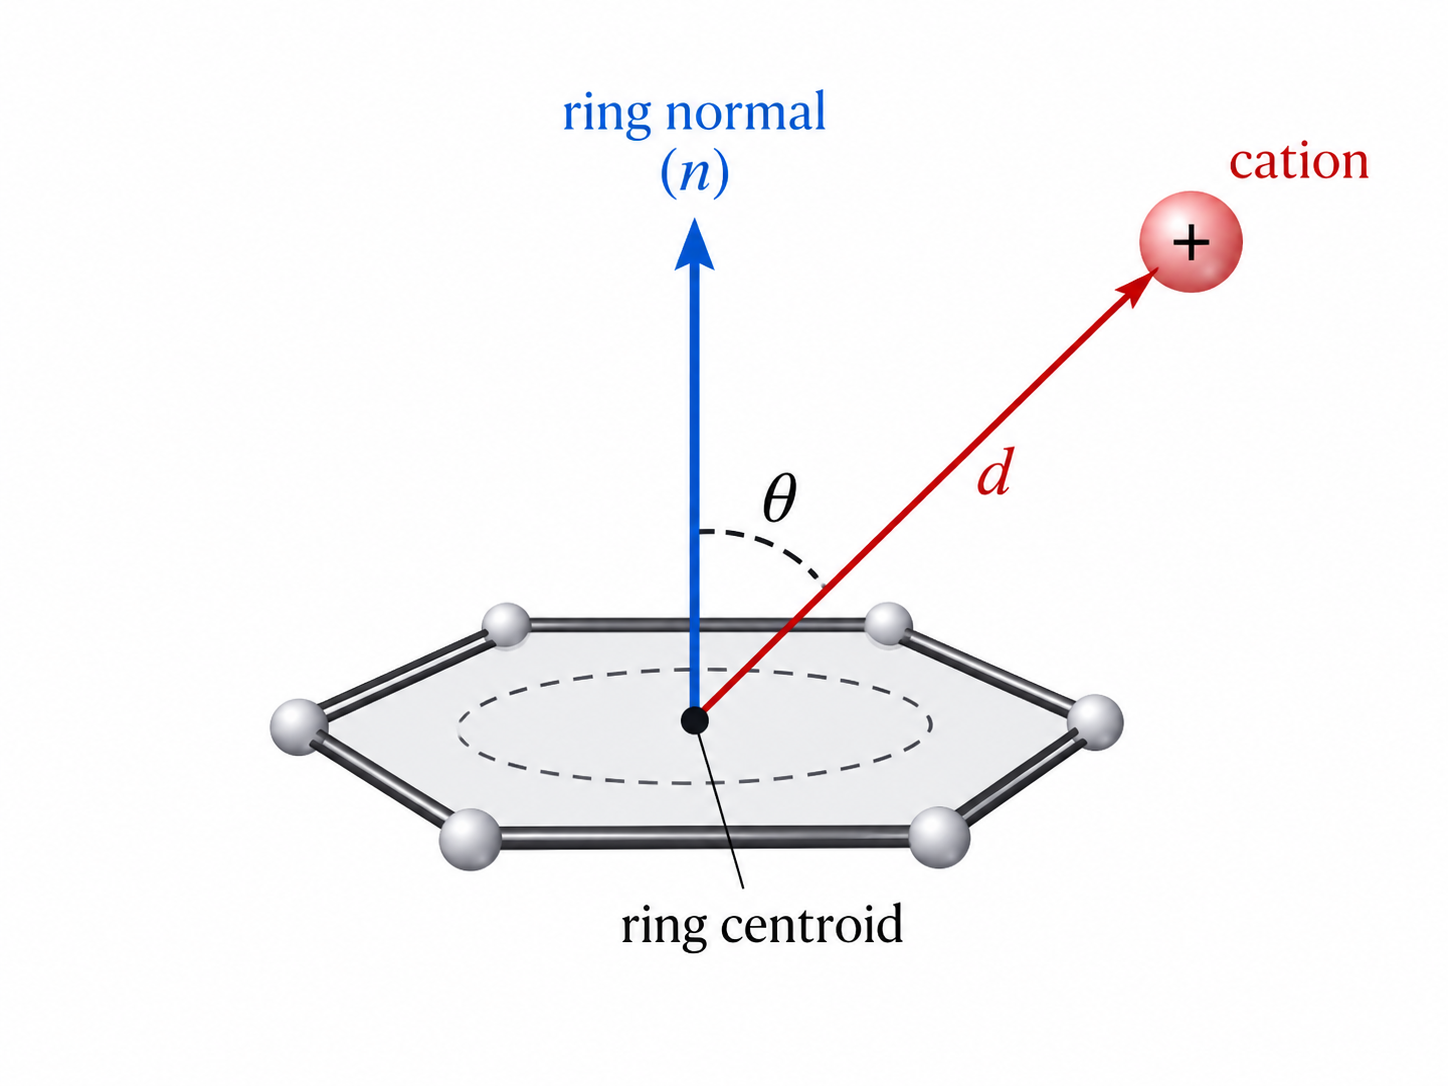
   

---

## 2. Participating Functional Groups in Proteins

In biological systems, $\pi$–cation interactions primarily occur between specific amino acid side chains or ligand functional groups:

| Role | Biological Groups / Amino Acids | Chemical Feature |
| :--- | :--- | :--- |
| **Aromatic Ring ($\pi$-system)** | Phenylalanine (Phe), Tyrosine (Tyr), Tryptophan (Trp) | Quadrupole moment creating a negative electron cloud above and below the aromatic plane. |
| **Cation ($+$ Charge)** | Lysine (Lys, $-\text{NH}_3^+$), Arginine (Arg, Guanidinium group), Protonated Histidine (His) | Full or partial positive charge. |
| **Exogenous Ligands** | Quaternary ammonium compounds (e.g., Acetylcholine), Protonated amines | Synthetic or natural charged ligand functional groups. |

---

## 3. Geometric Criteria for Pi-Cation Detection

To identify a valid $\pi$–cation interaction in 3D structures, algorithms evaluate two key parameters:

1. **Cation-to-Centroid Distance ($d$):**
   * Distance between the positive charge center (e.g., Nitrogen of Lysine or Guanidinium center of Arginine) and the geometric center (centroid) of the aromatic ring.
   * **Typical Cutoff:** $d \le 6.0\,\mathring{\text{A}}$ (strong interactions occur within $3.5–5.0\,\mathring{\text{A}}$).

2. **Offset Angle ($\theta$):**
   * The angle between the vector connecting the centroid to the cation and the normal vector perpendicular to the aromatic ring plane.
   * **Typical Cutoff:** $\theta \le 45^\circ$ (ensures the cation sits above or below the face of the ring rather than along the aromatic edge).

---

## 4. Energetic Significance in Molecular Dynamics & Docking

* **Interaction Energy:** $\pi$–cation interactions are remarkably strong in aqueous solution, often exceeding the energetic strength of standard hydrogen bonds or salt bridges (ranging from $-2$ to $-10\,\text{kcal/mol}$).
* **Desolvation Penalty Mitigation:** The bulky aromatic ring partially shields the cation from water, providing a favorable entropic and enthalpic contribution to binding free energy ($\Delta G$).

In [ ]:
#@markdown Calculation of π –cation interaction.
import os
import glob
import json
import numpy as np
from IPython.display import HTML, display

# ==============================================================================
# CONFIGURATION: DIRECTORIES, THRESHOLDS & FILE PATHS FOR CATION-PI
# Centralized file paths, thresholds, and color mappings.
# ==============================================================================
DISTANCE_THRESHOLD = 5.0  # Ångströms
ANGLE_THRESHOLD = 45.0    # Degrees (0 to 45°)

SYSTEMS_CONFIG = {
    'NCT': {
        'file_pattern': 'MD/cpptraj.6CNK-NCT/*cation-pi-raw.dat',
        'exact_fallback': 'MD/cpptraj.6CNK-NCT/cation-pi-raw.dat',
        'name': '6CNK-NCT',
        'color': '#d97706'
    },
    'C5E': {
        'file_pattern': 'MD/cpptraj.6CNK-C5E/*cation-pi-raw.dat',
        'exact_fallback': 'MD/cpptraj.6CNK-C5E/cation-pi-raw.dat',
        'name': '6CNK-C5E',
        'color': '#2563eb'
    },
    'XRS': {
        'file_pattern': 'MD/cpptraj.6CNK-XRS/*cation-pi-raw.dat',
        'exact_fallback': 'MD/cpptraj.6CNK-XRS/cation-pi-raw.dat',
        'name': '6CNK-XRS',
        'color': '#dc2626'
    },
    'QMR': {
        'file_pattern': 'MD/cpptraj.6CNK-QMR/*cation-pi-raw.dat',
        'exact_fallback': 'MD/cpptraj.6CNK-QMR/cation-pi-raw.dat',
        'name': '6CNK-QMR',
        'color': '#059669'
    },
    'L0B': {
        'file_pattern': 'MD/cpptraj.6CNK-L0B/*cation-pi-raw.dat',
        'exact_fallback': 'MD/cpptraj.6CNK-L0B/cation-pi-raw.dat',
        'name': '6CNK-L0B',
        'color': '#7c3aed'
    },
    'CCE': {
        'file_pattern': 'MD/cpptraj.6CNK-CCE/*cation-pi-raw.dat',
        'exact_fallback': 'MD/cpptraj.6CNK-CCE/cation-pi-raw.dat',
        'name': '6CNK-CCE',
        'color': '#0891b2'
    },
}
# ==============================================================================


def read_cpptraj_cation_pi(filepath):
    """Parse cpptraj cation-pi-raw.dat files (Frame, Distance, Angle)."""
    frames, distances, angles = [], [], []
    if not os.path.exists(filepath):
        return None, None, None
    with open(filepath, 'r') as f:
        for line in f:
            line = line.strip()
            if line.startswith('#') or line.startswith('@') or not line:
                continue
            parts = line.split()
            if len(parts) >= 3:
                try:
                    frame = float(parts[0])
                    dis = float(parts[1])
                    ang = float(parts[2])
                    frames.append(frame)
                    distances.append(dis)
                    angles.append(ang)
                except ValueError:
                    continue
    return frames, distances, angles


# Load trajectory cation-pi data
systems_data = {}

for sys_key, info in SYSTEMS_CONFIG.items():
    matching_files = glob.glob(info['file_pattern'])
    frames, distances, angles = None, None, None

    if matching_files:
        frames, distances, angles = read_cpptraj_cation_pi(matching_files[0])
    elif os.path.exists(info['exact_fallback']):
        frames, distances, angles = read_cpptraj_cation_pi(info['exact_fallback'])

    if distances is not None and len(distances) > 0:
        systems_data[sys_key] = {
            'name': info['name'],
            'color': info['color'],
            'visible': True,
            'frames': frames,
            'distances': distances,
            'angles': angles,
            'isUser': (sys_key == 'NCT')
        }
        print(f"✓ Loaded {info['name']} ({len(distances)} frames)")
    else:
        print(f"⚠ File not found for {sys_key} ({info['exact_fallback']}). Skipping.")

json_systems = json.dumps(systems_data)

html_code = f"""
<!DOCTYPE html>
<html lang="en" class="h-full">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>MD Cation-Pi Interaction Studio</title>
    <script src="https://cdn.tailwindcss.com"></script>
    <script src="https://cdn.plot.ly/plotly-2.27.0.min.js"></script>
    <link rel="stylesheet" href="https://cdnjs.cloudflare.com/ajax/libs/font-awesome/6.4.0/css/all.min.css">
    <link href="https://fonts.googleapis.com/css2?family=Inter:wght@300;400;500;600;700&display=swap" rel="stylesheet">
    <style>
        body {{ font-family: 'Inter', sans-serif; }}
        .glass-panel {{
            background: rgba(255, 255, 255, 0.9);
            backdrop-filter: blur(12px);
            border: 1px solid rgba(229, 231, 235, 0.8);
        }}
        .dark .glass-panel {{
            background: rgba(17, 24, 39, 0.9);
            backdrop-filter: blur(12px);
            border: 1px solid rgba(55, 65, 81, 0.5);
        }}
        .custom-scrollbar::-webkit-scrollbar {{ width: 6px; height: 6px; }}
        .custom-scrollbar::-webkit-scrollbar-track {{ background: transparent; }}
        .custom-scrollbar::-webkit-scrollbar-thumb {{ background: #cbd5e1; border-radius: 9999px; }}
        .dark .custom-scrollbar::-webkit-scrollbar-thumb {{ background: #475569; }}
    </style>
</head>
<body class="bg-slate-50 dark:bg-slate-950 text-slate-800 dark:text-slate-100 p-2 sm:p-4 custom-scrollbar">

    <!-- Header -->
    <header class="glass-panel rounded-2xl p-4 mb-4 flex flex-wrap items-center justify-between gap-3">
        <div class="flex items-center space-x-3">
            <div class="bg-gradient-to-tr from-amber-500 to-red-600 p-2.5 rounded-xl text-white shadow-md">
                <i class="fa-solid fa-atom text-lg"></i>
            </div>
            <div>
                <h1 class="font-bold text-lg leading-tight text-slate-900 dark:text-white">Cation-&pi; Interaction Studio</h1>
                <p class="text-xs text-slate-500 dark:text-slate-400">Trp359 (COM) &ndash; Ligand N1 Geometry Analysis (&le; {DISTANCE_THRESHOLD} &Aring; &amp; &le; {ANGLE_THRESHOLD}&deg;)</p>
            </div>
        </div>
        <div class="flex items-center space-x-2">
            <button onclick="toggleDarkMode()" class="p-2 rounded-lg text-slate-500 dark:text-slate-400 hover:bg-slate-100 dark:hover:bg-slate-800 transition" title="Toggle theme">
                <i class="fa-solid fa-moon text-lg dark:hidden"></i>
                <i class="fa-solid fa-sun text-lg hidden dark:block text-amber-400"></i>
            </button>
        </div>
    </header>

    <!-- Controls -->
    <div class="grid grid-cols-1 md:grid-cols-12 gap-4 mb-4">
        <div class="md:col-span-5 glass-panel rounded-2xl p-4 flex flex-col justify-between">
            <div class="flex justify-between items-center mb-2">
                <label class="text-xs font-semibold uppercase tracking-wider text-slate-500 dark:text-slate-400 flex items-center gap-1.5">
                    <i class="fa-solid fa-sliders text-amber-500"></i> Interaction Thresholds
                </label>
            </div>
            <div class="grid grid-cols-2 gap-3">
                <div>
                    <label class="block text-xs text-slate-500 dark:text-slate-400 mb-1">Max Distance (&Aring;)</label>
                    <input type="number" id="disThresholdInput" value="{DISTANCE_THRESHOLD}" min="1" step="0.5" class="w-full bg-slate-100 dark:bg-slate-800 border border-slate-300 dark:border-slate-700 rounded-lg px-3 py-1.5 text-sm font-medium focus:outline-none focus:ring-2 focus:ring-amber-500" onchange="renderPlot()">
                </div>
                <div>
                    <label class="block text-xs text-slate-500 dark:text-slate-400 mb-1">Max Angle (&deg;)</label>
                    <input type="number" id="angThresholdInput" value="{ANGLE_THRESHOLD}" min="5" step="5" class="w-full bg-slate-100 dark:bg-slate-800 border border-slate-300 dark:border-slate-700 rounded-lg px-3 py-1.5 text-sm font-medium focus:outline-none focus:ring-2 focus:ring-amber-500" onchange="renderPlot()">
                </div>
            </div>
        </div>

        <div class="md:col-span-7 glass-panel rounded-2xl p-4 flex flex-col justify-between">
            <div class="flex justify-between items-center mb-2">
                <span class="text-xs font-semibold uppercase tracking-wider text-slate-500 dark:text-slate-400 flex items-center gap-1.5">
                    <i class="fa-solid fa-filter text-indigo-500"></i> Quick Selection Filters
                </span>
                <span class="text-xs text-slate-500" id="activeCountBadge">0 active systems</span>
            </div>
            <div class="flex flex-wrap gap-2">
                <button onclick="selectAllSystems(true)" class="px-3 py-1.5 text-xs font-medium bg-slate-200 dark:bg-slate-800 hover:bg-slate-300 dark:hover:bg-slate-700 rounded-lg transition">
                    <i class="fa-solid fa-check-double mr-1 text-slate-500"></i> Select All
                </button>
                <button onclick="selectAllSystems(false)" class="px-3 py-1.5 text-xs font-medium bg-slate-200 dark:bg-slate-800 hover:bg-slate-300 dark:hover:bg-slate-700 rounded-lg transition">
                    <i class="fa-solid fa-square-xmark mr-1 text-slate-500"></i> Deselect All
                </button>
                <button onclick="selectOnlyReference()" class="px-3 py-1.5 text-xs font-medium bg-amber-100 dark:bg-amber-950/60 text-amber-700 dark:text-amber-300 border border-amber-200 dark:border-amber-800/50 hover:bg-amber-200 rounded-lg transition">
                    <i class="fa-solid fa-star mr-1"></i> Reference Only (NCT)
                </button>
            </div>
        </div>
    </div>

    <!-- Main Grid -->
    <div class="grid grid-cols-1 lg:grid-cols-4 gap-6 mb-4">
        <div class="lg:col-span-1 glass-panel rounded-2xl p-4 flex flex-col">
            <h2 class="text-sm font-bold tracking-tight text-slate-900 dark:text-white mb-3 flex items-center justify-between">
                <span>Loaded Systems</span>
                <span class="text-xs font-normal text-slate-400">Show/Hide</span>
            </h2>
            <div id="systemsCheckboxesList" class="flex flex-col gap-2.5 overflow-y-auto max-h-[450px] pr-1 custom-scrollbar"></div>
        </div>

        <div class="lg:col-span-3 glass-panel rounded-2xl p-4 flex flex-col justify-between min-h-[460px]">
            <div id="plotlyDistanceDiv" class="w-full h-[240px] mb-2"></div>
            <div id="plotlyAngleDiv" class="w-full h-[240px]"></div>
        </div>
    </div>

    <!-- 2D Phase Map & Statistics -->
    <div class="grid grid-cols-1 lg:grid-cols-12 gap-6 mb-4">
        <div class="lg:col-span-6 glass-panel rounded-2xl p-4">
            <h3 class="font-bold text-slate-900 dark:text-white text-sm mb-2 flex items-center gap-2">
                <i class="fa-solid fa-bullseye text-amber-500"></i> 2D Cation-&pi; Phase Space (Distance vs. Angle)
            </h3>
            <div id="plotlyScatterDiv" class="w-full h-[320px]"></div>
        </div>

        <div class="lg:col-span-6 glass-panel rounded-2xl p-5 flex flex-col justify-between">
            <div>
                <h3 class="font-bold text-slate-900 dark:text-white text-base mb-3 flex items-center gap-2">
                    <i class="fa-solid fa-calculator text-emerald-500"></i> Cation-&pi; Interaction Statistics &amp; Occupancy
                </h3>
                <div class="overflow-x-auto custom-scrollbar">
                    <table class="w-full text-left border-collapse text-sm">
                        <thead>
                            <tr class="border-b border-slate-200 dark:border-slate-800 text-xs font-semibold uppercase tracking-wider text-slate-500 dark:text-slate-400 bg-slate-100/50 dark:bg-slate-800/40">
                                <th class="py-2.5 px-3 rounded-l-lg">System</th>
                                <th class="py-2.5 px-3">Stacked / Total</th>
                                <th class="py-2.5 px-3">Occupancy (%)</th>
                                <th class="py-2.5 px-3 font-mono">Mean Dis (&Aring;)</th>
                                <th class="py-2.5 px-3 rounded-r-lg font-mono">Mean Ang (&deg;)</th>
                            </tr>
                        </thead>
                        <tbody id="statsTableBody" class="divide-y divide-slate-200/60 dark:divide-slate-800/60 font-mono text-xs"></tbody>
                    </table>
                </div>
            </div>
        </div>
    </div>

    <script>
        let systemsData = {json_systems};

        window.addEventListener('DOMContentLoaded', () => {{
            renderCheckboxList();
            renderPlot();
        }});

        function toggleDarkMode() {{
            document.documentElement.classList.toggle('dark');
            renderPlot();
        }}

        function renderCheckboxList() {{
            const container = document.getElementById('systemsCheckboxesList');
            container.innerHTML = '';
            let activeCount = 0;

            Object.keys(systemsData).forEach(key => {{
                const sys = systemsData[key];
                if (sys.visible) activeCount++;

                const item = document.createElement('label');
                item.className = `flex items-center justify-between p-2.5 rounded-xl border transition cursor-pointer ${{
                    sys.visible ? 'bg-slate-100 dark:bg-slate-800/80 border-slate-300 dark:border-slate-700 shadow-sm' : 'bg-transparent border-slate-200 dark:border-slate-800 opacity-60'
                }}`;
                item.innerHTML = `
                    <div class="flex items-center space-x-2.5">
                        <input type="checkbox" ${{sys.visible ? 'checked' : ''}} onchange="toggleSystemVisibility('${{key}}')" class="rounded border-slate-300 text-amber-600 focus:ring-amber-500 h-4 w-4">
                        <span class="w-3 h-3 rounded-full flex-shrink-0" style="background-color: ${{sys.color}}"></span>
                        <span class="text-xs font-semibold text-slate-800 dark:text-slate-200">${{sys.name}}</span>
                    </div>
                    ${{sys.isUser ? '<span class="text-[10px] bg-amber-100 dark:bg-amber-900/50 text-amber-600 dark:text-amber-300 px-1.5 py-0.5 rounded font-medium">Ref</span>' : ''}}
                `;
                container.appendChild(item);
            }});
            document.getElementById('activeCountBadge').innerText = `${{activeCount}} active`;
        }}

        function toggleSystemVisibility(key) {{
            systemsData[key].visible = !systemsData[key].visible;
            renderCheckboxList();
            renderPlot();
        }}

        function selectAllSystems(status) {{
            Object.keys(systemsData).forEach(key => systemsData[key].visible = status);
            renderCheckboxList();
            renderPlot();
        }}

        function selectOnlyReference() {{
            Object.keys(systemsData).forEach(key => systemsData[key].visible = (key === 'NCT'));
            renderCheckboxList();
            renderPlot();
        }}

        function renderPlot() {{
            const isDark = document.documentElement.classList.contains('dark');
            const maxDisThreshold = parseFloat(document.getElementById('disThresholdInput').value) || 5.0;
            const maxAngThreshold = parseFloat(document.getElementById('angThresholdInput').value) || 45.0;

            const disTraces = [];
            const angTraces = [];
            const scatterTraces = [];
            const stats = [];

            Object.keys(systemsData).forEach(key => {{
                const sys = systemsData[key];
                if (!sys.visible) return;

                const totalFrames = sys.distances.length;
                let stackedCount = 0;
                let sumDis = 0;
                let sumAng = 0;

                for (let i = 0; i < totalFrames; i++) {{
                    const d = sys.distances[i];
                    const a = sys.angles[i];
                    sumDis += d;
                    sumAng += a;
                    if (d <= maxDisThreshold && a >= 0 && a <= maxAngThreshold) {{
                        stackedCount++;
                    }}
                }}

                const occupancy = (stackedCount / totalFrames) * 100;

                disTraces.push({{
                    x: sys.frames,
                    y: sys.distances,
                    mode: 'lines',
                    name: sys.name,
                    line: {{ color: sys.color, width: 1.5 }},
                    hovertemplate: `<b>${{sys.name}}</b><br>Frame: %{{x}}<br>Distance: %{{y:.2f}} &Aring;<extra></extra>`
                }});

                angTraces.push({{
                    x: sys.frames,
                    y: sys.angles,
                    mode: 'lines',
                    name: sys.name,
                    line: {{ color: sys.color, width: 1.5 }},
                    hovertemplate: `<b>${{sys.name}}</b><br>Frame: %{{x}}<br>Angle: %{{y:.2f}}&deg;<extra></extra>`
                }});

                scatterTraces.push({{
                    x: sys.distances,
                    y: sys.angles,
                    mode: 'markers',
                    name: sys.name,
                    marker: {{ color: sys.color, size: 4, opacity: 0.5 }},
                    hovertemplate: `<b>${{sys.name}}</b><br>Distance: %{{x:.2f}} &Aring;<br>Angle: %{{y:.2f}}&deg;<extra></extra>`
                }});

                stats.push({{
                    name: sys.name,
                    color: sys.color,
                    stacked: stackedCount,
                    total: totalFrames,
                    occupancy: occupancy.toFixed(2),
                    meanDis: (sumDis / totalFrames).toFixed(2),
                    meanAng: (sumAng / totalFrames).toFixed(2)
                }});
            }});

            const commonLayout = {{
                margin: {{ t: 25, r: 20, l: 55, b: 35 }},
                paper_bgcolor: 'rgba(0,0,0,0)',
                plot_bgcolor: 'rgba(0,0,0,0)',
                font: {{ family: 'Inter, sans-serif', color: isDark ? '#94a3b8' : '#475569' }},
                legend: {{ orientation: 'h', y: 1.25, x: 0, font: {{ size: 10 }} }}
            }};

            // Distance Trajectory Layout
            const disLayout = {{
                ...commonLayout,
                yaxis: {{
                    title: {{ text: 'Distance (&Aring;)', font: {{ size: 11, weight: 600 }} }},
                    gridcolor: isDark ? '#334155' : '#e2e8f0'
                }},
                xaxis: {{ gridcolor: isDark ? '#334155' : '#e2e8f0' }},
                shapes: [{{
                    type: 'line',
                    x0: 0, x1: 1, xref: 'paper',
                    y0: maxDisThreshold, y1: maxDisThreshold,
                    line: {{ color: '#ef4444', width: 1.5, dash: 'dash' }}
                }}]
            }};

            // Angle Trajectory Layout
            const angLayout = {{
                ...commonLayout,
                xaxis: {{
                    title: {{ text: 'Frame Number (#)', font: {{ size: 11, weight: 600 }} }},
                    gridcolor: isDark ? '#334155' : '#e2e8f0'
                }},
                yaxis: {{
                    title: {{ text: 'Angle (&deg;)', font: {{ size: 11, weight: 600 }} }},
                    gridcolor: isDark ? '#334155' : '#e2e8f0'
                }},
                shapes: [{{
                    type: 'line',
                    x0: 0, x1: 1, xref: 'paper',
                    y0: maxAngThreshold, y1: maxAngThreshold,
                    line: {{ color: '#ef4444', width: 1.5, dash: 'dash' }}
                }}]
            }};

            // 2D Phase Map Layout
            const scatterLayout = {{
                margin: {{ t: 25, r: 20, l: 55, b: 45 }},
                paper_bgcolor: 'rgba(0,0,0,0)',
                plot_bgcolor: 'rgba(0,0,0,0)',
                font: {{ family: 'Inter, sans-serif', color: isDark ? '#94a3b8' : '#475569' }},
                xaxis: {{
                    title: {{ text: 'Distance (&Aring;)', font: {{ size: 11, weight: 600 }} }},
                    gridcolor: isDark ? '#334155' : '#e2e8f0'
                }},
                yaxis: {{
                    title: {{ text: 'Angle (&deg;)', font: {{ size: 11, weight: 600 }} }},
                    gridcolor: isDark ? '#334155' : '#e2e8f0'
                }},
                showlegend: false,
                shapes: [
                    {{
                        type: 'line', x0: maxDisThreshold, x1: maxDisThreshold, y0: 0, y1: 90,
                        line: {{ color: '#ef4444', width: 1.5, dash: 'dash' }}
                    }},
                    {{
                        type: 'line', x0: 0, x1: 10, y0: maxAngThreshold, y1: maxAngThreshold,
                        line: {{ color: '#ef4444', width: 1.5, dash: 'dash' }}
                    }}
                ]
            }};

            Plotly.newPlot('plotlyDistanceDiv', disTraces, disLayout, {{ responsive: true, displayModeBar: false }});
            Plotly.newPlot('plotlyAngleDiv', angTraces, angLayout, {{ responsive: true, displayModeBar: false }});
            Plotly.newPlot('plotlyScatterDiv', scatterTraces, scatterLayout, {{ responsive: true, displayModeBar: false }});
            renderStatsTable(stats);
        }}

        function renderStatsTable(stats) {{
            const tbody = document.getElementById('statsTableBody');
            tbody.innerHTML = '';
            stats.forEach(s => {{
                const row = document.createElement('tr');
                row.className = 'hover:bg-slate-100/50 dark:hover:bg-slate-800/50 transition';
                row.innerHTML = `
                    <td class="py-2.5 px-3 font-semibold flex items-center space-x-2">
                        <span class="w-2.5 h-2.5 rounded-full" style="background-color: ${{s.color}}"></span>
                        <span class="text-slate-900 dark:text-white">${{s.name}}</span>
                    </td>
                    <td class="py-2.5 px-3 text-slate-600 dark:text-slate-400">${{s.stacked}} / ${{s.total}}</td>
                    <td class="py-2.5 px-3">
                        <span class="text-xs px-2 py-0.5 rounded-full font-bold ${{
                            parseFloat(s.occupancy) > 50 ? 'bg-emerald-100 dark:bg-emerald-950/60 text-emerald-700 dark:text-emerald-300' :
                            (parseFloat(s.occupancy) > 20 ? 'bg-amber-100 dark:bg-amber-950/60 text-amber-700 dark:text-amber-300' : 'bg-rose-100 dark:bg-rose-950/60 text-rose-700 dark:text-rose-300')
                        }}">${{s.occupancy}}%</span>
                    </td>
                    <td class="py-2.5 px-3 text-slate-600 dark:text-slate-400">${{s.meanDis}}</td>
                    <td class="py-2.5 px-3 text-slate-600 dark:text-slate-400">${{s.meanAng}}</td>
                `;
                tbody.appendChild(row);
            }});
        }}
    </script>
</body>
</html>
"""

# Render interactive view within Google Colab
display(HTML(f'''
<iframe srcdoc="{html_code.replace('"', '&quot;')}" width="100%" height="1100px" style="border:none;"></iframe>
'''))

In [ ]:
#@markdown Calculation of π–cation interaction occupancy
import os
import glob
import json
from IPython.display import HTML, display

# ==============================================================================
# CONFIGURATION: DIRECTORIES & FILE PATHS FOR PROCESSED CATION-PI DATA
# Centralized configuration pointing to 'cation-pi.dat' output files
# ==============================================================================
SYSTEMS_CONFIG = {
    'NCT': {
        'file_pattern': 'MD/cpptraj.6CNK-NCT/*cation-pi.dat',
        'exact_fallback': 'MD/cpptraj.6CNK-NCT/cation-pi.dat',
        'name': '6CNK-NCT',
        'color': '#d97706'
    },
    'C5E': {
        'file_pattern': 'MD/cpptraj.6CNK-C5E/*cation-pi.dat',
        'exact_fallback': 'MD/cpptraj.6CNK-C5E/cation-pi.dat',
        'name': '6CNK-C5E',
        'color': '#2563eb'
    },
    'XRS': {
        'file_pattern': 'MD/cpptraj.6CNK-XRS/*cation-pi.dat',
        'exact_fallback': 'MD/cpptraj.6CNK-XRS/cation-pi.dat',
        'name': '6CNK-XRS',
        'color': '#dc2626'
    },
    'QMR': {
        'file_pattern': 'MD/cpptraj.6CNK-QMR/*cation-pi.dat',
        'exact_fallback': 'MD/cpptraj.6CNK-QMR/cation-pi.dat',
        'name': '6CNK-QMR',
        'color': '#059669'
    },
    'L0B': {
        'file_pattern': 'MD/cpptraj.6CNK-L0B/*cation-pi.dat',
        'exact_fallback': 'MD/cpptraj.6CNK-L0B/cation-pi.dat',
        'name': '6CNK-L0B',
        'color': '#7c3aed'
    },
    'CCE': {
        'file_pattern': 'MD/cpptraj.6CNK-CCE/*cation-pi.dat',
        'exact_fallback': 'MD/cpptraj.6CNK-CCE/cation-pi.dat',
        'name': '6CNK-CCE',
        'color': '#0891b2'
    },
}
# ==============================================================================


def read_processed_cation_pi(filepath):
    """Parse post-processed cation-pi.dat summary lines for total/stacked frames & percentage."""
    if not os.path.exists(filepath):
        return None

    total_frames = 0
    stacked_frames = 0
    percentage = 0.0

    with open(filepath, 'r', encoding='utf-8') as f:
        for line in f:
            line_str = line.strip()
            if line_str.startswith('Total frames:'):
                total_frames = int(line_str.split(':')[1].strip())
            elif line_str.startswith('Total stacked frames:'):
                stacked_frames = int(line_str.split(':')[1].strip())
            elif line_str.startswith('Total stacked %:'):
                percentage = float(line_str.split(':')[1].strip())

    return {
        'total_frames': total_frames,
        'stacked_frames': stacked_frames,
        'percentage': round(percentage, 2)
    }


# Load processed cation-pi results
systems_data = {}

for sys_key, info in SYSTEMS_CONFIG.items():
    matching_files = [f for f in glob.glob(info['file_pattern']) if not f.endswith('cation-pi-raw.dat')]
    parsed_res = None

    if matching_files:
        parsed_res = read_processed_cation_pi(matching_files[0])
    elif os.path.exists(info['exact_fallback']):
        parsed_res = read_processed_cation_pi(info['exact_fallback'])

    if parsed_res is not None and parsed_res['total_frames'] > 0:
        systems_data[sys_key] = {
            'name': info['name'],
            'color': info['color'],
            'visible': True,
            'total_frames': parsed_res['total_frames'],
            'stacked_frames': parsed_res['stacked_frames'],
            'percentage': parsed_res['percentage'],
            'isUser': (sys_key == 'NCT')
        }
        print(f"✓ Loaded {info['name']}: {parsed_res['percentage']}% ({parsed_res['stacked_frames']}/{parsed_res['total_frames']} frames)")
    else:
        print(f"⚠ File not found or empty for {sys_key} ({info['exact_fallback']}). Skipping.")

json_systems = json.dumps(systems_data)

html_code = f"""
<!DOCTYPE html>
<html lang="en" class="h-full">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>Cation-Pi Occupancy Comparison</title>
    <script src="https://cdn.tailwindcss.com"></script>
    <script src="https://cdn.plot.ly/plotly-2.27.0.min.js"></script>
    <link rel="stylesheet" href="https://cdnjs.cloudflare.com/ajax/libs/font-awesome/6.4.0/css/all.min.css">
    <link href="https://fonts.googleapis.com/css2?family=Inter:wght@300;400;500;600;700&display=swap" rel="stylesheet">
    <style>
        body {{ font-family: 'Inter', sans-serif; }}
        .glass-panel {{
            background: rgba(255, 255, 255, 0.9);
            backdrop-filter: blur(12px);
            border: 1px solid rgba(229, 231, 235, 0.8);
        }}
        .dark .glass-panel {{
            background: rgba(17, 24, 39, 0.9);
            backdrop-filter: blur(12px);
            border: 1px solid rgba(55, 65, 81, 0.5);
        }}
        .custom-scrollbar::-webkit-scrollbar {{ width: 6px; height: 6px; }}
        .custom-scrollbar::-webkit-scrollbar-track {{ background: transparent; }}
        .custom-scrollbar::-webkit-scrollbar-thumb {{ background: #cbd5e1; border-radius: 9999px; }}
        .dark .custom-scrollbar::-webkit-scrollbar-thumb {{ background: #475569; }}
    </style>
</head>
<body class="bg-slate-50 dark:bg-slate-950 text-slate-800 dark:text-slate-100 p-2 sm:p-4 custom-scrollbar">

    <!-- Header -->
    <header class="glass-panel rounded-2xl p-4 mb-4 flex flex-wrap items-center justify-between gap-3">
        <div class="flex items-center space-x-3">
            <div class="bg-gradient-to-tr from-amber-500 to-amber-700 p-2.5 rounded-xl text-white shadow-md">
                <i class="fa-solid fa-chart-column text-lg"></i>
            </div>
            <div>
                <h1 class="font-bold text-lg leading-tight text-slate-900 dark:text-white">Cation-&pi; Occupancy Comparison</h1>
                <p class="text-xs text-slate-500 dark:text-slate-400">Percentage of trajectory frames fulfilling Distance &le; 5 &Aring; &amp; Angle &le; 45&deg;</p>
            </div>
        </div>
        <div class="flex items-center space-x-2">
            <button onclick="toggleDarkMode()" class="p-2 rounded-lg text-slate-500 dark:text-slate-400 hover:bg-slate-100 dark:hover:bg-slate-800 transition" title="Toggle theme">
                <i class="fa-solid fa-moon text-lg dark:hidden"></i>
                <i class="fa-solid fa-sun text-lg hidden dark:block text-amber-400"></i>
            </button>
        </div>
    </header>

    <!-- Controls -->
    <div class="grid grid-cols-1 md:grid-cols-12 gap-4 mb-4">
        <div class="md:col-span-12 glass-panel rounded-2xl p-4 flex flex-col justify-between">
            <div class="flex justify-between items-center mb-2">
                <span class="text-xs font-semibold uppercase tracking-wider text-slate-500 dark:text-slate-400 flex items-center gap-1.5">
                    <i class="fa-solid fa-filter text-amber-500"></i> Active System Filters
                </span>
                <span class="text-xs text-slate-500" id="activeCountBadge">0 active systems</span>
            </div>
            <div class="flex flex-wrap gap-2">
                <button onclick="selectAllSystems(true)" class="px-3 py-1.5 text-xs font-medium bg-slate-200 dark:bg-slate-800 hover:bg-slate-300 dark:hover:bg-slate-700 rounded-lg transition">
                    <i class="fa-solid fa-check-double mr-1 text-slate-500"></i> Select All
                </button>
                <button onclick="selectAllSystems(false)" class="px-3 py-1.5 text-xs font-medium bg-slate-200 dark:bg-slate-800 hover:bg-slate-300 dark:hover:bg-slate-700 rounded-lg transition">
                    <i class="fa-solid fa-square-xmark mr-1 text-slate-500"></i> Deselect All
                </button>
                <button onclick="selectOnlyReference()" class="px-3 py-1.5 text-xs font-medium bg-amber-100 dark:bg-amber-950/60 text-amber-700 dark:text-amber-300 border border-amber-200 dark:border-amber-800/50 hover:bg-amber-200 rounded-lg transition">
                    <i class="fa-solid fa-star mr-1"></i> Reference Only (NCT)
                </button>
            </div>
        </div>
    </div>

    <!-- Main Grid: Bar Chart + System Toggles -->
    <div class="grid grid-cols-1 lg:grid-cols-4 gap-6 mb-4">
        <div class="lg:col-span-1 glass-panel rounded-2xl p-4 flex flex-col">
            <h2 class="text-sm font-bold tracking-tight text-slate-900 dark:text-white mb-3 flex items-center justify-between">
                <span>Loaded Systems</span>
                <span class="text-xs font-normal text-slate-400">Show/Hide</span>
            </h2>
            <div id="systemsCheckboxesList" class="flex flex-col gap-2.5 overflow-y-auto max-h-[420px] pr-1 custom-scrollbar"></div>
        </div>

        <div class="lg:col-span-3 glass-panel rounded-2xl p-4 flex flex-col justify-between min-h-[420px]">
            <div id="plotlyBarDiv" class="w-full h-[400px]"></div>
        </div>
    </div>

    <!-- Summary Table -->
    <div class="glass-panel rounded-2xl p-5">
        <h3 class="font-bold text-slate-900 dark:text-white text-base mb-3 flex items-center gap-2">
            <i class="fa-solid fa-table text-emerald-500"></i> Cation-&pi; Occupancy Summary
        </h3>
        <div class="overflow-x-auto custom-scrollbar">
            <table class="w-full text-left border-collapse text-sm">
                <thead>
                    <tr class="border-b border-slate-200 dark:border-slate-800 text-xs font-semibold uppercase tracking-wider text-slate-500 dark:text-slate-400 bg-slate-100/50 dark:bg-slate-800/40">
                        <th class="py-3 px-4 rounded-l-lg">System / Ligand</th>
                        <th class="py-3 px-4">Stacked Frames</th>
                        <th class="py-3 px-4">Total Frames</th>
                        <th class="py-3 px-4">Occupancy (%)</th>
                        <th class="py-3 px-4 rounded-r-lg">Interaction Level</th>
                    </tr>
                </thead>
                <tbody id="statsTableBody" class="divide-y divide-slate-200/60 dark:divide-slate-800/60 font-mono text-xs sm:text-sm"></tbody>
            </table>
        </div>
    </div>

    <script>
        let systemsData = {json_systems};

        window.addEventListener('DOMContentLoaded', () => {{
            renderCheckboxList();
            renderPlot();
        }});

        function toggleDarkMode() {{
            document.documentElement.classList.toggle('dark');
            renderPlot();
        }}

        function renderCheckboxList() {{
            const container = document.getElementById('systemsCheckboxesList');
            container.innerHTML = '';
            let activeCount = 0;

            Object.keys(systemsData).forEach(key => {{
                const sys = systemsData[key];
                if (sys.visible) activeCount++;

                const item = document.createElement('label');
                item.className = `flex items-center justify-between p-2.5 rounded-xl border transition cursor-pointer ${{
                    sys.visible ? 'bg-slate-100 dark:bg-slate-800/80 border-slate-300 dark:border-slate-700 shadow-sm' : 'bg-transparent border-slate-200 dark:border-slate-800 opacity-60'
                }}`;
                item.innerHTML = `
                    <div class="flex items-center space-x-2.5">
                        <input type="checkbox" ${{sys.visible ? 'checked' : ''}} onchange="toggleSystemVisibility('${{key}}')" class="rounded border-slate-300 text-amber-600 focus:ring-amber-500 h-4 w-4">
                        <span class="w-3 h-3 rounded-full flex-shrink-0" style="background-color: ${{sys.color}}"></span>
                        <span class="text-xs font-semibold text-slate-800 dark:text-slate-200">${{sys.name}}</span>
                    </div>
                    ${{sys.isUser ? '<span class="text-[10px] bg-amber-100 dark:bg-amber-900/50 text-amber-600 dark:text-amber-300 px-1.5 py-0.5 rounded font-medium">Ref</span>' : ''}}
                `;
                container.appendChild(item);
            }});
            document.getElementById('activeCountBadge').innerText = `${{activeCount}} active`;
        }}

        function toggleSystemVisibility(key) {{
            systemsData[key].visible = !systemsData[key].visible;
            renderCheckboxList();
            renderPlot();
        }}

        function selectAllSystems(status) {{
            Object.keys(systemsData).forEach(key => systemsData[key].visible = status);
            renderCheckboxList();
            renderPlot();
        }}

        function selectOnlyReference() {{
            Object.keys(systemsData).forEach(key => systemsData[key].visible = (key === 'NCT'));
            renderCheckboxList();
            renderPlot();
        }}

        function renderPlot() {{
            const isDark = document.documentElement.classList.contains('dark');
            const xNames = [];
            const yValues = [];
            const barColors = [];
            const hoverTexts = [];
            const stats = [];

            Object.keys(systemsData).forEach(key => {{
                const sys = systemsData[key];
                if (!sys.visible) return;

                xNames.push(sys.name);
                yValues.push(sys.percentage);
                barColors.push(sys.color);

                hoverTexts.push(`<b>${{sys.name}}</b><br>Stacked: ${{sys.stacked_frames}} / ${{sys.total_frames}} frames<br>Occupancy: ${{sys.percentage}}%`);

                stats.push({{
                    name: sys.name,
                    color: sys.color,
                    stacked: sys.stacked_frames,
                    total: sys.total_frames,
                    percentage: sys.percentage,
                    level: sys.percentage >= 60 ? 'Strong / High Occupancy' : (sys.percentage >= 25 ? 'Moderate' : 'Low / Transient')
                }});
            }});

            const barTrace = {{
                x: xNames,
                y: yValues,
                type: 'bar',
                marker: {{
                    color: barColors,
                    borderRadius: 8
                }},
                text: yValues.map(v => `${{v}}%`),
                textposition: 'outside',
                hoverinfo: 'text',
                hovertext: hoverTexts
            }};

            const layout = {{
                margin: {{ t: 30, r: 20, l: 60, b: 50 }},
                paper_bgcolor: 'rgba(0,0,0,0)',
                plot_bgcolor: 'rgba(0,0,0,0)',
                font: {{ family: 'Inter, sans-serif', color: isDark ? '#94a3b8' : '#475569' }},
                xaxis: {{
                    title: {{ text: 'System / Ligand', font: {{ size: 13, weight: 600 }} }},
                    gridcolor: isDark ? '#334155' : '#e2e8f0'
                }},
                yaxis: {{
                    title: {{ text: 'Cation-&pi; Occupancy (%)', font: {{ size: 13, weight: 600 }} }},
                    range: [0, 105],
                    gridcolor: isDark ? '#334155' : '#e2e8f0',
                    zerolinecolor: isDark ? '#475569' : '#cbd5e1'
                }}
            }};

            Plotly.newPlot('plotlyBarDiv', [barTrace], layout, {{ responsive: true, displayModeBar: false }});
            renderStatsTable(stats);
        }}

        function renderStatsTable(stats) {{
            const tbody = document.getElementById('statsTableBody');
            tbody.innerHTML = '';
            stats.forEach(s => {{
                const row = document.createElement('tr');
                row.className = 'hover:bg-slate-100/50 dark:hover:bg-slate-800/50 transition';
                row.innerHTML = `
                    <td class="py-3 px-4 font-semibold flex items-center space-x-2">
                        <span class="w-2.5 h-2.5 rounded-full" style="background-color: ${{s.color}}"></span>
                        <span class="text-slate-900 dark:text-white">${{s.name}}</span>
                    </td>
                    <td class="py-3 px-4 text-slate-800 dark:text-slate-200 font-bold">${{s.stacked}}</td>
                    <td class="py-3 px-4 text-slate-600 dark:text-slate-400">${{s.total}}</td>
                    <td class="py-3 px-4 font-bold text-slate-900 dark:text-white">${{s.percentage}}%</td>
                    <td class="py-3 px-4">
                        <span class="text-xs px-2.5 py-1 rounded-full font-medium ${{
                            s.level.includes('Strong') ? 'bg-emerald-100 dark:bg-emerald-950/60 text-emerald-700 dark:text-emerald-300' :
                            (s.level.includes('Moderate') ? 'bg-amber-100 dark:bg-amber-950/60 text-amber-700 dark:text-amber-300' : 'bg-rose-100 dark:bg-rose-950/60 text-rose-700 dark:text-rose-300')
                        }}">${{s.level}}</span>
                    </td>
                `;
                tbody.appendChild(row);
            }});
        }}
    </script>
</body>
</html>
"""

# Render interactive view within Google Colab
display(HTML(f'''
<iframe srcdoc="{html_code.replace('"', '&quot;')}" width="100%" height="850px" style="border:none;"></iframe>
'''))

# Energetic analysis

In [ ]:
#@title Run energetic analysis

%cd MD/

failed_energetic = []

print("==================================================")
logging.info("INITIATING ENERGY ANALYSIS FOR ALL SYSTEMS")
print("==================================================")

for ligand in SYSTEMS:
    system_id = f"6CNK-{ligand}"

    # 1. Comprobar que existen los archivos de MD
    if not check_input_files(ligand):
        failed_energetic.append((system_id, "Incomplete input files"))
        continue

    # 2. Intentar ejecutar el análisis energético
    try:
        run_energetic_analysis(ligand)
    except Exception as e:
        logging.error(f"❌ Energy analysis failed on {system_id}. Error details: {e}")
        failed_energetic.append((system_id, f"Runtime error: {type(e).__name__}"))

# Resumen de resultados al finalizar el bucle
print("\n" + "="*50)
if not failed_energetic:
    logging.info("🎉 ¡Energy analysis COMPLETED WITHOUT ERRORS for all systems!")
else:
    logging.warning("⚠️ SUMMARY OF SYSTEMS THAT FAILED ENERGY ANALYSIS:")
    for sys_id, reason in failed_energetic:
        print(f"   ❌ System: {sys_id} -> Failure reason: {reason}")
print("="*50)

%cd ../

# Molecular Mechanics - Implicit Solvent Model Surface Area (MM-ISMSA )

## 1. What is MM-ISMSA?

**MM-ISMSA** (*Molecular Mechanics - Implicit Solvent Model Surface Area*) is an ultrafast, accurate scoring function specifically designed to calculate binding free energies and rescore **protein-protein docking** poses and trajectory frames.

It achieves accuracy comparable to rigorous end-state methods (such as MM-PBSA and MM-GBSA with $r^2 \sim 0.9$) while dramatically reducing computational overhead down to **0.2 – 5.0 seconds** per calculation.

---

## 2. Energy Decomposition Framework

The total binding free energy ($\Delta G_{\text{bind}}$) in MM-ISMSA is calculated through three primary structural energy terms:

$$\Delta G_{\text{bind}} = \Delta E_{\text{MM}} + \Delta G_{\text{ISM}} + \Delta G_{\text{SA}}$$

### Energy Component Breakdown:

1. **Molecular Mechanics Term ($\Delta E_{\text{MM}}$):**
   * Uses a standard **12-6 Lennard-Jones potential** to model van der Waals dispersion and exchange repulsion forces between inter-protein atom pairs.

2. **Implicit Solvent Model & Electrostatics ($\Delta G_{\text{ISM}}$):**
   * **Charge-Charge Interactions:** Evaluates direct Coulombic electrostatic forces across the protein-protein interface.
   * **Desolvation Penalties:** Assigns individual desolvation cost penalties for each partner protein upon complex formation.
   * **Explicit Hydrogen Bonding Term:** Incorporates a directional H-bond potential for improved interfacial geometry scoring.

3. **Surface Area Solvation Term ($\Delta G_{\text{SA}}$):**
   * Accounts for the non-polar hydrophobic effect calculated from the loss of Solvent-Accessible Surface Area (SASA) upon complexation:
   
$$\Delta G_{\text{SA}} = \gamma \cdot \Delta \text{SASA}$$

---

## 3. Key Performance & Validation Metrics

* **Correlation with APBS / MM-P(G)BSA:** Shows strong correlation ($r^2 \sim 0.9$) across benchmark datasets (tested on 1,242 decoy complexes).
* **Docking Solution Identification:** Correctly identifies the near-native docking pose (closest to crystal structure) as the top energy rank in **80% of test cases**.
* **Computational Speed:** Runs single-frame pairwise residue decompositions in **0.2 – 5.0 seconds**.
* **MD Trajectory Support:** Processes Molecular Dynamics trajectories to output time-averaged binding energies with standard deviations ($\langle \Delta G \rangle \pm \sigma$).

# MM-ISMSA Scoring Function (Detailed Energy Decomposition)

## 1. Overview of MM-ISMSA

**MM-ISMSA** (*Molecular Mechanics - Implicit Solvent Model Surface Area*) is an ultrafast scoring function designed to calculate binding free energies ($\Delta G_{\text{bind}}$) for protein-protein and protein-ligand complexes.

One of its main features is the **individual, independent energy decomposition** of electrostatics, desolvation penalties, and non-polar contributions for both binding partners (receptor $R$ and ligand $L$).

---

## 2. Mathematical Energy Breakdown

The total binding free energy is decomposed into six main energetic terms:

$$\Delta G_{\text{bind}} = \Delta E_{\text{vdw}} + \Delta G_{\text{QQ}} + \Delta G_{\text{desolv, L}} + \Delta G_{\text{desolv, R}} + \Delta G_{\text{hbond}} + \Delta G_{\text{apolar}}$$



---

## 3. Individual Energy Components Explained

| Energy Term | Abbreviation | Physical Description |
| :--- | :--- | :--- |
| **van der Waals** | $\Delta E_{\text{vdw}}$ | Dispersion forces and exchange repulsion modeled by a classic **12-6 Lennard-Jones potential** across the interface. |
| **Direct Electrostatics** | $\Delta G_{\text{QQ}}$ | Intermolecular **Coulombic charge-charge** interactions between charged and polar atoms of the receptor and ligand. |
| **Ligand Desolvation** | $\Delta G_{\text{desolv, L}}$ | Electrostatic **energy penalty** paid by the ligand to transfer its polar/charged groups from bulk water into the low-dielectric binding site. |
| **Receptor Desolvation** | $\Delta G_{\text{desolv, R}}$ | Electrostatic **energy penalty** paid by the receptor pocket to desolvate its interface residues upon complex formation. |
| **Hydrogen Bonding** | $\Delta G_{\text{hbond}}$ | Explicit directional term accounting for short-range directional donor-acceptor H-bond stabilization. |
| **Apolar / Hydrophobic** | $\Delta G_{\text{apolar}}$ | Hydrophobic contribution calculated linearly from the change in **Solvent-Accessible Surface Area ($\Delta\text{SASA}$)** upon complex formation ($\gamma \cdot \Delta\text{SASA}$). |

---

## 4. Key Advantages of Independent Desolvation Terms

Unlike standard implicit solvent models (such as standard GB) that output solvation as a single unified value ($\Delta G_{\text{solv}}$), MM-ISMSA calculates **independent desolvation penalties for receptor and ligand** ($\Delta G_{\text{desolv, R}}$ and $\Delta G_{\text{desolv, L}}$):

1. **Per-Residue Energy Mapping:** Enables precise identification of which specific residue on the receptor or ligand contributes favorably (strong Coulombic attraction) vs unfavorably (high desolvation penalty) to binding.
2. **Desolvation vs Electrostatic Balance:** Solves the common artifact where highly charged residues appear over-stabilized by showing the exact desolvation cost required to bury those charges.
3. **Ultrafast Performance:** Computes the full 6-component breakdown in **0.2 – 5.0 seconds** per complex or trajectory frame.

In [ ]:
#@markdown MM/ISMSA Binding Free Energy Studio

import os
import glob
import json
from IPython.display import HTML, display

# ==============================================================================
# CONFIGURATION: DIRECTORIES & FILE PATHS FOR MM/ISMSA ENERGIES
# ==============================================================================
SYSTEMS_CONFIG = {
    'C5E': {
        'file_pattern': 'MD/mmismsa.6CNK-C5E/*energy_averages',
        'exact_fallback': '/content/MD/mmismsa.6CNK-C5E/mmismsa.C5E_energy_averages',
        'name': '6CNK-C5E',
        'color': '#2563eb'
    },
    'XRS': {
        'file_pattern': 'MD/mmismsa.6CNK-XRS/*energy_averages',
        'exact_fallback': '/content/MD/mmismsa.6CNK-XRS/mmismsa.XRS_energy_averages',
        'name': '6CNK-XRS',
        'color': '#dc2626'
    },
    'QMR': {
        'file_pattern': 'MD/mmismsa.6CNK-QMR/*energy_averages',
        'exact_fallback': '/content/MD/mmismsa.6CNK-QMR/mmismsa.QMR_energy_averages',
        'name': '6CNK-QMR',
        'color': '#059669'
    },
    'NCT': {
        'file_pattern': 'MD/mmismsa.6CNK-NCT/*energy_averages',
        'exact_fallback': '/content/MD/mmismsa.6CNK-NCT/mmismsa.NCT_energy_averages',
        'name': '6CNK-NCT',
        'color': '#d97706'
    },
    'L0B': {
        'file_pattern': 'MD/mmismsa.6CNK-L0B/*energy_averages',
        'exact_fallback': '/content/MD/mmismsa.6CNK-L0B/mmismsa.L0B_energy_averages',
        'name': '6CNK-L0B',
        'color': '#7c3aed'
    },
    'CCE': {
        'file_pattern': 'MD/mmismsa.6CNK-CCE/*energy_averages',
        'exact_fallback': '/content/MD/mmismsa.6CNK-CCE/mmismsa.CCE_energy_averages',
        'name': '6CNK-CCE',
        'color': '#0891b2'
    },
}
# ==============================================================================


def read_mmismsa_energy(filepath):
    """Parse MMISMSA energy averages file with semicolon delimiters."""
    if not os.path.exists(filepath):
        return None

    with open(filepath, 'r', encoding='utf-8') as f:
        lines = [line.strip() for line in f if line.strip()]

    if len(lines) < 2:
        return None

    headers = [h.strip() for h in lines[0].split(';')]
    values = [float(v.strip()) for v in lines[1].split(';')]

    data_dict = dict(zip(headers, values))

    return {
        'vdw': round(data_dict.get('VDW', 0.0), 2),
        'qq': round(data_dict.get('QQ', 0.0), 2),
        'desolv_lig': round(data_dict.get('DesolvLigand', 0.0), 2),
        'desolv_rec': round(data_dict.get('DesolvReceptor', 0.0), 2),
        'apolar': round(data_dict.get('Apolar', 0.0), 2),
        'total': round(data_dict.get('Total', 0.0), 2),
        'std_vdw': round(data_dict.get('Std VDW', 0.0), 2),
        'std_qq': round(data_dict.get('Std QQ', 0.0), 2),
        'std_desolv_lig': round(data_dict.get('Std DesolvLigand', 0.0), 2),
        'std_desolv_rec': round(data_dict.get('Std DesolvReceptor', 0.0), 2),
        'std_apolar': round(data_dict.get('Std Apolar', 0.0), 2),
        'std_total': round(data_dict.get('Std Total', 0.0), 2)
    }


# Load energy data for each system
systems_data = {}

for sys_key, info in SYSTEMS_CONFIG.items():
    matching_files = glob.glob(info['file_pattern'])
    energy_data = None

    if matching_files:
        energy_data = read_mmismsa_energy(matching_files[0])
    elif os.path.exists(info['exact_fallback']):
        energy_data = read_mmismsa_energy(info['exact_fallback'])

    if energy_data is not None:
        systems_data[sys_key] = {
            'name': info['name'],
            'color': info['color'],
            'visible': True,
            'energy': energy_data,
            'isUser': (sys_key == 'C5E')
        }
        print(f"✓ Loaded {info['name']}: Total ΔG = {energy_data['total']} ± {energy_data['std_total']} kcal/mol")
    else:
        print(f"⚠ Energy file not found for {sys_key} ({info['exact_fallback']}). Skipping.")

json_systems = json.dumps(systems_data)

html_code = f"""
<!DOCTYPE html>
<html lang="en" class="h-full">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>MM/ISMSA Binding Free Energy Studio</title>
    <script src="https://cdn.tailwindcss.com"></script>
    <script src="https://cdn.plot.ly/plotly-2.27.0.min.js"></script>
    <link rel="stylesheet" href="https://cdnjs.cloudflare.com/ajax/libs/font-awesome/6.4.0/css/all.min.css">
    <link href="https://fonts.googleapis.com/css2?family=Inter:wght@300;400;500;600;700&display=swap" rel="stylesheet">
    <style>
        body {{ font-family: 'Inter', sans-serif; }}
        .glass-panel {{
            background: rgba(255, 255, 255, 0.9);
            backdrop-filter: blur(12px);
            border: 1px solid rgba(229, 231, 235, 0.8);
        }}
        .dark .glass-panel {{
            background: rgba(17, 24, 39, 0.9);
            backdrop-filter: blur(12px);
            border: 1px solid rgba(55, 65, 81, 0.5);
        }}
        .custom-scrollbar::-webkit-scrollbar {{ width: 6px; height: 6px; }}
        .custom-scrollbar::-webkit-scrollbar-track {{ background: transparent; }}
        .custom-scrollbar::-webkit-scrollbar-thumb {{ background: #cbd5e1; border-radius: 9999px; }}
        .dark .custom-scrollbar::-webkit-scrollbar-thumb {{ background: #475569; }}
    </style>
</head>
<body class="bg-slate-50 dark:bg-slate-950 text-slate-800 dark:text-slate-100 p-2 sm:p-4 custom-scrollbar">

    <!-- Header -->
    <header class="glass-panel rounded-2xl p-4 mb-4 flex flex-wrap items-center justify-between gap-3">
        <div class="flex items-center space-x-3">
            <div class="bg-gradient-to-tr from-emerald-600 to-teal-700 p-2.5 rounded-xl text-white shadow-md">
                <i class="fa-solid fa-bolt text-lg"></i>
            </div>
            <div>
                <h1 class="font-bold text-lg leading-tight text-slate-900 dark:text-white">MM/ISMSA Binding Free Energy Studio</h1>
                <p class="text-xs text-slate-500 dark:text-slate-400">Energy Component Decomposition with Error Bars (&Delta;G &plusmn; SD in kcal/mol)</p>
            </div>
        </div>
        <div class="flex items-center space-x-2">
            <button onclick="toggleDarkMode()" class="p-2 rounded-lg text-slate-500 dark:text-slate-400 hover:bg-slate-100 dark:hover:bg-slate-800 transition" title="Toggle theme">
                <i class="fa-solid fa-moon text-lg dark:hidden"></i>
                <i class="fa-solid fa-sun text-lg hidden dark:block text-amber-400"></i>
            </button>
        </div>
    </header>

    <!-- Controls -->
    <div class="grid grid-cols-1 md:grid-cols-12 gap-4 mb-4">
        <div class="md:col-span-12 glass-panel rounded-2xl p-4 flex flex-col justify-between">
            <div class="flex justify-between items-center mb-2">
                <span class="text-xs font-semibold uppercase tracking-wider text-slate-500 dark:text-slate-400 flex items-center gap-1.5">
                    <i class="fa-solid fa-filter text-emerald-500"></i> Active System Filters
                </span>
                <span class="text-xs text-slate-500" id="activeCountBadge">0 active systems</span>
            </div>
            <div class="flex flex-wrap gap-2">
                <button onclick="selectAllSystems(true)" class="px-3 py-1.5 text-xs font-medium bg-slate-200 dark:bg-slate-800 hover:bg-slate-300 dark:hover:bg-slate-700 rounded-lg transition">
                    <i class="fa-solid fa-check-double mr-1 text-slate-500"></i> Select All
                </button>
                <button onclick="selectAllSystems(false)" class="px-3 py-1.5 text-xs font-medium bg-slate-200 dark:bg-slate-800 hover:bg-slate-300 dark:hover:bg-slate-700 rounded-lg transition">
                    <i class="fa-solid fa-square-xmark mr-1 text-slate-500"></i> Deselect All
                </button>
                <button onclick="selectOnlyReference()" class="px-3 py-1.5 text-xs font-medium bg-blue-100 dark:bg-blue-950/60 text-blue-700 dark:text-blue-300 border border-blue-200 dark:border-blue-800/50 hover:bg-blue-200 rounded-lg transition">
                    <i class="fa-solid fa-star mr-1"></i> Reference Only (C5E)
                </button>
            </div>
        </div>
    </div>

    <!-- Main Grid: Decomposed Energy Bar Chart & System List -->
    <div class="grid grid-cols-1 lg:grid-cols-4 gap-6 mb-4">
        <div class="lg:col-span-1 glass-panel rounded-2xl p-4 flex flex-col">
            <h2 class="text-sm font-bold tracking-tight text-slate-900 dark:text-white mb-3 flex items-center justify-between">
                <span>Loaded Systems</span>
                <span class="text-xs font-normal text-slate-400">Show/Hide</span>
            </h2>
            <div id="systemsCheckboxesList" class="flex flex-col gap-2.5 overflow-y-auto max-h-[420px] pr-1 custom-scrollbar"></div>
        </div>

        <div class="lg:col-span-3 glass-panel rounded-2xl p-4 flex flex-col justify-between min-h-[420px]">
            <div id="plotlyBarDiv" class="w-full h-[400px]"></div>
        </div>
    </div>

    <!-- Energy Summary Table -->
    <div class="glass-panel rounded-2xl p-5">
        <h3 class="font-bold text-slate-900 dark:text-white text-base mb-3 flex items-center gap-2">
            <i class="fa-solid fa-table text-emerald-500"></i> Decomposed Energy Components (&Delta;G &plusmn; SD kcal/mol)
        </h3>
        <div class="overflow-x-auto custom-scrollbar">
            <table class="w-full text-left border-collapse text-sm">
                <thead>
                    <tr class="border-b border-slate-200 dark:border-slate-800 text-xs font-semibold uppercase tracking-wider text-slate-500 dark:text-slate-400 bg-slate-100/50 dark:bg-slate-800/40">
                        <th class="py-3 px-4 rounded-l-lg">System / Ligand</th>
                        <th class="py-3 px-4">van der Waals (&Delta;VDW)</th>
                        <th class="py-3 px-4">Electrostatic (&Delta;QQ)</th>
                        <th class="py-3 px-4">Desolv Ligand</th>
                        <th class="py-3 px-4">Desolv Receptor</th>
                        <th class="py-3 px-4">Apolar Solv</th>
                        <th class="py-3 px-4 rounded-r-lg font-bold text-slate-900 dark:text-white">Total Binding &Delta;G</th>
                    </tr>
                </thead>
                <tbody id="statsTableBody" class="divide-y divide-slate-200/60 dark:divide-slate-800/60 font-mono text-xs sm:text-sm"></tbody>
            </table>
        </div>
    </div>

    <script>
        let systemsData = {json_systems};

        window.addEventListener('DOMContentLoaded', () => {{
            renderCheckboxList();
            renderPlot();
        }});

        function toggleDarkMode() {{
            document.documentElement.classList.toggle('dark');
            renderPlot();
        }}

        function renderCheckboxList() {{
            const container = document.getElementById('systemsCheckboxesList');
            container.innerHTML = '';
            let activeCount = 0;

            Object.keys(systemsData).forEach(key => {{
                const sys = systemsData[key];
                if (sys.visible) activeCount++;

                const item = document.createElement('label');
                item.className = `flex items-center justify-between p-2.5 rounded-xl border transition cursor-pointer ${{
                    sys.visible ? 'bg-slate-100 dark:bg-slate-800/80 border-slate-300 dark:border-slate-700 shadow-sm' : 'bg-transparent border-slate-200 dark:border-slate-800 opacity-60'
                }}`;
                item.innerHTML = `
                    <div class="flex items-center space-x-2.5">
                        <input type="checkbox" ${{sys.visible ? 'checked' : ''}} onchange="toggleSystemVisibility('${{key}}')" class="rounded border-slate-300 text-emerald-600 focus:ring-emerald-500 h-4 w-4">
                        <span class="w-3 h-3 rounded-full flex-shrink-0" style="background-color: ${{sys.color}}"></span>
                        <span class="text-xs font-semibold text-slate-800 dark:text-slate-200">${{sys.name}}</span>
                    </div>
                    ${{sys.isUser ? '<span class="text-[10px] bg-blue-100 dark:bg-blue-900/50 text-blue-600 dark:text-blue-300 px-1.5 py-0.5 rounded font-medium">Ref</span>' : ''}}
                `;
                container.appendChild(item);
            }});
            document.getElementById('activeCountBadge').innerText = `${{activeCount}} active`;
        }}

        function toggleSystemVisibility(key) {{
            systemsData[key].visible = !systemsData[key].visible;
            renderCheckboxList();
            renderPlot();
        }}

        function selectAllSystems(status) {{
            Object.keys(systemsData).forEach(key => systemsData[key].visible = status);
            renderCheckboxList();
            renderPlot();
        }}

        function selectOnlyReference() {{
            Object.keys(systemsData).forEach(key => systemsData[key].visible = (key === 'C5E'));
            renderCheckboxList();
            renderPlot();
        }}

        function renderPlot() {{
            const isDark = document.documentElement.classList.contains('dark');
            const xNames = [];
            const vdwVals = [], qqVals = [], desolvLigVals = [], desolvRecVals = [], apolarVals = [], totalVals = [];
            const vdwErrs = [], qqErrs = [], desolvLigErrs = [], desolvRecErrs = [], apolarErrs = [], totalErrs = [];
            const stats = [];

            Object.keys(systemsData).forEach(key => {{
                const sys = systemsData[key];
                if (!sys.visible) return;

                const e = sys.energy;
                xNames.push(sys.name);
                vdwVals.push(e.vdw);
                qqVals.push(e.qq);
                desolvLigVals.push(e.desolv_lig);
                desolvRecVals.push(e.desolv_rec);
                apolarVals.push(e.apolar);
                totalVals.push(e.total);

                vdwErrs.push(e.std_vdw);
                qqErrs.push(e.std_qq);
                desolvLigErrs.push(e.std_desolv_lig);
                desolvRecErrs.push(e.std_desolv_rec);
                apolarErrs.push(e.std_apolar);
                totalErrs.push(e.std_total);

                stats.push({{
                    name: sys.name,
                    color: sys.color,
                    vdw: `${{e.vdw}} &plusmn; ${{e.std_vdw}}`,
                    qq: `${{e.qq}} &plusmn; ${{e.std_qq}}`,
                    desolv_lig: `${{e.desolv_lig}} &plusmn; ${{e.std_desolv_lig}}`,
                    desolv_rec: `${{e.desolv_rec}} &plusmn; ${{e.std_desolv_rec}}`,
                    apolar: `${{e.apolar}} &plusmn; ${{e.std_apolar}}`,
                    total: `${{e.total}} &plusmn; ${{e.std_total}}`
                }});
            }});

            const traceVDW = {{
                x: xNames,
                y: vdwVals,
                name: 'VDW',
                type: 'bar',
                marker: {{ color: '#3b82f6' }},
                error_y: {{ type: 'data', array: vdwErrs, visible: true, thickness: 1.2, width: 4 }}
            }};

            const traceQQ = {{
                x: xNames,
                y: qqVals,
                name: 'Electrostatic (QQ)',
                type: 'bar',
                marker: {{ color: '#8b5cf6' }},
                error_y: {{ type: 'data', array: qqErrs, visible: true, thickness: 1.2, width: 4 }}
            }};

            const traceDesolvLig = {{
                x: xNames,
                y: desolvLigVals,
                name: 'Desolv Ligand',
                type: 'bar',
                marker: {{ color: '#f59e0b' }},
                error_y: {{ type: 'data', array: desolvLigErrs, visible: true, thickness: 1.2, width: 4 }}
            }};

            const traceDesolvRec = {{
                x: xNames,
                y: desolvRecVals,
                name: 'Desolv Receptor',
                type: 'bar',
                marker: {{ color: '#ef4444' }},
                error_y: {{ type: 'data', array: desolvRecErrs, visible: true, thickness: 1.2, width: 4 }}
            }};

            const traceApolar = {{
                x: xNames,
                y: apolarVals,
                name: 'Apolar',
                type: 'bar',
                marker: {{ color: '#06b6d4' }},
                error_y: {{ type: 'data', array: apolarErrs, visible: true, thickness: 1.2, width: 4 }}
            }};

            const traceTotal = {{
                x: xNames,
                y: totalVals,
                name: 'Total Binding ΔG',
                type: 'bar',
                marker: {{ color: '#10b981' }},
                error_y: {{ type: 'data', array: totalErrs, visible: true, thickness: 1.5, width: 5 }},
                text: totalVals.map(v => `${{v}}`),
                textposition: 'outside'
            }};

            const layout = {{
                barmode: 'group',
                margin: {{ t: 40, r: 20, l: 60, b: 50 }},
                paper_bgcolor: 'rgba(0,0,0,0)',
                plot_bgcolor: 'rgba(0,0,0,0)',
                font: {{ family: 'Inter, sans-serif', color: isDark ? '#94a3b8' : '#475569' }},
                xaxis: {{
                    title: {{ text: 'System / Ligand', font: {{ size: 13, weight: 600 }} }},
                    gridcolor: isDark ? '#334155' : '#e2e8f0'
                }},
                yaxis: {{
                    title: {{ text: 'Energy (kcal/mol)', font: {{ size: 13, weight: 600 }} }},
                    gridcolor: isDark ? '#334155' : '#e2e8f0',
                    zerolinecolor: isDark ? '#475569' : '#cbd5e1'
                }},
                legend: {{ orientation: 'h', y: 1.15, x: 0, font: {{ size: 11 }} }}
            }};

            Plotly.newPlot('plotlyBarDiv', [traceVDW, traceQQ, traceDesolvLig, traceDesolvRec, traceApolar, traceTotal], layout, {{ responsive: true, displayModeBar: false }});
            renderStatsTable(stats);
        }}

        function renderStatsTable(stats) {{
            const tbody = document.getElementById('statsTableBody');
            tbody.innerHTML = '';
            stats.forEach(s => {{
                const row = document.createElement('tr');
                row.className = 'hover:bg-slate-100/50 dark:hover:bg-slate-800/50 transition';
                row.innerHTML = `
                    <td class="py-3 px-4 font-semibold flex items-center space-x-2">
                        <span class="w-2.5 h-2.5 rounded-full" style="background-color: ${{s.color}}"></span>
                        <span class="text-slate-900 dark:text-white">${{s.name}}</span>
                    </td>
                    <td class="py-3 px-4 text-slate-600 dark:text-slate-400">${{s.vdw}}</td>
                    <td class="py-3 px-4 text-slate-600 dark:text-slate-400">${{s.qq}}</td>
                    <td class="py-3 px-4 text-slate-600 dark:text-slate-400">${{s.desolv_lig}}</td>
                    <td class="py-3 px-4 text-slate-600 dark:text-slate-400">${{s.desolv_rec}}</td>
                    <td class="py-3 px-4 text-slate-600 dark:text-slate-400">${{s.apolar}}</td>
                    <td class="py-3 px-4 font-bold text-emerald-600 dark:text-emerald-400">${{s.total}}</td>
                `;
                tbody.appendChild(row);
            }});
        }}
    </script>
</body>
</html>
"""

# Render interactive view within Google Colab
display(HTML(f'''
<iframe srcdoc="{html_code.replace('"', '&quot;')}" width="100%" height="850px" style="border:none;"></iframe>
'''))

# Binding Free Energy (ΔG_bind = ΔH_bind - TΔS_bind)

## 1. Thermodynamic Framework of Molecular Binding

In molecular docking and structural biology, the spontaneity and affinity of binding between a receptor ($R$) and a ligand ($L$) to form a complex ($RL$) is governed by the change in **Binding Free Energy ($\Delta G_{\text{bind}}$)**:

$$\Delta G_{\text{bind}} = \Delta H_{\text{bind}} - T\Delta S_{\text{bind}}$$

* **$\Delta G_{\text{bind}} < 0$ (Favorable Binding):** The bound complex $RL$ is thermodynamically more stable than the separated components.
* **Relation to Binding Affinity ($K_d$):** $\Delta G_{\text{bind}}$ directly relates to the experimental dissociation constant ($K_d$) via:

$$\Delta G_{\text{bind}}^\circ = R T \ln(K_d)$$

*(Where a lower $K_d$ indicates stronger binding affinity and a more negative $\Delta G_{\text{bind}}$).*

---

## 2. Enthalpic Contributions to Binding (ΔH_bind)

**$\Delta H_{\text{bind}}$** represents the net heat energy released or absorbed due to non-covalent bond formation and bond breaking.

$$\Delta H_{\text{bind}} = \Delta H_{\text{vdW}} + \Delta H_{\text{QQ}}$$

### Primary Enthalpic Forces:
* **Hydrogen Bonds ($\Delta H < 0$):** Directional electrostatic forces between polar donors ($N-H, O-H$) and acceptors ($N, O$).
* **Electrostatics & Salt Bridges ($\Delta H < 0$):** Direct Coulombic attraction between opposite formal charges (e.g., Lysine $\text{NH}_3^+$ to Aspartate $\text{COO}^-$).
* **Van der Waals / Dispersion ($\Delta H < 0$):** Short-range packed atomic contacts modeled by Lennard-Jones potentials.


---

## 3. Entropic Contributions to Binding (ΔS_bind)

**$\Delta S_{\text{bind}}$** measures the net change in system disorder upon complexation.

$$\Delta S_{\text{bind}} = \Delta S_{\text{solv}} + \Delta S_{\text{conf}} + \Delta S_{\text{rt}}$$

### Key Entropic Drivers:

1. **Hydrophobic Effect ($\Delta S_{\text{solv}} > 0$, Favorable):**
   * Bulk water molecules form rigid, ordered "clathrate-like" cages around non-polar regions of isolated proteins/ligands.
   * Upon binding, these hydrophobic surfaces bury against each other, **releasing ordered water into the bulk liquid**.
   * This vast increase in solvent entropy is a primary driving force of biological binding.

2. **Conformational Entropy Loss ($\Delta S_{\text{conf}} < 0$, Unfavorable):**
   * Free ligands and unfolded protein loops have high rotatable bond flexibility in solution.
   * Upon binding inside a rigid pocket, side-chain and backbone rotatable bonds freeze into fixed conformations, causing an entropic penalty.

3. **Translational & Rotational Entropy Loss ($\Delta S_{\text{rt}} < 0$, Unfavorable):**
   * Two freely moving independent molecules merge into one single complex, losing 6 degrees of translational and rotational freedom.

However, **calculating the conformational entropy change ($\Delta S_{\text{conf}}$) directly is notoriously difficult, computationally expensive, and noisy** due to several factors:

* **High-Dimensional Phase Space:** Calculating entropy requires sampling the complete conformational phase space (all microstates) of both the free receptor, free ligand, and bound complex.
* **Normal Mode Analysis (NMA) Costs:** Traditional NMA requires diagonalizing large Hessian matrices ($3N \times 3N$) for every snapshot, which scales cubically $\mathcal{O}(N^3)$ with atom count.
* **High Statistical Uncertainty:** Harmonic approximations often overestimate energy barriers for floppy, unconstrained surface loops and rotatable bonds, introducing severe noise into the total binding free energy ($\Delta G_{\text{bind}}$).

Because direct entropy calculations are often unreliable or intractable for large trajectories, computational approaches rearrange the fundamental Gibbs free energy equation:

$$\Delta G = \Delta H - T\Delta S \implies -T\Delta S = \Delta G - \Delta H$$



---

## 4. Enthalpy-Entropy Compensation

In drug design and structural optimization, **Enthalpy-Entropy Compensation** is a widespread phenomenon:

* Adding rigid or bulky chemical groups to increase van der Waals contacts ($\Delta H \downarrow$) often restricts local mobility ($\Delta S \downarrow$), offsetting overall net $\Delta G_{\text{bind}}$ gains.
* High-affinity binding requires balancing strong favorable enthalpy ($\Delta H \ll 0$) with hydrophobic water displacement ($\Delta S_{\text{solv}} \gg 0$) while minimizing conformational penalties.

In [ ]:
#@title Per-Residue Energy Mapping

import os
import glob
import json
import math
from IPython.display import HTML, display

# ==============================================================================
# CONFIGURATION: DIRECTORIES & FILE PATHS FOR MM/ISMSA ENERGIES
# ==============================================================================
SYSTEMS_CONFIG = {
    'C5E': {
        'file_pattern': 'MD/mmismsa.6CNK-C5E/*energy_averages',
        'exact_fallback': '/content/MD/mmismsa.6CNK-C5E/mmismsa.C5E_energy_averages',
        'name': '6CNK-C5E',
        'color': '#2563eb'
    },
    'XRS': {
        'file_pattern': 'MD/mmismsa.6CNK-XRS/*energy_averages',
        'exact_fallback': '/content/MD/mmismsa.6CNK-XRS/mmismsa.XRS_energy_averages',
        'name': '6CNK-XRS',
        'color': '#dc2626'
    },
    'QMR': {
        'file_pattern': 'MD/mmismsa.6CNK-QMR/*energy_averages',
        'exact_fallback': '/content/MD/mmismsa.6CNK-QMR/mmismsa.QMR_energy_averages',
        'name': '6CNK-QMR',
        'color': '#059669'
    },
    'NCT': {
        'file_pattern': 'MD/mmismsa.6CNK-NCT/*energy_averages',
        'exact_fallback': '/content/MD/mmismsa.6CNK-NCT/mmismsa.NCT_energy_averages',
        'name': '6CNK-NCT',
        'color': '#d97706'
    },
    'L0B': {
        'file_pattern': 'MD/mmismsa.6CNK-L0B/*energy_averages',
        'exact_fallback': '/content/MD/mmismsa.6CNK-L0B/mmismsa.L0B_energy_averages',
        'name': '6CNK-L0B',
        'color': '#7c3aed'
    },
    'CCE': {
        'file_pattern': 'MD/mmismsa.6CNK-CCE/*energy_averages',
        'exact_fallback': '/content/MD/mmismsa.6CNK-CCE/mmismsa.CCE_energy_averages',
        'name': '6CNK-CCE',
        'color': '#0891b2'
    },
}
# ==============================================================================


def read_mmismsa_thermodynamics(filepath):
    """Parse MMISMSA energies and calculate Delta(H) and -T*Delta(S)."""
    if not os.path.exists(filepath):
        return None

    with open(filepath, 'r', encoding='utf-8') as f:
        lines = [line.strip() for line in f if line.strip()]

    if len(lines) < 2:
        return None

    headers = [h.strip() for h in lines[0].split(';')]
    values = [float(v.strip()) for v in lines[1].split(';')]

    data_dict = dict(zip(headers, values))

    vdw = data_dict.get('VDW', 0.0)
    qq = data_dict.get('QQ', 0.0)
    total_g = data_dict.get('Total', 0.0)

    std_vdw = data_dict.get('Std VDW', 0.0)
    std_qq = data_dict.get('Std QQ', 0.0)
    std_total_g = data_dict.get('Std Total', 0.0)

    # 1. Delta(H) = VDW + QQ
    delta_h = vdw + qq

    # 2. -T*Delta(S) = Delta(G) - Delta(H)
    minus_t_delta_s = total_g - delta_h

    # Propagación de error para Delta(H) = sqrt(SD_vdw^2 + SD_qq^2)
    std_delta_h = math.sqrt(std_vdw**2 + std_qq**2)

    # Propagación de error para -T*Delta(S) = sqrt(SD_total^2 + SD_h^2)
    std_minus_t_delta_s = math.sqrt(std_total_g**2 + std_delta_h**2)

    return {
        'vdw': round(vdw, 2),
        'qq': round(qq, 2),
        'delta_h': round(delta_h, 2),
        'minus_t_delta_s': round(minus_t_delta_s, 2),
        'delta_g': round(total_g, 2),
        'std_vdw': round(std_vdw, 2),
        'std_qq': round(std_qq, 2),
        'std_delta_h': round(std_delta_h, 2),
        'std_minus_t_delta_s': round(std_minus_t_delta_s, 2),
        'std_delta_g': round(std_total_g, 2)
    }


# Load thermodynamic data for each system
systems_data = {}

for sys_key, info in SYSTEMS_CONFIG.items():
    matching_files = glob.glob(info['file_pattern'])
    thermo_data = None

    if matching_files:
        thermo_data = read_mmismsa_thermodynamics(matching_files[0])
    elif os.path.exists(info['exact_fallback']):
        thermo_data = read_mmismsa_thermodynamics(info['exact_fallback'])

    if thermo_data is not None:
        systems_data[sys_key] = {
            'name': info['name'],
            'color': info['color'],
            'visible': True,
            'thermo': thermo_data,
            'isUser': (sys_key == 'C5E')
        }
        print(f"✓ Loaded {info['name']}: ΔH = {thermo_data['delta_h']}, -TΔS = {thermo_data['minus_t_delta_s']}, ΔG = {thermo_data['delta_g']} kcal/mol")
    else:
        print(f"⚠ Energy file not found for {sys_key} ({info['exact_fallback']}). Skipping.")

json_systems = json.dumps(systems_data)

html_code = f"""
<!DOCTYPE html>
<html lang="en" class="h-full">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>Thermodynamic Binding Profile Studio</title>
    <script src="https://cdn.tailwindcss.com"></script>
    <script src="https://cdn.plot.ly/plotly-2.27.0.min.js"></script>
    <link rel="stylesheet" href="https://cdnjs.cloudflare.com/ajax/libs/font-awesome/6.4.0/css/all.min.css">
    <link href="https://fonts.googleapis.com/css2?family=Inter:wght@300;400;500;600;700&display=swap" rel="stylesheet">
    <style>
        body {{ font-family: 'Inter', sans-serif; }}
        .glass-panel {{
            background: rgba(255, 255, 255, 0.9);
            backdrop-filter: blur(12px);
            border: 1px solid rgba(229, 231, 235, 0.8);
        }}
        .dark .glass-panel {{
            background: rgba(17, 24, 39, 0.9);
            backdrop-filter: blur(12px);
            border: 1px solid rgba(55, 65, 81, 0.5);
        }}
        .custom-scrollbar::-webkit-scrollbar {{ width: 6px; height: 6px; }}
        .custom-scrollbar::-webkit-scrollbar-track {{ background: transparent; }}
        .custom-scrollbar::-webkit-scrollbar-thumb {{ background: #cbd5e1; border-radius: 9999px; }}
        .dark .custom-scrollbar::-webkit-scrollbar-thumb {{ background: #475569; }}
    </style>
</head>
<body class="bg-slate-50 dark:bg-slate-950 text-slate-800 dark:text-slate-100 p-2 sm:p-4 custom-scrollbar">

    <!-- Header -->
    <header class="glass-panel rounded-2xl p-4 mb-4 flex flex-wrap items-center justify-between gap-3">
        <div class="flex items-center space-x-3">
            <div class="bg-gradient-to-tr from-indigo-600 to-violet-700 p-2.5 rounded-xl text-white shadow-md">
                <i class="fa-solid fa-fire-flame-simple text-lg"></i>
            </div>
            <div>
                <h1 class="font-bold text-lg leading-tight text-slate-900 dark:text-white">Binding Thermodynamics Studio (&Delta;G = &Delta;H &minus; T&Delta;S)</h1>
                <p class="text-xs text-slate-500 dark:text-slate-400">&Delta;H = VDW + QQ &nbsp;|&nbsp; &minus;T&Delta;S = &Delta;G &minus; &Delta;H (kcal/mol)</p>
            </div>
        </div>
        <div class="flex items-center space-x-2">
            <button onclick="toggleDarkMode()" class="p-2 rounded-lg text-slate-500 dark:text-slate-400 hover:bg-slate-100 dark:hover:bg-slate-800 transition" title="Toggle theme">
                <i class="fa-solid fa-moon text-lg dark:hidden"></i>
                <i class="fa-solid fa-sun text-lg hidden dark:block text-amber-400"></i>
            </button>
        </div>
    </header>

    <!-- Controls -->
    <div class="grid grid-cols-1 md:grid-cols-12 gap-4 mb-4">
        <div class="md:col-span-12 glass-panel rounded-2xl p-4 flex flex-col justify-between">
            <div class="flex justify-between items-center mb-2">
                <span class="text-xs font-semibold uppercase tracking-wider text-slate-500 dark:text-slate-400 flex items-center gap-1.5">
                    <i class="fa-solid fa-filter text-indigo-500"></i> Active System Filters
                </span>
                <span class="text-xs text-slate-500" id="activeCountBadge">0 active systems</span>
            </div>
            <div class="flex flex-wrap gap-2">
                <button onclick="selectAllSystems(true)" class="px-3 py-1.5 text-xs font-medium bg-slate-200 dark:bg-slate-800 hover:bg-slate-300 dark:hover:bg-slate-700 rounded-lg transition">
                    <i class="fa-solid fa-check-double mr-1 text-slate-500"></i> Select All
                </button>
                <button onclick="selectAllSystems(false)" class="px-3 py-1.5 text-xs font-medium bg-slate-200 dark:bg-slate-800 hover:bg-slate-300 dark:hover:bg-slate-700 rounded-lg transition">
                    <i class="fa-solid fa-square-xmark mr-1 text-slate-500"></i> Deselect All
                </button>
                <button onclick="selectOnlyReference()" class="px-3 py-1.5 text-xs font-medium bg-blue-100 dark:bg-blue-950/60 text-blue-700 dark:text-blue-300 border border-blue-200 dark:border-blue-800/50 hover:bg-blue-200 rounded-lg transition">
                    <i class="fa-solid fa-star mr-1"></i> Reference Only (C5E)
                </button>
            </div>
        </div>
    </div>

    <!-- Main Grid: Thermodynamic Bar Chart & System List -->
    <div class="grid grid-cols-1 lg:grid-cols-4 gap-6 mb-4">
        <div class="lg:col-span-1 glass-panel rounded-2xl p-4 flex flex-col">
            <h2 class="text-sm font-bold tracking-tight text-slate-900 dark:text-white mb-3 flex items-center justify-between">
                <span>Loaded Systems</span>
                <span class="text-xs font-normal text-slate-400">Show/Hide</span>
            </h2>
            <div id="systemsCheckboxesList" class="flex flex-col gap-2.5 overflow-y-auto max-h-[420px] pr-1 custom-scrollbar"></div>
        </div>

        <div class="lg:col-span-3 glass-panel rounded-2xl p-4 flex flex-col justify-between min-h-[420px]">
            <div id="plotlyBarDiv" class="w-full h-[400px]"></div>
        </div>
    </div>

    <!-- Thermodynamic Summary Table -->
    <div class="glass-panel rounded-2xl p-5">
        <h3 class="font-bold text-slate-900 dark:text-white text-base mb-3 flex items-center gap-2">
            <i class="fa-solid fa-table text-indigo-500"></i> Thermodynamic Parameters Summary (&plusmn; SD kcal/mol)
        </h3>
        <div class="overflow-x-auto custom-scrollbar">
            <table class="w-full text-left border-collapse text-sm">
                <thead>
                    <tr class="border-b border-slate-200 dark:border-slate-800 text-xs font-semibold uppercase tracking-wider text-slate-500 dark:text-slate-400 bg-slate-100/50 dark:bg-slate-800/40">
                        <th class="py-3 px-4 rounded-l-lg">System / Ligand</th>
                        <th class="py-3 px-4">&Delta;VDW</th>
                        <th class="py-3 px-4">&Delta;QQ</th>
                        <th class="py-3 px-4 font-bold text-blue-600 dark:text-blue-400">&Delta;H (&Delta;VDW + &Delta;QQ)</th>
                        <th class="py-3 px-4 font-bold text-amber-600 dark:text-amber-400">&minus;T&Delta;S (&Delta;G &minus; &Delta;H)</th>
                        <th class="py-3 px-4 rounded-r-lg font-bold text-emerald-600 dark:text-emerald-400">Total Binding &Delta;G</th>
                    </tr>
                </thead>
                <tbody id="statsTableBody" class="divide-y divide-slate-200/60 dark:divide-slate-800/60 font-mono text-xs sm:text-sm"></tbody>
            </table>
        </div>
    </div>

    <script>
        let systemsData = {json_systems};

        window.addEventListener('DOMContentLoaded', () => {{
            renderCheckboxList();
            renderPlot();
        }});

        function toggleDarkMode() {{
            document.documentElement.classList.toggle('dark');
            renderPlot();
        }}

        function renderCheckboxList() {{
            const container = document.getElementById('systemsCheckboxesList');
            container.innerHTML = '';
            let activeCount = 0;

            Object.keys(systemsData).forEach(key => {{
                const sys = systemsData[key];
                if (sys.visible) activeCount++;

                const item = document.createElement('label');
                item.className = `flex items-center justify-between p-2.5 rounded-xl border transition cursor-pointer ${{
                    sys.visible ? 'bg-slate-100 dark:bg-slate-800/80 border-slate-300 dark:border-slate-700 shadow-sm' : 'bg-transparent border-slate-200 dark:border-slate-800 opacity-60'
                }}`;
                item.innerHTML = `
                    <div class="flex items-center space-x-2.5">
                        <input type="checkbox" ${{sys.visible ? 'checked' : ''}} onchange="toggleSystemVisibility('${{key}}')" class="rounded border-slate-300 text-indigo-600 focus:ring-indigo-500 h-4 w-4">
                        <span class="w-3 h-3 rounded-full flex-shrink-0" style="background-color: ${{sys.color}}"></span>
                        <span class="text-xs font-semibold text-slate-800 dark:text-slate-200">${{sys.name}}</span>
                    </div>
                    ${{sys.isUser ? '<span class="text-[10px] bg-blue-100 dark:bg-blue-900/50 text-blue-600 dark:text-blue-300 px-1.5 py-0.5 rounded font-medium">Ref</span>' : ''}}
                `;
                container.appendChild(item);
            }});
            document.getElementById('activeCountBadge').innerText = `${{activeCount}} active`;
        }}

        function toggleSystemVisibility(key) {{
            systemsData[key].visible = !systemsData[key].visible;
            renderCheckboxList();
            renderPlot();
        }}

        function selectAllSystems(status) {{
            Object.keys(systemsData).forEach(key => systemsData[key].visible = status);
            renderCheckboxList();
            renderPlot();
        }}

        function selectOnlyReference() {{
            Object.keys(systemsData).forEach(key => systemsData[key].visible = (key === 'C5E'));
            renderCheckboxList();
            renderPlot();
        }}

        function renderPlot() {{
            const isDark = document.documentElement.classList.contains('dark');
            const xNames = [];
            const deltaHVals = [], minusTDeltaSVals = [], deltaGVals = [];
            const deltaHErrs = [], minusTDeltaSErrs = [], deltaGErrs = [];
            const stats = [];

            Object.keys(systemsData).forEach(key => {{
                const sys = systemsData[key];
                if (!sys.visible) return;

                const t = sys.thermo;
                xNames.push(sys.name);

                deltaHVals.push(t.delta_h);
                minusTDeltaSVals.push(t.minus_t_delta_s);
                deltaGVals.push(t.delta_g);

                deltaHErrs.push(t.std_delta_h);
                minusTDeltaSErrs.push(t.std_minus_t_delta_s);
                deltaGErrs.push(t.std_delta_g);

                stats.push({{
                    name: sys.name,
                    color: sys.color,
                    vdw: `${{t.vdw}} &plusmn; ${{t.std_vdw}}`,
                    qq: `${{t.qq}} &plusmn; ${{t.std_qq}}`,
                    delta_h: `${{t.delta_h}} &plusmn; ${{t.std_delta_h}}`,
                    minus_t_delta_s: `${{t.minus_t_delta_s}} &plusmn; ${{t.std_minus_t_delta_s}}`,
                    delta_g: `${{t.delta_g}} &plusmn; ${{t.std_delta_g}}`
                }});
            }});

            const traceDeltaH = {{
                x: xNames,
                y: deltaHVals,
                name: 'Enthalpy: ΔH (VDW + QQ)',
                type: 'bar',
                marker: {{ color: '#2563eb' }},
                error_y: {{ type: 'data', array: deltaHErrs, visible: true, thickness: 1.2, width: 4 }},
                text: deltaHVals.map(v => `${{v}}`),
                textposition: 'outside'
            }};

            const traceMinusTDeltaS = {{
                x: xNames,
                y: minusTDeltaSVals,
                name: 'Entropy / Solvation: -TΔS',
                type: 'bar',
                marker: {{ color: '#d97706' }},
                error_y: {{ type: 'data', array: minusTDeltaSErrs, visible: true, thickness: 1.2, width: 4 }},
                text: minusTDeltaSVals.map(v => `${{v}}`),
                textposition: 'outside'
            }};

            const traceDeltaG = {{
                x: xNames,
                y: deltaGVals,
                name: 'Free Energy: ΔG',
                type: 'bar',
                marker: {{ color: '#059669' }},
                error_y: {{ type: 'data', array: deltaGErrs, visible: true, thickness: 1.5, width: 5 }},
                text: deltaGVals.map(v => `${{v}}`),
                textposition: 'outside'
            }};

            const layout = {{
                barmode: 'group',
                margin: {{ t: 40, r: 20, l: 60, b: 50 }},
                paper_bgcolor: 'rgba(0,0,0,0)',
                plot_bgcolor: 'rgba(0,0,0,0)',
                font: {{ family: 'Inter, sans-serif', color: isDark ? '#94a3b8' : '#475569' }},
                xaxis: {{
                    title: {{ text: 'System / Ligand', font: {{ size: 13, weight: 600 }} }},
                    gridcolor: isDark ? '#334155' : '#e2e8f0'
                }},
                yaxis: {{
                    title: {{ text: 'Energy (kcal/mol)', font: {{ size: 13, weight: 600 }} }},
                    gridcolor: isDark ? '#334155' : '#e2e8f0',
                    zerolinecolor: isDark ? '#475569' : '#cbd5e1'
                }},
                legend: {{ orientation: 'h', y: 1.15, x: 0, font: {{ size: 11 }} }}
            }};

            Plotly.newPlot('plotlyBarDiv', [traceDeltaH, traceMinusTDeltaS, traceDeltaG], layout, {{ responsive: true, displayModeBar: false }});
            renderStatsTable(stats);
        }}

        function renderStatsTable(stats) {{
            const tbody = document.getElementById('statsTableBody');
            tbody.innerHTML = '';
            stats.forEach(s => {{
                const row = document.createElement('tr');
                row.className = 'hover:bg-slate-100/50 dark:hover:bg-slate-800/50 transition';
                row.innerHTML = `
                    <td class="py-3 px-4 font-semibold flex items-center space-x-2">
                        <span class="w-2.5 h-2.5 rounded-full" style="background-color: ${{s.color}}"></span>
                        <span class="text-slate-900 dark:text-white">${{s.name}}</span>
                    </td>
                    <td class="py-3 px-4 text-slate-600 dark:text-slate-400">${{s.vdw}}</td>
                    <td class="py-3 px-4 text-slate-600 dark:text-slate-400">${{s.qq}}</td>
                    <td class="py-3 px-4 font-bold text-blue-600 dark:text-blue-400">${{s.delta_h}}</td>
                    <td class="py-3 px-4 font-bold text-amber-600 dark:text-amber-400">${{s.minus_t_delta_s}}</td>
                    <td class="py-3 px-4 font-bold text-emerald-600 dark:text-emerald-400">${{s.delta_g}}</td>
                `;
                tbody.appendChild(row);
            }});
        }}
    </script>
</body>
</html>
"""

# Render interactive view within Google Colab
display(HTML(f'''
<iframe srcdoc="{html_code.replace('"', '&quot;')}" width="100%" height="850px" style="border:none;"></iframe>
'''))

In [ ]:
#@title Per-Residue Energy Decomposition Studio

import os
import glob
import json
from IPython.display import HTML, display

# ==============================================================================
# CONFIGURATION: DIRECTORIES & FILE PATHS FOR PER-RESIDUE ENERGIES
# ==============================================================================
SYSTEMS_CONFIG = {
    'C5E': {
        'file_pattern': 'MD/mmismsa.6CNK-C5E/*res_averages',
        'exact_fallback': '/content/MD/mmismsa.6CNK-C5E/mmismsa.C5E_res_averages',
        'name': '6CNK-C5E',
        'color': '#2563eb'
    },
    'XRS': {
        'file_pattern': 'MD/mmismsa.6CNK-XRS/*res_averages',
        'exact_fallback': '/content/MD/mmismsa.6CNK-XRS/mmismsa.XRS_res_averages',
        'name': '6CNK-XRS',
        'color': '#dc2626'
    },
    'QMR': {
        'file_pattern': 'MD/mmismsa.6CNK-QMR/*res_averages',
        'exact_fallback': '/content/MD/mmismsa.6CNK-QMR/mmismsa.QMR_res_averages',
        'name': '6CNK-QMR',
        'color': '#059669'
    },
    'NCT': {
        'file_pattern': 'MD/mmismsa.6CNK-NCT/*res_averages',
        'exact_fallback': '/content/MD/mmismsa.6CNK-NCT/mmismsa.NCT_res_averages',
        'name': '6CNK-NCT',
        'color': '#d97706'
    },
    'L0B': {
        'file_pattern': 'MD/mmismsa.6CNK-L0B/*res_averages',
        'exact_fallback': '/content/MD/mmismsa.6CNK-L0B/mmismsa.L0B_res_averages',
        'name': '6CNK-L0B',
        'color': '#7c3aed'
    },
    'CCE': {
        'file_pattern': 'MD/mmismsa.6CNK-CCE/*res_averages',
        'exact_fallback': '/content/MD/mmismsa.6CNK-CCE/mmismsa.CCE_res_averages',
        'name': '6CNK-CCE',
        'color': '#0891b2'
    },
}
# ==============================================================================


def read_mmismsa_res_averages(filepath):
    """Parse MMISMSA per-residue energy averages (.res_averages) file."""
    if not os.path.exists(filepath):
        return []

    residues = []
    with open(filepath, 'r', encoding='utf-8') as f:
        for line in f:
            line_str = line.strip()
            if line_str.startswith('#') or line_str.startswith('@') or not line_str:
                continue

            delimiter = ';' if ';' in line_str else (',' if ',' in line_str else None)
            parts = [p.strip() for p in line_str.split(delimiter)] if delimiter else line_str.split()

            if len(parts) >= 2:
                try:
                    res_name = parts[0]
                    energy_val = float(parts[1])
                    std_val = float(parts[2]) if len(parts) >= 3 else 0.0

                    residues.append({
                        'res_name': res_name,
                        'energy': round(energy_val, 3),
                        'std': round(std_val, 3)
                    })
                except ValueError:
                    continue

    residues.sort(key=lambda x: x['energy'])
    return residues


# Load per-residue energy data for each system
systems_data = {}
all_unique_residues = set()

for sys_key, info in SYSTEMS_CONFIG.items():
    matching_files = glob.glob(info['file_pattern'])
    res_data = None

    if matching_files:
        res_data = read_mmismsa_res_averages(matching_files[0])
    elif os.path.exists(info['exact_fallback']):
        res_data = read_mmismsa_res_averages(info['exact_fallback'])

    if res_data is not None and len(res_data) > 0:
        systems_data[sys_key] = {
            'name': info['name'],
            'color': info['color'],
            'visible': True,
            'residues': res_data,
            'isUser': (sys_key == 'C5E')
        }
        for r in res_data:
            all_unique_residues.add(r['res_name'])
        print(f"✓ Loaded {info['name']}: {len(res_data)} residues parsed.")

sorted_unique_residues = sorted(list(all_unique_residues))

json_systems = json.dumps(systems_data)
json_residues = json.dumps(sorted_unique_residues)

html_code = f"""
<!DOCTYPE html>
<html lang="en" class="h-full">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>Per-Residue Energy Decomposition Studio</title>
    <script src="https://cdn.tailwindcss.com"></script>
    <script src="https://cdn.plot.ly/plotly-2.27.0.min.js"></script>
    <link rel="stylesheet" href="https://cdnjs.cloudflare.com/ajax/libs/font-awesome/6.4.0/css/all.min.css">
    <link href="https://fonts.googleapis.com/css2?family=Inter:wght@300;400;500;600;700&display=swap" rel="stylesheet">
    <style>
        body {{ font-family: 'Inter', sans-serif; }}
        .glass-panel {{
            background: rgba(255, 255, 255, 0.9);
            backdrop-filter: blur(12px);
            border: 1px solid rgba(229, 231, 235, 0.8);
        }}
        .dark .glass-panel {{
            background: rgba(17, 24, 39, 0.9);
            backdrop-filter: blur(12px);
            border: 1px solid rgba(55, 65, 81, 0.5);
        }}
        .custom-scrollbar::-webkit-scrollbar {{ width: 6px; height: 6px; }}
        .custom-scrollbar::-webkit-scrollbar-track {{ background: transparent; }}
        .custom-scrollbar::-webkit-scrollbar-thumb {{ background: #cbd5e1; border-radius: 9999px; }}
        .dark .custom-scrollbar::-webkit-scrollbar-thumb {{ background: #475569; }}
    </style>
</head>
<body class="bg-slate-50 dark:bg-slate-950 text-slate-800 dark:text-slate-100 p-2 sm:p-4 custom-scrollbar">

    <!-- Header -->
    <header class="glass-panel rounded-2xl p-4 mb-4 flex flex-wrap items-center justify-between gap-3">
        <div class="flex items-center space-x-3">
            <div class="bg-gradient-to-tr from-blue-600 to-indigo-600 p-2.5 rounded-xl text-white shadow-md">
                <i class="fa-solid fa-dna text-lg"></i>
            </div>
            <div>
                <h1 class="font-bold text-lg leading-tight text-slate-900 dark:text-white">Per-Residue Energy Decomposition Studio</h1>
                <p class="text-xs text-slate-500 dark:text-slate-400">Targeted Residue Selection &amp; Comparative Energy Profiles (&Delta;G in kcal/mol)</p>
            </div>
        </div>
        <div class="flex items-center space-x-2">
            <button onclick="toggleDarkMode()" class="p-2 rounded-lg text-slate-500 dark:text-slate-400 hover:bg-slate-100 dark:hover:bg-slate-800 transition" title="Toggle theme">
                <i class="fa-solid fa-moon text-lg dark:hidden"></i>
                <i class="fa-solid fa-sun text-lg hidden dark:block text-amber-400"></i>
            </button>
        </div>
    </header>

    <!-- Controls Row 1: Top N Hotspots, Cutoff & Systems -->
    <div class="grid grid-cols-1 md:grid-cols-12 gap-4 mb-4">
        <div class="md:col-span-5 glass-panel rounded-2xl p-4 flex flex-col justify-between">
            <div class="flex justify-between items-center mb-2">
                <span class="text-xs font-semibold uppercase tracking-wider text-slate-500 dark:text-slate-400 flex items-center gap-1.5">
                    <i class="fa-solid fa-sliders text-blue-500"></i> Ranking &amp; Cutoff Controls
                </span>
            </div>
            <div class="grid grid-cols-2 gap-3">
                <div>
                    <label class="block text-xs text-slate-500 dark:text-slate-400 mb-1">Top N Hotspots</label>
                    <input type="number" id="topNInput" value="15" min="1" max="100" step="1" class="w-full bg-slate-100 dark:bg-slate-800 border border-slate-300 dark:border-slate-700 rounded-lg px-3 py-1.5 text-sm font-medium focus:outline-none focus:ring-2 focus:ring-blue-500" onchange="applyTopNHotspots()">
                </div>
                <div>
                    <label class="block text-xs text-slate-500 dark:text-slate-400 mb-1">Max Cutoff (&Delta;G &le; kcal/mol)</label>
                    <input type="number" id="cutoffInput" value="0.0" min="-20" max="10" step="0.5" class="w-full bg-slate-100 dark:bg-slate-800 border border-slate-300 dark:border-slate-700 rounded-lg px-3 py-1.5 text-sm font-medium focus:outline-none focus:ring-2 focus:ring-blue-500" onchange="renderPlot()">
                </div>
            </div>
        </div>

        <div class="md:col-span-7 glass-panel rounded-2xl p-4 flex flex-col justify-between">
            <div class="flex justify-between items-center mb-2">
                <span class="text-xs font-semibold uppercase tracking-wider text-slate-500 dark:text-slate-400 flex items-center gap-1.5">
                    <i class="fa-solid fa-filter text-indigo-500"></i> Quick System Selection
                </span>
                <span class="text-xs text-slate-500" id="activeCountBadge">0 active systems</span>
            </div>
            <div class="flex flex-wrap gap-2">
                <button onclick="selectAllSystems(true)" class="px-3 py-1.5 text-xs font-medium bg-slate-200 dark:bg-slate-800 hover:bg-slate-300 dark:hover:bg-slate-700 rounded-lg transition">
                    <i class="fa-solid fa-check-double mr-1 text-slate-500"></i> Select All Systems
                </button>
                <button onclick="selectAllSystems(false)" class="px-3 py-1.5 text-xs font-medium bg-slate-200 dark:bg-slate-800 hover:bg-slate-300 dark:hover:bg-slate-700 rounded-lg transition">
                    <i class="fa-solid fa-square-xmark mr-1 text-slate-500"></i> Deselect All
                </button>
                <button onclick="selectOnlyReference()" class="px-3 py-1.5 text-xs font-medium bg-blue-100 dark:bg-blue-950/60 text-blue-700 dark:text-blue-300 border border-blue-200 dark:border-blue-800/50 hover:bg-blue-200 rounded-lg transition">
                    <i class="fa-solid fa-star mr-1"></i> Reference Only (C5E)
                </button>
            </div>
        </div>
    </div>

    <!-- Controls Row 2: RESIDUE SELECTION DROPDOWN / CHECKBOX LIST -->
    <div class="glass-panel rounded-2xl p-4 mb-4">
        <div class="flex flex-wrap items-center justify-between mb-3 gap-2">
            <span class="text-xs font-bold uppercase tracking-wider text-slate-900 dark:text-white flex items-center gap-1.5">
                <i class="fa-solid fa-list-check text-blue-500"></i> Select Specific Residues to Display on X-Axis
            </span>
            <div class="flex flex-wrap gap-2">
                <button onclick="applyTopNHotspots()" class="px-3 py-1 text-xs font-semibold bg-emerald-100 dark:bg-emerald-950/60 text-emerald-700 dark:text-emerald-300 rounded-lg border border-emerald-200 dark:border-emerald-800 hover:bg-emerald-200 transition">
                    <i class="fa-solid fa-fire mr-1"></i> Reset to Top N Hotspots
                </button>
                <button onclick="selectAllResidues(true)" class="px-2.5 py-1 text-xs font-medium bg-slate-200 dark:bg-slate-800 hover:bg-slate-300 dark:hover:bg-slate-700 rounded-lg transition">
                    Select All Residues
                </button>
                <button onclick="selectAllResidues(false)" class="px-2.5 py-1 text-xs font-medium bg-slate-200 dark:bg-slate-800 hover:bg-slate-300 dark:hover:bg-slate-700 rounded-lg transition">
                    Clear Selection
                </button>
            </div>
        </div>

        <div class="flex flex-col gap-2">
            <input type="text" id="residueSearchInput" placeholder="Type to search residue (e.g., TRP_359, TYR)..." class="w-full bg-slate-100 dark:bg-slate-800 border border-slate-300 dark:border-slate-700 rounded-lg px-3 py-1.5 text-sm focus:outline-none focus:ring-2 focus:ring-blue-500" onkeyup="filterResidueList()">
            <div id="residueContainer" class="grid grid-cols-2 sm:grid-cols-4 md:grid-cols-6 lg:grid-cols-8 gap-2 max-h-[160px] overflow-y-auto p-2 bg-slate-100/50 dark:bg-slate-900/50 rounded-xl border border-slate-200 dark:border-slate-800 custom-scrollbar">
                <!-- Checkboxes populated dynamically -->
            </div>
        </div>
    </div>

    <!-- Main Plot -->
    <div class="grid grid-cols-1 lg:grid-cols-4 gap-6 mb-4">
        <div class="lg:col-span-1 glass-panel rounded-2xl p-4 flex flex-col">
            <h2 class="text-sm font-bold tracking-tight text-slate-900 dark:text-white mb-3 flex items-center justify-between">
                <span>Loaded Systems</span>
                <span class="text-xs font-normal text-slate-400">Show/Hide</span>
            </h2>
            <div id="systemsCheckboxesList" class="flex flex-col gap-2.5 overflow-y-auto max-h-[500px] pr-1 custom-scrollbar"></div>
        </div>

        <div class="lg:col-span-3 glass-panel rounded-2xl p-4 flex flex-col justify-between min-h-[550px]">
            <div id="plotlyBarDiv" class="w-full h-[520px]"></div>
        </div>
    </div>

    <!-- Residue Contribution Table -->
    <div class="glass-panel rounded-2xl p-5">
        <h3 class="font-bold text-slate-900 dark:text-white text-base mb-3 flex items-center gap-2">
            <i class="fa-solid fa-table text-emerald-500"></i> Selected Amino Acid Energy Data (Sorted Lowest to Highest &Delta;G)
        </h3>
        <div class="overflow-x-auto custom-scrollbar">
            <table class="w-full text-left border-collapse text-sm">
                <thead>
                    <tr class="border-b border-slate-200 dark:border-slate-800 text-xs font-semibold uppercase tracking-wider text-slate-500 dark:text-slate-400 bg-slate-100/50 dark:bg-slate-800/40">
                        <th class="py-3 px-4 rounded-l-lg">System</th>
                        <th class="py-3 px-4">Residue Identifier</th>
                        <th class="py-3 px-4">Binding &Delta;G (kcal/mol)</th>
                        <th class="py-3 px-4">Std Dev (&plusmn; SD)</th>
                        <th class="py-3 px-4 rounded-r-lg">Hotspot Level</th>
                    </tr>
                </thead>
                <tbody id="statsTableBody" class="divide-y divide-slate-200/60 dark:divide-slate-800/60 font-mono text-xs sm:text-sm"></tbody>
            </table>
        </div>
    </div>

    <script>
        let systemsData = {json_systems};
        let availableResidues = {json_residues};
        let selectedResidues = new Set();

        window.addEventListener('DOMContentLoaded', () => {{
            applyTopNHotspots();
            renderSystemCheckboxList();
        }});

        function toggleDarkMode() {{
            document.documentElement.classList.toggle('dark');
            renderPlot();
        }}

        function renderSystemCheckboxList() {{
            const container = document.getElementById('systemsCheckboxesList');
            container.innerHTML = '';
            let activeCount = 0;

            Object.keys(systemsData).forEach(key => {{
                const sys = systemsData[key];
                if (sys.visible) activeCount++;

                const item = document.createElement('label');
                item.className = `flex items-center justify-between p-2.5 rounded-xl border transition cursor-pointer ${{
                    sys.visible ? 'bg-slate-100 dark:bg-slate-800/80 border-slate-300 dark:border-slate-700 shadow-sm' : 'bg-transparent border-slate-200 dark:border-slate-800 opacity-60'
                }}`;
                item.innerHTML = `
                    <div class="flex items-center space-x-2.5">
                        <input type="checkbox" ${{sys.visible ? 'checked' : ''}} onchange="toggleSystemVisibility('${{key}}')" class="rounded border-slate-300 text-blue-600 focus:ring-blue-500 h-4 w-4">
                        <span class="w-3 h-3 rounded-full flex-shrink-0" style="background-color: ${{sys.color}}"></span>
                        <span class="text-xs font-semibold text-slate-800 dark:text-slate-200">${{sys.name}}</span>
                    </div>
                    ${{sys.isUser ? '<span class="text-[10px] bg-blue-100 dark:bg-blue-900/50 text-blue-600 dark:text-blue-300 px-1.5 py-0.5 rounded font-medium">Ref</span>' : ''}}
                `;
                container.appendChild(item);
            }});
            document.getElementById('activeCountBadge').innerText = `${{activeCount}} active`;
        }}

        function renderResidueCheckboxList() {{
            const container = document.getElementById('residueContainer');
            container.innerHTML = '';

            availableResidues.forEach(res => {{
                const label = document.createElement('label');
                const isChecked = selectedResidues.has(res);
                label.className = `flex items-center space-x-1.5 text-xs p-1 rounded cursor-pointer transition select-none ${{
                    isChecked ? 'bg-blue-100 dark:bg-blue-950/80 text-blue-800 dark:text-blue-200 font-semibold' : 'text-slate-600 dark:text-slate-400 hover:bg-slate-200/50'
                }}`;
                label.innerHTML = `
                    <input type="checkbox" value="${{res}}" ${{isChecked ? 'checked' : ''}} onchange="toggleResidue('${{res}}')" class="rounded text-blue-600 focus:ring-blue-500 h-3.5 w-3.5">
                    <span class="truncate" title="${{res}}">${{res}}</span>
                `;
                container.appendChild(label);
            }});
        }}

        function toggleResidue(res) {{
            if (selectedResidues.has(res)) {{
                selectedResidues.delete(res);
            }} else {{
                selectedResidues.add(res);
            }}
            renderResidueCheckboxList();
            renderPlot();
        }}

        function selectAllResidues(status) {{
            if (status) {{
                selectedResidues = new Set(availableResidues);
            }} else {{
                selectedResidues.clear();
            }}
            renderResidueCheckboxList();
            renderPlot();
        }}

        function applyTopNHotspots() {{
            const n = parseInt(document.getElementById('topNInput').value) || 15;
            selectedResidues.clear();
            const resAverages = {{}};

            // Find lowest energy per residue across all active systems
            Object.values(systemsData).forEach(sys => {{
                if (sys.visible) {{
                    sys.residues.forEach(r => {{
                        if (!resAverages[r.res_name] || r.energy < resAverages[r.res_name]) {{
                            resAverages[r.res_name] = r.energy;
                        }}
                    }});
                }}
            }});

            const sorted = Object.keys(resAverages).sort((a, b) => resAverages[a] - resAverages[b]);
            sorted.slice(0, n).forEach(r => selectedResidues.add(r));

            renderResidueCheckboxList();
            renderPlot();
        }}

        function filterResidueList() {{
            const query = document.getElementById('residueSearchInput').value.toLowerCase();
            const labels = document.querySelectorAll('#residueContainer label');
            labels.forEach(lbl => {{
                const text = lbl.innerText.toLowerCase();
                lbl.style.display = text.includes(query) ? 'flex' : 'none';
            }});
        }}

        function toggleSystemVisibility(key) {{
            systemsData[key].visible = !systemsData[key].visible;
            renderSystemCheckboxList();
            applyTopNHotspots();
        }}

        function selectAllSystems(status) {{
            Object.keys(systemsData).forEach(key => systemsData[key].visible = status);
            renderSystemCheckboxList();
            applyTopNHotspots();
        }}

        function selectOnlyReference() {{
            Object.keys(systemsData).forEach(key => systemsData[key].visible = (key === 'C5E'));
            renderSystemCheckboxList();
            applyTopNHotspots();
        }}

        function renderPlot() {{
            const isDark = document.documentElement.classList.contains('dark');
            const maxCutoff = parseFloat(document.getElementById('cutoffInput').value) || 0.0;

            // Sort selected residues by lowest minimum energy for ordered X-axis
            const resMinEnergy = {{}};
            Object.values(systemsData).forEach(sys => {{
                if (sys.visible) {{
                    sys.residues.forEach(r => {{
                        if (selectedResidues.has(r.res_name)) {{
                            if (resMinEnergy[r.res_name] === undefined || r.energy < resMinEnergy[r.res_name]) {{
                                resMinEnergy[r.res_name] = r.energy;
                            }}
                        }}
                    }});
                }}
            }});

            const selectedList = Array.from(selectedResidues).sort((a, b) => (resMinEnergy[a] || 0) - (resMinEnergy[b] || 0));

            const traces = [];
            const tableRows = [];

            Object.keys(systemsData).forEach(key => {{
                const sys = systemsData[key];
                if (!sys.visible) return;

                const resMap = new Map(sys.residues.map(r => [r.res_name, r]));
                const xResNames = [];
                const yEnergies = [];
                const errStds = [];

                selectedList.forEach(resName => {{
                    if (resMap.has(resName)) {{
                        const r = resMap.get(resName);
                        if (r.energy <= maxCutoff) {{
                            xResNames.push(resName);
                            yEnergies.push(r.energy);
                            errStds.push(r.std);

                            tableRows.push({{
                                sysName: sys.name,
                                sysColor: sys.color,
                                resName: resName,
                                energy: r.energy,
                                std: r.std,
                                hotspot: r.energy <= -2.0 ? 'Major Hotspot (&le; -2 kcal)' : (r.energy <= -1.0 ? 'Moderate' : 'Minor')
                            }});
                        }}
                    }}
                }});

                traces.push({{
                    x: xResNames,
                    y: yEnergies,
                    name: sys.name,
                    type: 'bar',
                    marker: {{ color: sys.color, borderRadius: 6 }},
                    error_y: {{ type: 'data', array: errStds, visible: true, thickness: 1.2, width: 4 }},
                    text: yEnergies.map(v => `${{v}}`),
                    textposition: 'outside'
                }});
            }});

            const layout = {{
                barmode: 'group',
                margin: {{ t: 40, r: 20, l: 60, b: 80 }},
                paper_bgcolor: 'rgba(0,0,0,0)',
                plot_bgcolor: 'rgba(0,0,0,0)',
                font: {{ family: 'Inter, sans-serif', color: isDark ? '#94a3b8' : '#475569' }},
                xaxis: {{
                    title: {{ text: 'Selected Amino Acid Residues (Sorted by Energy)', font: {{ size: 13, weight: 600 }} }},
                    gridcolor: isDark ? '#334155' : '#e2e8f0',
                    tickangle: -45,
                    type: 'category'
                }},
                yaxis: {{
                    title: {{ text: 'Binding Energy Contribution &Delta;G (kcal/mol)', font: {{ size: 13, weight: 600 }} }},
                    gridcolor: isDark ? '#334155' : '#e2e8f0',
                    zerolinecolor: isDark ? '#475569' : '#cbd5e1'
                }},
                legend: {{ orientation: 'h', y: 1.12, x: 0, font: {{ size: 11 }} }}
            }};

            Plotly.newPlot('plotlyBarDiv', traces, layout, {{ responsive: true, displayModeBar: false }});
            renderStatsTable(tableRows);
        }}

        function renderStatsTable(rows) {{
            const tbody = document.getElementById('statsTableBody');
            tbody.innerHTML = '';

            if (rows.length === 0) {{
                tbody.innerHTML = `<tr><td colspan="5" class="text-center py-4 text-slate-400">No residues match the current selection and energy cutoff.</td></tr>`;
                return;
            }}

            rows.sort((a, b) => a.energy - b.energy);

            rows.forEach(r => {{
                const row = document.createElement('tr');
                row.className = 'hover:bg-slate-100/50 dark:hover:bg-slate-800/50 transition';
                row.innerHTML = `
                    <td class="py-2.5 px-4 font-semibold flex items-center space-x-2">
                        <span class="w-2.5 h-2.5 rounded-full" style="background-color: ${{r.sysColor}}"></span>
                        <span class="text-slate-900 dark:text-white">${{r.sysName}}</span>
                    </td>
                    <td class="py-2.5 px-4 font-bold text-blue-600 dark:text-blue-400">${{r.resName}}</td>
                    <td class="py-2.5 px-4 font-bold text-slate-900 dark:text-white">${{r.energy}}</td>
                    <td class="py-2.5 px-4 text-slate-600 dark:text-slate-400">&plusmn; ${{r.std}}</td>
                    <td class="py-2.5 px-4">
                        <span class="text-xs px-2.5 py-1 rounded-full font-medium ${{
                            r.hotspot.includes('Major') ? 'bg-emerald-100 dark:bg-emerald-950/60 text-emerald-700 dark:text-emerald-300' :
                            (r.hotspot.includes('Moderate') ? 'bg-blue-100 dark:bg-blue-950/60 text-blue-700 dark:text-blue-300' : 'bg-slate-100 dark:bg-slate-800 text-slate-600 dark:text-slate-400')
                        }}">${{r.hotspot}}</span>
                    </td>
                `;
                tbody.appendChild(row);
            }});
        }}
    </script>
</body>
</html>
"""

# Render interactive view within Google Colab
display(HTML(f'''
<iframe srcdoc="{html_code.replace('"', '&quot;')}" width="100%" height="1250px" style="border:none;"></iframe>
'''))

In [ ]:
#@markdown For allocated runtime
import os
import glob
import json
import math
from google.colab import files

# ==============================================================================
# 1. CENTRALIZED SYSTEM CONFIGURATION (6CNK SYSTEMS)
# ==============================================================================
SYSTEMS_CONFIG = {
    'C5E': {
        'name': '6CNK-C5E', 'color': '#2563eb', 'isRef': True,
        'cation_pi': 'MD/cpptraj.6CNK-C5E/*cation-pi.dat', 'exact_cp': '/content/MD/cpptraj.6CNK-C5E/cation-pi.dat',
        'hb_acc': 'MD/cpptraj.6CNK-C5E/*avgHBacc.dat', 'exact_acc': '/content/MD/cpptraj.6CNK-C5E/6CNK-C5E_avgHBacc.dat',
        'hb_don': 'MD/cpptraj.6CNK-C5E/*avgHBdon.dat', 'exact_don': '/content/MD/cpptraj.6CNK-C5E/6CNK-C5E_avgHBdon.dat',
        'energy': 'MD/mmismsa.6CNK-C5E/*energy_averages', 'exact_energy': '/content/MD/mmismsa.6CNK-C5E/mmismsa.C5E_energy_averages',
        'res_energy': 'MD/mmismsa.6CNK-C5E/*res_averages', 'exact_res_energy': '/content/MD/mmismsa.6CNK-C5E/mmismsa.C5E_res_averages'
    },
    'XRS': {
        'name': '6CNK-XRS', 'color': '#dc2626', 'isRef': False,
        'cation_pi': 'MD/cpptraj.6CNK-XRS/*cation-pi.dat', 'exact_cp': '/content/MD/cpptraj.6CNK-XRS/cation-pi.dat',
        'hb_acc': 'MD/cpptraj.6CNK-XRS/*avgHBacc.dat', 'exact_acc': '/content/MD/cpptraj.6CNK-XRS/6CNK-XRS_avgHBacc.dat',
        'hb_don': 'MD/cpptraj.6CNK-XRS/*avgHBdon.dat', 'exact_don': '/content/MD/cpptraj.6CNK-XRS/6CNK-XRS_avgHBdon.dat',
        'energy': 'MD/mmismsa.6CNK-XRS/*energy_averages', 'exact_energy': '/content/MD/mmismsa.6CNK-XRS/mmismsa.XRS_energy_averages',
        'res_energy': 'MD/mmismsa.6CNK-XRS/*res_averages', 'exact_res_energy': '/content/MD/mmismsa.6CNK-XRS/mmismsa.XRS_res_averages'
    },
    'QMR': {
        'name': '6CNK-QMR', 'color': '#059669', 'isRef': False,
        'cation_pi': 'MD/cpptraj.6CNK-QMR/*cation-pi.dat', 'exact_cp': '/content/MD/cpptraj.6CNK-QMR/cation-pi.dat',
        'hb_acc': 'MD/cpptraj.6CNK-QMR/*avgHBacc.dat', 'exact_acc': '/content/MD/cpptraj.6CNK-QMR/6CNK-QMR_avgHBacc.dat',
        'hb_don': 'MD/cpptraj.6CNK-QMR/*avgHBdon.dat', 'exact_don': '/content/MD/cpptraj.6CNK-QMR/6CNK-QMR_avgHBdon.dat',
        'energy': 'MD/mmismsa.6CNK-QMR/*energy_averages', 'exact_energy': '/content/MD/mmismsa.6CNK-QMR/mmismsa.QMR_energy_averages',
        'res_energy': 'MD/mmismsa.6CNK-QMR/*res_averages', 'exact_res_energy': '/content/MD/mmismsa.6CNK-QMR/mmismsa.QMR_res_averages'
    },
    'NCT': {
        'name': '6CNK-NCT', 'color': '#d97706', 'isRef': False,
        'cation_pi': 'MD/cpptraj.6CNK-NCT/*cation-pi.dat', 'exact_cp': '/content/MD/cpptraj.6CNK-NCT/cation-pi.dat',
        'hb_acc': 'MD/cpptraj.6CNK-NCT/*avgHBacc.dat', 'exact_acc': '/content/MD/cpptraj.6CNK-NCT/6CNK-NCT_avgHBacc.dat',
        'hb_don': 'MD/cpptraj.6CNK-NCT/*avgHBdon.dat', 'exact_don': '/content/MD/cpptraj.6CNK-NCT/6CNK-NCT_avgHBdon.dat',
        'energy': 'MD/mmismsa.6CNK-NCT/*energy_averages', 'exact_energy': '/content/MD/mmismsa.6CNK-NCT/mmismsa.NCT_energy_averages',
        'res_energy': 'MD/mmismsa.6CNK-NCT/*res_averages', 'exact_res_energy': '/content/MD/mmismsa.6CNK-NCT/mmismsa.NCT_res_averages'
    },
    'L0B': {
        'name': '6CNK-L0B', 'color': '#7c3aed', 'isRef': False,
        'cation_pi': 'MD/cpptraj.6CNK-L0B/*cation-pi.dat', 'exact_cp': '/content/MD/cpptraj.6CNK-L0B/cation-pi.dat',
        'hb_acc': 'MD/cpptraj.6CNK-L0B/*avgHBacc.dat', 'exact_acc': '/content/MD/cpptraj.6CNK-L0B/6CNK-L0B_avgHBacc.dat',
        'hb_don': 'MD/cpptraj.6CNK-L0B/*avgHBdon.dat', 'exact_don': '/content/MD/cpptraj.6CNK-L0B/6CNK-L0B_avgHBdon.dat',
        'energy': 'MD/mmismsa.6CNK-L0B/*energy_averages', 'exact_energy': '/content/MD/mmismsa.6CNK-L0B/mmismsa.L0B_energy_averages',
        'res_energy': 'MD/mmismsa.6CNK-L0B/*res_averages', 'exact_res_energy': '/content/MD/mmismsa.6CNK-L0B/mmismsa.L0B_res_averages'
    },
    'CCE': {
        'name': '6CNK-CCE', 'color': '#0891b2', 'isRef': False,
        'cation_pi': 'MD/cpptraj.6CNK-CCE/*cation-pi.dat', 'exact_cp': '/content/MD/cpptraj.6CNK-CCE/cation-pi.dat',
        'hb_acc': 'MD/cpptraj.6CNK-CCE/*avgHBacc.dat', 'exact_acc': '/content/MD/cpptraj.6CNK-CCE/6CNK-CCE_avgHBacc.dat',
        'hb_don': 'MD/cpptraj.6CNK-CCE/*avgHBdon.dat', 'exact_don': '/content/MD/cpptraj.6CNK-CCE/6CNK-CCE_avgHBdon.dat',
        'energy': 'MD/mmismsa.6CNK-CCE/*energy_averages', 'exact_energy': '/content/MD/mmismsa.6CNK-CCE/mmismsa.CCE_energy_averages',
        'res_energy': 'MD/mmismsa.6CNK-CCE/*res_averages', 'exact_res_energy': '/content/MD/mmismsa.6CNK-CCE/mmismsa.CCE_res_averages'
    },
}

def resolve_file(pattern, fallback):
    matches = glob.glob(pattern)
    return matches[0] if matches else (fallback if os.path.exists(fallback) else None)

# ==============================================================================
# 2. PARSERS FOR ALL DATA TYPES
# ==============================================================================
def parse_cation_pi(filepath):
    if not filepath or not os.path.exists(filepath): return None
    total_f, stacked_f, pct = 0, 0, 0.0
    with open(filepath, 'r', encoding='utf-8') as f:
        for line in f:
            l = line.strip()
            if l.startswith('Total frames:'): total_f = int(l.split(':')[1])
            elif l.startswith('Total stacked frames:'): stacked_f = int(l.split(':')[1])
            elif l.startswith('Total stacked %:'): pct = float(l.split(':')[1])
    return {'total': total_f, 'stacked': stacked_f, 'percentage': round(pct, 2)}

def parse_hbonds(filepath, interaction_type):
    if not filepath or not os.path.exists(filepath): return []
    interactions = []
    with open(filepath, 'r', encoding='utf-8') as f:
        for line in f:
            l = line.strip()
            if l.startswith('#') or l.startswith('@') or not l: continue
            parts = l.split()
            if len(parts) >= 7:
                try:
                    interactions.append({
                        'type': interaction_type, 'acceptor': parts[0], 'donor_h': parts[1],
                        'donor': parts[2], 'frames': int(parts[3]),
                        'occupancy': round(float(parts[4]) * 100.0, 2),
                        'avg_dist': round(float(parts[5]), 3), 'avg_ang': round(float(parts[6]), 2)
                    })
                except ValueError: continue
    return interactions

def parse_energy_averages(filepath):
    if not filepath or not os.path.exists(filepath): return None
    with open(filepath, 'r', encoding='utf-8') as f:
        lines = [l.strip() for l in f if l.strip()]
    if len(lines) < 2: return None
    headers = [h.strip() for h in lines[0].split(';')]
    values = [float(v.strip()) for v in lines[1].split(';')]
    d = dict(zip(headers, values))

    vdw, qq, total_g = d.get('VDW', 0.0), d.get('QQ', 0.0), d.get('Total', 0.0)
    std_vdw, std_qq, std_total_g = d.get('Std VDW', 0.0), d.get('Std QQ', 0.0), d.get('Std Total', 0.0)

    delta_h = vdw + qq
    minus_t_delta_s = total_g - delta_h
    std_delta_h = math.sqrt(std_vdw**2 + std_qq**2)
    std_minus_t_delta_s = math.sqrt(std_total_g**2 + std_delta_h**2)

    return {
        'vdw': round(vdw, 2), 'qq': round(qq, 2), 'desolv_lig': round(d.get('DesolvLigand', 0.0), 2),
        'desolv_rec': round(d.get('DesolvReceptor', 0.0), 2), 'apolar': round(d.get('Apolar', 0.0), 2),
        'delta_g': round(total_g, 2), 'delta_h': round(delta_h, 2), 'minus_t_delta_s': round(minus_t_delta_s, 2),
        'std_vdw': round(std_vdw, 2), 'std_qq': round(std_qq, 2), 'std_desolv_lig': round(d.get('Std DesolvLigand', 0.0), 2),
        'std_desolv_rec': round(d.get('Std DesolvReceptor', 0.0), 2), 'std_apolar': round(d.get('Std Apolar', 0.0), 2),
        'std_delta_g': round(std_total_g, 2), 'std_delta_h': round(std_delta_h, 2), 'std_minus_t_delta_s': round(std_minus_t_delta_s, 2)
    }

def parse_res_averages(filepath):
    if not filepath or not os.path.exists(filepath): return []
    residues = []
    with open(filepath, 'r', encoding='utf-8') as f:
        for line in f:
            l = line.strip()
            if l.startswith('#') or l.startswith('@') or not l: continue
            delimiter = ';' if ';' in l else (',' if ',' in l else None)
            parts = [p.strip() for p in l.split(delimiter)] if delimiter else l.split()
            if len(parts) >= 2:
                try:
                    residues.append({
                        'res_name': parts[0],
                        'energy': round(float(parts[1]), 3),
                        'std': round(float(parts[2]), 3) if len(parts) >= 3 else 0.0
                    })
                except ValueError: continue
    residues.sort(key=lambda x: x['energy'])
    return residues

# ==============================================================================
# 3. BUILD DATASTRUCTURES
# ==============================================================================
structural_data = {'cation_pi': {}, 'hbonds': {}}
energetic_data = {'global': {}, 'residue': {}}
all_unique_residues = set()

for sys_key, info in SYSTEMS_CONFIG.items():
    # Cation-Pi
    cp = parse_cation_pi(resolve_file(info['cation_pi'], info['exact_cp']))
    if cp: structural_data['cation_pi'][sys_key] = {'name': info['name'], 'color': info['color'], 'visible': True, 'data': cp}

    # H-Bonds
    acc = parse_hbonds(resolve_file(info['hb_acc'], info['exact_acc']), 'Acceptor')
    don = parse_hbonds(resolve_file(info['hb_don'], info['exact_don']), 'Donor')
    if acc or don: structural_data['hbonds'][sys_key] = {'name': info['name'], 'color': info['color'], 'visible': True, 'acc_count': len(acc), 'don_count': len(don), 'interactions': acc + don}

    # Energy Global
    eg = parse_energy_averages(resolve_file(info['energy'], info['exact_energy']))
    if eg: energetic_data['global'][sys_key] = {'name': info['name'], 'color': info['color'], 'visible': True, 'energy': eg}

    # Energy Residue
    er = parse_res_averages(resolve_file(info['res_energy'], info['exact_res_energy']))
    if er:
        energetic_data['residue'][sys_key] = {'name': info['name'], 'color': info['color'], 'visible': True, 'residues': er}
        for r in er: all_unique_residues.add(r['res_name'])

sorted_unique_residues = sorted(list(all_unique_residues))

# ==============================================================================
# 4. GENERATE FILE 1: STRUCTURAL ANALYSIS STUDIO
# ==============================================================================
html_structural = f"""<!DOCTYPE html>
<html lang="en" class="h-full">
<head>
    <meta charset="UTF-8"><title>Structural Analysis Studio</title>
    <script src="https://cdn.tailwindcss.com"></script><script src="https://cdn.plot.ly/plotly-2.27.0.min.js"></script>
    <link rel="stylesheet" href="https://cdnjs.cloudflare.com/ajax/libs/font-awesome/6.4.0/css/all.min.css">
    <link href="https://fonts.googleapis.com/css2?family=Inter:wght@300;400;500;600;700&display=swap" rel="stylesheet">
    <style>
        body {{ font-family: 'Inter', sans-serif; }}
        .glass-panel {{ background: rgba(255, 255, 255, 0.9); backdrop-filter: blur(12px); border: 1px solid rgba(229, 231, 235, 0.8); }}
        .dark .glass-panel {{ background: rgba(17, 24, 39, 0.9); backdrop-filter: blur(12px); border: 1px solid rgba(55, 65, 81, 0.5); }}
        .tab-btn.active {{ border-bottom: 3px solid #2563eb; color: #2563eb; font-weight: 700; }}
        .dark .tab-btn.active {{ border-bottom: 3px solid #60a5fa; color: #60a5fa; }}
    </style>
</head>
<body class="bg-slate-50 dark:bg-slate-950 text-slate-800 dark:text-slate-100 p-4 sm:p-6">
    <div class="max-w-7xl mx-auto">
        <header class="glass-panel rounded-2xl p-4 mb-4 flex justify-between items-center">
            <div class="flex items-center space-x-3">
                <div class="bg-blue-600 p-2.5 rounded-xl text-white"><i class="fa-solid fa-cube text-xl"></i></div>
                <div><h1 class="font-bold text-lg">Structural Analysis Studio</h1><p class="text-xs text-slate-500">Cation-&pi; &amp; Hydrogen Bond Dynamics</p></div>
            </div>
            <button onclick="document.documentElement.classList.toggle('dark')" class="p-2 rounded-lg bg-slate-200 dark:bg-slate-800"><i class="fa-solid fa-moon"></i></button>
        </header>

        <!-- Navigation Tabs -->
        <div class="flex border-b border-slate-300 dark:border-slate-800 mb-6 bg-white dark:bg-slate-900 rounded-t-xl px-4">
            <button onclick="switchTab('cation_pi')" id="tab-cation_pi" class="tab-btn active py-3 px-6 text-sm font-semibold text-slate-600 dark:text-slate-400"><i class="fa-solid fa-chart-column mr-2"></i>Cation-&pi; Occupancy</button>
            <button onclick="switchTab('hbonds')" id="tab-hbonds" class="tab-btn py-3 px-6 text-sm font-semibold text-slate-600 dark:text-slate-400"><i class="fa-solid fa-link mr-2"></i>Hydrogen Bonds</button>
        </div>

        <!-- Tab 1: Cation-Pi -->
        <div id="content-cation_pi" class="tab-content">
            <div class="glass-panel rounded-2xl p-5 mb-4"><div id="plotCationPi" class="w-full h-[480px]"></div></div>
        </div>

        <!-- Tab 2: H-Bonds -->
        <div id="content-hbonds" class="tab-content hidden">
            <div class="glass-panel rounded-2xl p-5 mb-4"><div id="plotHBonds" class="w-full h-[480px]"></div></div>
            <div class="glass-panel rounded-2xl p-5">
                <h3 class="font-bold text-sm mb-3">Detailed H-Bond Pairs &amp; Occupancy</h3>
                <div class="overflow-x-auto"><table class="w-full text-left text-xs"><thead class="bg-slate-100 dark:bg-slate-800"><tr><th class="p-2">System</th><th class="p-2">Acceptor</th><th class="p-2">Donor</th><th class="p-2">Occupancy</th><th class="p-2">Avg Dist (&Aring;)</th><th class="p-2">Avg Ang (&deg;)</th></tr></thead><tbody id="hbTableBody"></tbody></table></div>
            </div>
        </div>
    </div>

    <script>
        const structData = {json.dumps(structural_data)};

        function switchTab(tabId) {{
            document.querySelectorAll('.tab-btn').forEach(b => b.classList.remove('active'));
            document.querySelectorAll('.tab-content').forEach(c => c.classList.add('hidden'));
            document.getElementById('tab-' + tabId).classList.add('active');
            document.getElementById('content-' + tabId).classList.remove('hidden');
            if (tabId === 'cation_pi') renderCationPi();
            if (tabId === 'hbonds') renderHBonds();
        }}

        function renderCationPi() {{
            const x = [], y = [], colors = [];
            Object.values(structData.cation_pi).forEach(s => {{ x.push(s.name); y.push(s.data.percentage); colors.push(s.color); }});
            Plotly.newPlot('plotCationPi', [{{ x: x, y: y, type: 'bar', marker: {{ color: colors }}, text: y.map(v => `${{v}}%`), textposition: 'outside' }}], {{ title: 'Cation-&pi; Frame Occupancy (%)' }});
        }}

        function renderHBonds() {{
            const x = [], acc = [], don = [], tableRows = [];
            Object.values(structData.hbonds).forEach(s => {{
                x.push(s.name); acc.push(s.acc_count); don.push(s.don_count);
                s.interactions.forEach(i => {{ tableRows.push(`<tr><td class="p-2 font-bold">${{s.name}}</td><td class="p-2">${{i.acceptor}}</td><td class="p-2">${{i.donor}}</td><td class="p-2 font-bold">${{i.occupancy}}%</td><td class="p-2">${{i.avg_dist}}</td><td class="p-2">${{i.avg_ang}}</td></tr>`); }});
            }});
            Plotly.newPlot('plotHBonds', [
                {{ x: x, y: acc, name: 'Acceptors', type: 'bar', marker: {{ color: '#0d9488' }} }},
                {{ x: x, y: don, name: 'Donors', type: 'bar', marker: {{ color: '#6366f1' }} }}
            ], {{ barmode: 'group', title: 'Unique H-Bonds Detected' }});
            document.getElementById('hbTableBody').innerHTML = tableRows.join('');
        }}

        window.addEventListener('DOMContentLoaded', () => renderCationPi());
    </script>
</body>
</html>"""

with open("Structural_Analysis_Studio.html", "w", encoding="utf-8") as f: f.write(html_structural)
print("✓ Structural_Analysis_Studio.html created successfully.")
files.download("Structural_Analysis_Studio.html")

# ==============================================================================
# 5. GENERATE FILE 2: ENERGETIC ANALYSIS STUDIO
# ==============================================================================
html_energetic = f"""<!DOCTYPE html>
<html lang="en" class="h-full">
<head>
    <meta charset="UTF-8"><title>Energetic Analysis Studio</title>
    <script src="https://cdn.tailwindcss.com"></script><script src="https://cdn.plot.ly/plotly-2.27.0.min.js"></script>
    <link rel="stylesheet" href="https://cdnjs.cloudflare.com/ajax/libs/font-awesome/6.4.0/css/all.min.css">
    <link href="https://fonts.googleapis.com/css2?family=Inter:wght@300;400;500;600;700&display=swap" rel="stylesheet">
    <style>
        body {{ font-family: 'Inter', sans-serif; }}
        .glass-panel {{ background: rgba(255, 255, 255, 0.9); backdrop-filter: blur(12px); border: 1px solid rgba(229, 231, 235, 0.8); }}
        .dark .glass-panel {{ background: rgba(17, 24, 39, 0.9); backdrop-filter: blur(12px); border: 1px solid rgba(55, 65, 81, 0.5); }}
        .tab-btn.active {{ border-bottom: 3px solid #10b981; color: #10b981; font-weight: 700; }}
    </style>
</head>
<body class="bg-slate-50 dark:bg-slate-950 text-slate-800 dark:text-slate-100 p-4 sm:p-6">
    <div class="max-w-7xl mx-auto">
        <header class="glass-panel rounded-2xl p-4 mb-4 flex justify-between items-center">
            <div class="flex items-center space-x-3">
                <div class="bg-emerald-600 p-2.5 rounded-xl text-white"><i class="fa-solid fa-bolt text-xl"></i></div>
                <div><h1 class="font-bold text-lg">Energetic Analysis Studio</h1><p class="text-xs text-slate-500">MM/ISMSA Thermodynamics &amp; Per-Residue Decomposition</p></div>
            </div>
            <button onclick="document.documentElement.classList.toggle('dark')" class="p-2 rounded-lg bg-slate-200 dark:bg-slate-800"><i class="fa-solid fa-moon"></i></button>
        </header>

        <!-- Navigation Tabs -->
        <div class="flex border-b border-slate-300 dark:border-slate-800 mb-6 bg-white dark:bg-slate-900 rounded-t-xl px-4">
            <button onclick="switchTab('thermo')" id="tab-thermo" class="tab-btn active py-3 px-6 text-sm font-semibold text-slate-600 dark:text-slate-400"><i class="fa-solid fa-fire-flame-simple mr-2"></i>Thermodynamics (&Delta;G = &Delta;H &minus; T&Delta;S)</button>
            <button onclick="switchTab('components')" id="tab-components" class="tab-btn py-3 px-6 text-sm font-semibold text-slate-600 dark:text-slate-400"><i class="fa-solid fa-chart-pie mr-2"></i>All Energy Components</button>
            <button onclick="switchTab('residue')" id="tab-residue" class="tab-btn py-3 px-6 text-sm font-semibold text-slate-600 dark:text-slate-400"><i class="fa-solid fa-dna mr-2"></i>Per-Residue Hotspots</button>
        </div>

        <!-- Tab 1: Thermodynamics -->
        <div id="content-thermo" class="tab-content">
            <div class="glass-panel rounded-2xl p-5 mb-4"><div id="plotThermo" class="w-full h-[480px]"></div></div>
        </div>

        <!-- Tab 2: All Components -->
        <div id="content-components" class="tab-content hidden">
            <div class="glass-panel rounded-2xl p-5 mb-4"><div id="plotComponents" class="w-full h-[480px]"></div></div>
        </div>

        <!-- Tab 3: Per-Residue -->
        <div id="content-residue" class="tab-content hidden">
            <div class="glass-panel rounded-2xl p-4 mb-4 flex flex-wrap gap-3 items-center justify-between">
                <div class="flex gap-2">
                    <button onclick="applyTopN(10)" class="px-3 py-1.5 text-xs bg-emerald-100 text-emerald-800 font-bold rounded-lg">Top 10 Hotspots</button>
                    <button onclick="selectAllRes(true)" class="px-3 py-1.5 text-xs bg-slate-200 dark:bg-slate-800 rounded-lg">Select All</button>
                    <button onclick="selectAllRes(false)" class="px-3 py-1.5 text-xs bg-slate-200 dark:bg-slate-800 rounded-lg">Clear</button>
                </div>
                <input type="text" id="resSearch" placeholder="Search residue..." onkeyup="filterResList()" class="bg-slate-100 dark:bg-slate-800 border px-3 py-1 text-xs rounded-lg">
            </div>
            <div id="resCheckboxContainer" class="grid grid-cols-4 md:grid-cols-8 gap-2 max-h-[120px] overflow-y-auto mb-4 glass-panel p-3 rounded-xl text-xs"></div>
            <div class="glass-panel rounded-2xl p-5 mb-4"><div id="plotResidue" class="w-full h-[520px]"></div></div>
        </div>
    </div>

    <script>
        const energyData = {json.dumps(energetic_data)};
        const availableResidues = {json.dumps(sorted_unique_residues)};
        let selectedResidues = new Set();

        function switchTab(tabId) {{
            document.querySelectorAll('.tab-btn').forEach(b => b.classList.remove('active'));
            document.querySelectorAll('.tab-content').forEach(c => c.classList.add('hidden'));
            document.getElementById('tab-' + tabId).classList.add('active');
            document.getElementById('content-' + tabId).classList.remove('hidden');
            if (tabId === 'thermo') renderThermo();
            if (tabId === 'components') renderComponents();
            if (tabId === 'residue') renderResiduePlot();
        }}

        function renderThermo() {{
            const x = [], dH = [], mTS = [], dG = [], eH = [], eS = [], eG = [];
            Object.values(energyData.global).forEach(s => {{
                x.push(s.name); dH.push(s.energy.delta_h); mTS.push(s.energy.minus_t_delta_s); dG.push(s.energy.delta_g);
                eH.push(s.energy.std_delta_h); eS.push(s.energy.std_minus_t_delta_s); eG.push(s.energy.std_delta_g);
            }});
            Plotly.newPlot('plotThermo', [
                {{ x: x, y: dH, name: 'ΔH (VDW + QQ)', type: 'bar', marker: {{ color: '#2563eb' }}, error_y: {{ type: 'data', array: eH, visible: true }} }},
                {{ x: x, y: mTS, name: '-TΔS', type: 'bar', marker: {{ color: '#d97706' }}, error_y: {{ type: 'data', array: eS, visible: true }} }},
                {{ x: x, y: dG, name: 'Total ΔG', type: 'bar', marker: {{ color: '#059669' }}, error_y: {{ type: 'data', array: eG, visible: true }} }}
            ], {{ barmode: 'group', title: 'Thermodynamic Binding Breakdown (kcal/mol)' }});
        }}

        function renderComponents() {{
            const x = [], vdw = [], qq = [], dL = [], dR = [], ap = [];
            Object.values(energyData.global).forEach(s => {{
                x.push(s.name); vdw.push(s.energy.vdw); qq.push(s.energy.qq); dL.push(s.energy.desolv_lig); dR.push(s.energy.desolv_rec); ap.push(s.energy.apolar);
            }});
            Plotly.newPlot('plotComponents', [
                {{ x: x, y: vdw, name: 'VDW', type: 'bar' }}, {{ x: x, y: qq, name: 'QQ', type: 'bar' }},
                {{ x: x, y: dL, name: 'Desolv Lig', type: 'bar' }}, {{ x: x, y: dR, name: 'Desolv Rec', type: 'bar' }}, {{ x: x, y: ap, name: 'Apolar', type: 'bar' }}
            ], {{ barmode: 'group', title: 'Decomposed MM/ISMSA Energy Terms' }});
        }}

        function applyTopN(n) {{
            selectedResidues.clear();
            const minEnergies = {{}};
            Object.values(energyData.residue).forEach(s => {{
                s.residues.forEach(r => {{ if (!minEnergies[r.res_name] || r.energy < minEnergies[r.res_name]) minEnergies[r.res_name] = r.energy; }});
            }});
            Object.keys(minEnergies).sort((a,b) => minEnergies[a] - minEnergies[b]).slice(0, n).forEach(r => selectedResidues.add(r));
            renderResCheckboxes(); renderResiduePlot();
        }}

        function renderResCheckboxes() {{
            const container = document.getElementById('resCheckboxContainer'); container.innerHTML = '';
            availableResidues.forEach(r => {{
                const checked = selectedResidues.has(r);
                container.innerHTML += `<label class="flex items-center space-x-1"><input type="checkbox" ${{checked ? 'checked' : ''}} onchange="toggleRes('${{r}}')" class="rounded"><span>${{r}}</span></label>`;
            }});
        }}

        function toggleRes(r) {{ if (selectedResidues.has(r)) selectedResidues.delete(r); else selectedResidues.add(r); renderResCheckboxes(); renderResiduePlot(); }}
        function selectAllRes(s) {{ selectedResidues = s ? new Set(availableResidues) : new Set(); renderResCheckboxes(); renderResiduePlot(); }}

        function renderResiduePlot() {{
            const selectedList = Array.from(selectedResidues);
            const traces = [];
            Object.values(energyData.residue).forEach(sys => {{
                const resMap = new Map(sys.residues.map(r => [r.res_name, r]));
                const x = [], y = [], err = [];
                selectedList.forEach(rName => {{
                    if (resMap.has(rName)) {{ const r = resMap.get(rName); x.push(rName); y.push(r.energy); err.push(r.std); }}
                }});
                traces.push({{ x: x, y: y, name: sys.name, type: 'bar', marker: {{ color: sys.color }}, error_y: {{ type: 'data', array: err, visible: true }} }});
            }});
            Plotly.newPlot('plotResidue', traces, {{ barmode: 'group', title: 'Per-Residue Energy Contributions (kcal/mol)', xaxis: {{ tickangle: -45, type: 'category' }} }});
        }}

        window.addEventListener('DOMContentLoaded', () => {{ applyTopN(10); renderThermo(); }});
    </script>
</body>
</html>"""

with open("Energetic_Analysis_Studio.html", "w", encoding="utf-8") as f: f.write(html_energetic)
print("✓ Energetic_Analysis_Studio.html created successfully.")
files.download("Energetic_Analysis_Studio.html")

### Software and method references

- [CPPTRAJ source repository](https://github.com/Amber-MD/cpptraj)
- [AmberTools package information](https://anaconda.org/conda-forge/ambertools)
- Klett et al., *MM-ISMSA: An Ultrafast and Accurate Scoring Function for Protein-Protein Docking*, *Journal of Chemical Theory and Computation* (2012), [DOI: 10.1021/ct300497z](https://doi.org/10.1021/ct300497z)